**Author:** Tianqi Shen & Runze Shi & GPT-4o

**Date:** 17 June 2026

# Empirical Evidence for Muon as an Early Exploration Optimizer
## LLM-pretraining Experiments

We perform empirical experiments in a language model pre-training setting using a 250M-parameter LLaMA-style decoder-only Transformer trained from scratch, rather than a pretrained LLaMA checkpoint. We use the GPT-2 tokenizer and OpenWebText2 dataset for pre-training. Experiments are trained for 15k and 20k steps under the same training budget. We compare several Muon baselines, including Muon with cosine, linear, and $\mathtt{cos\_inf}$ learning-rate (LR) schedules, against two-stage runs that first train with Muon without LR decay and then switching to AdamW. Experimental setting adapted from https://github.com/epfml/schedules-and-scaling, which is an extension of nanoGPT.

In [1]:
%matplotlib inline
#import matplotlib_inline   # setup output image format, do not use 'svg' if need 'pdf' output
#matplotlib_inline.backend_inline.set_matplotlib_formats('svg')
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 300
import matplotlib
import pandas as pd
import numpy as np
from matplotlib.patches import Rectangle, ConnectionPatch

### Define colors for plotting

In [2]:
colors = {  # Algorithms to plot + their colors
    "muon": "#ff244f",
    "muon-cos_inf": "#a50f15",
    "muon-linear": "#fb6a4a",
    "muon-cosine": "#fcae91",
    "muon->adamw-lr1e-3": "#006d2c",
    "muon->adamw-lr1.5e-3": "#41ab5d",
    "muon->adamw-cos_inf-lr1.5e-3": "#a50f15",
    "muon->adamw-linear-lr1.5e-3": "#fb6a4a",
    "muon->adamw-cosine-lr1.5e-3": "#fcae91",
    "muon->adamw-lr5e-5": "#41ab5d",
    "muon->adamw-cos_inf-lr5e-5": "#a50f15",
    "muon->adamw-linear-lr5e-5": "#fb6a4a",
    "muon->adamw-cosine-lr5e-5": "#fcae91",
    "muon->adamw-lr1.35e-4": "#41ab5d",
    "muon->adamw-cos_inf-lr1.35e-4": "#a50f15",
    "muon->adamw-linear-lr1.35e-4": "#fb6a4a",
    "muon->adamw-cosine-lr1.35e-4": "#fcae91",
    "muon->adamw-lr8e-4": "#41ab5d",
    "muon->adamw-cos_inf-lr8e-4": "#a50f15",
    "muon->adamw-linear-lr8e-4": "#fb6a4a",
    "muon->adamw-cosine-lr8e-4": "#fcae91",
}

switch_color = "#4B0082"

col_map_train = {  # Column names in the CSV
    "muon": "muon - train/loss",
    "muon-cos_inf": "muon-cos_inf - train/loss",
    "muon-linear": "muon-linear - train/loss",
    "muon-cosine": "muon-cosine - train/loss",
    "muon800": "muon800 - train/loss",
    "muon1000": "muon1000 - train/loss",
    "muon1500": "muon1500 - train/loss",
    "muon2000": "muon2000 - train/loss",
    "muon3000": "muon3000 - train/loss",
    "muon3750": "muon3750 - train/loss",
    "muon->adamw-lr1e-3": "muon+adamw--lr1e-3 - train/loss",
    "muon->adamw-lr1.5e-3": "muon+adamw--lr1.5e-3 - train/loss",
    "muon->adamw-cos_inf-lr1.5e-3": "muon+adamwcos_inf--lr1.5e-3 - train/loss",
    "muon->adamw-linear-lr1.5e-3": "muon+adamwlinear--lr1.5e-3 - train/loss",
    "muon->adamw-cosine-lr1.5e-3": "muon+adamwcos--lr1.5e-3 - train/loss",
    "muon->adamw-lr5e-5": "muon+adamw--lr5e-5 - train/loss",
    "muon->adamw-cos_inf-lr5e-5": "muon+adamwcos_inf--lr5e-5 - train/loss",
    "muon->adamw-linear-lr5e-5": "muon+adamwlinear--lr5e-5 - train/loss",
    "muon->adamw-cosine-lr5e-5": "muon+adamwcos--lr5e-5 - train/loss",
    "muon->adamw-lr1.35e-4": "muon+adamw--lr1.35e-4 - train/loss",
    "muon->adamw-cos_inf-lr1.35e-4": "muon+adamwcos_inf--lr1.35e-4 - train/loss",
    "muon->adamw-linear-lr1.35e-4": "muon+adamwlinear--lr1.35e-4 - train/loss",
    "muon->adamw-cosine-lr1.35e-4": "muon+adamwcos--lr1.35e-4 - train/loss",
    "muon->adamw-lr8e-4": "muon+adamw--lr8e-4 - train/loss",
    "muon->adamw-cos_inf-lr8e-4": "muon+adamwcos_inf--lr8e-4 - train/loss",
    "muon->adamw-linear-lr8e-4": "muon+adamwlinear--lr8e-4 - train/loss",
    "muon->adamw-cosine-lr8e-4": "muon+adamwcos--lr8e-4 - train/loss",
}

col_map_val = {  # Column names in the CSV
    "muon": "muon - val/loss",
    "muon-cos_inf": "muon-cos_inf - val/loss",
    "muon-linear": "muon-linear - val/loss",
    "muon-cosine": "muon-cosine - val/loss",
    "muon800": "muon800 - val/loss",
    "muon1000": "muon1000 - val/loss",
    "muon1500": "muon1500 - val/loss",
    "muon2000": "muon2000 - val/loss",
    "muon3000": "muon3000 - val/loss",
    "muon3750": "muon3750 - val/loss",
    "muon->adamw-lr1e-3": "muon+adamw--lr1e-3 - val/loss",
    "muon->adamw-lr1.5e-3": "muon+adamw--lr1.5e-3 - val/loss",
    "muon->adamw-cos_inf-lr1.5e-3": "muon+adamwcos_inf--lr1.5e-3 - val/loss",
    "muon->adamw-linear-lr1.5e-3": "muon+adamwlinear--lr1.5e-3 - val/loss",
    "muon->adamw-cosine-lr1.5e-3": "muon+adamwcos--lr1.5e-3 - val/loss",
    "muon->adamw-lr5e-5": "muon+adamw--lr5e-5 - val/loss",
    "muon->adamw-cos_inf-lr5e-5": "muon+adamwcos_inf--lr5e-5 - val/loss",
    "muon->adamw-linear-lr5e-5": "muon+adamwlinear--lr5e-5 - val/loss",
    "muon->adamw-cosine-lr5e-5": "muon+adamwcos--lr5e-5 - val/loss",
    "muon->adamw-lr1.35e-4": "muon+adamw--lr1.35e-4 - val/loss",
    "muon->adamw-cos_inf-lr1.35e-4": "muon+adamwcos_inf--lr1.35e-4 - val/loss",
    "muon->adamw-linear-lr1.35e-4": "muon+adamwlinear--lr1.35e-4 - val/loss",
    "muon->adamw-cosine-lr1.35e-4": "muon+adamwcos--lr1.35e-4 - val/loss",
    "muon->adamw-lr8e-4": "muon+adamw--lr8e-4 - val/loss",
    "muon->adamw-cos_inf-lr8e-4": "muon+adamwcos_inf--lr8e-4 - val/loss",
    "muon->adamw-linear-lr8e-4": "muon+adamwlinear--lr8e-4 - val/loss",
    "muon->adamw-cosine-lr8e-4": "muon+adamwcos--lr8e-4 - val/loss",
}

### Functional helpers for obtaining curve data

In [3]:
# Helper: load a single curve (x, y)
def get_curve(df, x_col, col_name: str):
    data = df[[x_col, col_name]].copy()
    data[col_name] = pd.to_numeric(data[col_name], errors="coerce")
    data = data.dropna()
    data = data.sort_values(x_col)
    return data[x_col].to_numpy(), data[col_name].to_numpy()

# Build a hybrid curve by concatenating: (muon1000 up to switch_iter) + (adamw curve from switch_iter onward)
# If there is a duplicated point at switch_iter, we must keep only one.
# keep="post" means: keep the post-switch (adamw) value at the duplicated iteration.
def get_hybrid_curve(df, x_col, muon_name: str, adamw_col: str, switch_iter: int, mode: str, keep="post"):
    if mode == "train":
        col_map = col_map_train
    else:
        col_map = col_map_val
    
    pre = df[[x_col, col_map[muon_name]]].copy()
    pre[col_map[muon_name]] = pd.to_numeric(pre[col_map[muon_name]], errors="coerce")
    pre = pre.dropna()
    pre = pre[pre[x_col] <= switch_iter]

    post = df[[x_col, adamw_col]].copy()
    post[adamw_col] = pd.to_numeric(post[adamw_col], errors="coerce")
    post = post.dropna()
    post = post[post[x_col] >= switch_iter]

    # Rename both to a common column name so we can concat them easily
    pre = pre.rename(columns={col_map[muon_name]: "loss"})
    post = post.rename(columns={adamw_col: "loss"})

    combo = pd.concat([pre, post], ignore_index=True)
    combo = combo.sort_values(x_col)

    # Remove duplicated iterations created by concatenation at the switch point
    if keep == "post":
        combo = combo.drop_duplicates(subset=[x_col], keep="last")   # keep post-switch value
    else:
        combo = combo.drop_duplicates(subset=[x_col], keep="first")  # keep pre-switch value

    return combo[x_col].to_numpy(), combo["loss"].to_numpy()

# Helper: plot only the part within the zoom window on a given axes
def plot_on(ax_like, name, x, y, zoom_x0, zoom_x1):
    m = (x >= zoom_x0) & (x <= zoom_x1)
    ax_like.plot(x[m], y[m], marker="o", markersize=2, linewidth=1.2, color=colors[name])

### Experiment0 result of train loss curves: Muon (800 steps) $\to$ AdamW (3200 steps)

In [4]:
csv_path = "llm_pretrain_lr_scheduler/800muon+3200adamw-train.csv"
df = pd.read_csv(csv_path)
print(df.columns)
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon800_series = df[[x_col, col_map_train["muon800"]]].dropna()
if muon800_series.empty:
    raise ValueError("Column 'muon800 - train/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon800_series[x_col].max())

Index(['iter', 'muon+adamwcos--lr8e-4 - train/loss',
       'muon+adamwcos--lr8e-4 - train/loss__MIN',
       'muon+adamwcos--lr8e-4 - train/loss__MAX',
       'muon+adamwcos--lr8e-4 - _step', 'muon+adamwcos--lr8e-4 - _step__MIN',
       'muon+adamwcos--lr8e-4 - _step__MAX',
       'muon+adamwcos_inf--lr8e-4 - train/loss',
       'muon+adamwcos_inf--lr8e-4 - train/loss__MIN',
       'muon+adamwcos_inf--lr8e-4 - train/loss__MAX',
       'muon+adamwcos_inf--lr8e-4 - _step',
       'muon+adamwcos_inf--lr8e-4 - _step__MIN',
       'muon+adamwcos_inf--lr8e-4 - _step__MAX',
       'muon+adamwlinear--lr8e-4 - train/loss',
       'muon+adamwlinear--lr8e-4 - train/loss__MIN',
       'muon+adamwlinear--lr8e-4 - train/loss__MAX',
       'muon+adamwlinear--lr8e-4 - _step',
       'muon+adamwlinear--lr8e-4 - _step__MIN',
       'muon+adamwlinear--lr8e-4 - _step__MAX',
       'muon+adamw--lr8e-4 - train/loss',
       'muon+adamw--lr8e-4 - train/loss__MIN',
       'muon+adamw--lr8e-4 - train/loss__MA

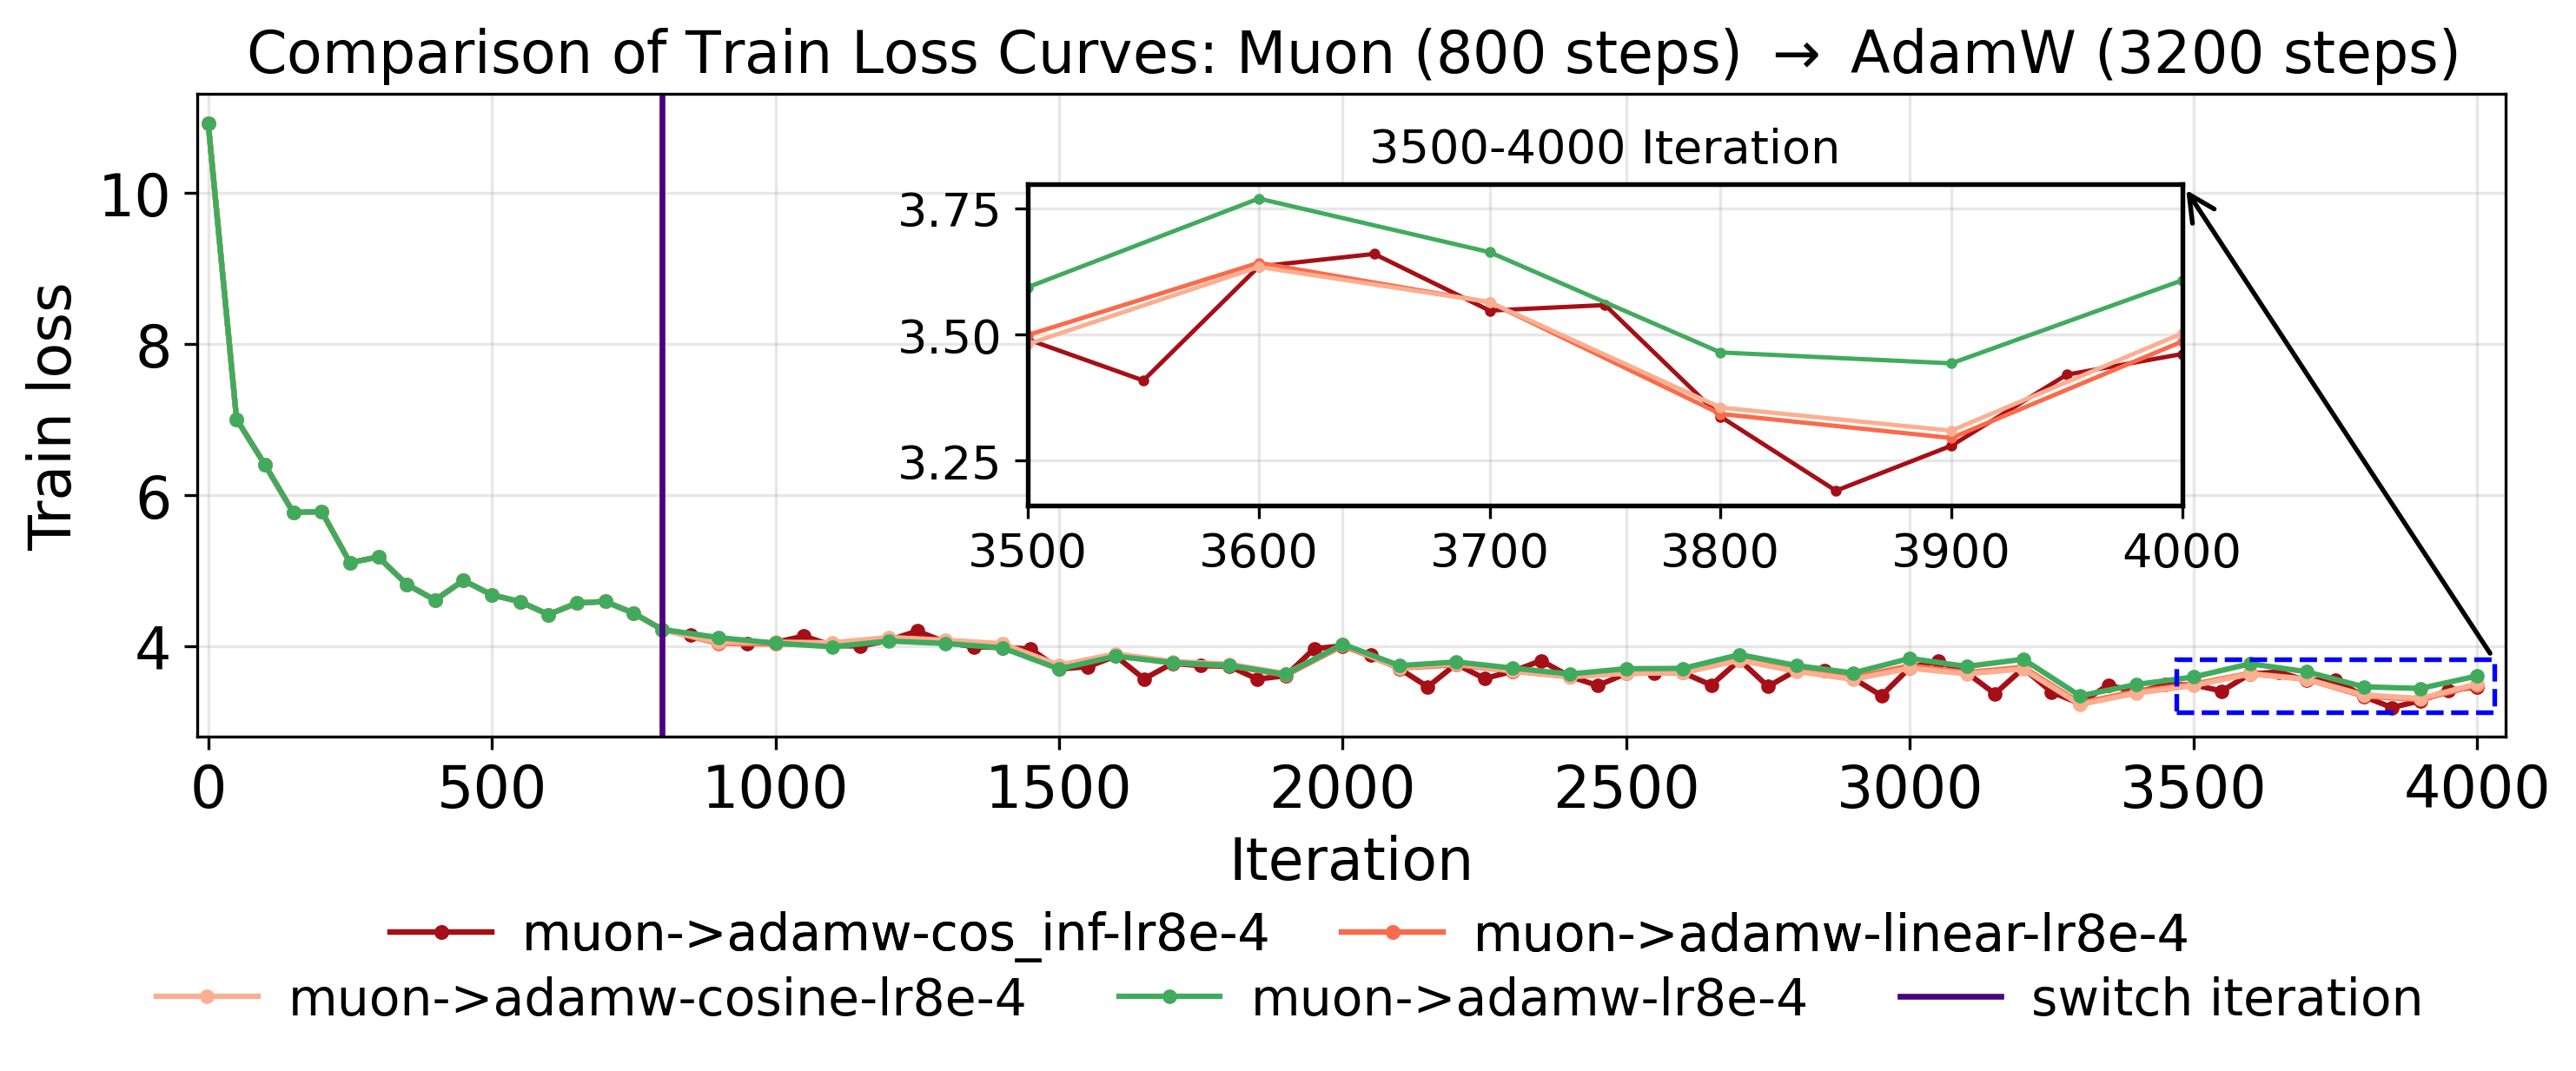

Saved figure to: llm_pretrain_lr_scheduler_muon800adamw3200_train.pdf


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr8e-4", "muon->adamw-linear-lr8e-4", "muon->adamw-cosine-lr8e-4", "muon->adamw-lr8e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon800", col_map_train[name], switch_iter, "train", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Train Loss Curves: Muon (800 steps) $\to$ AdamW (3200 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.36, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr8e-4", "muon->adamw-linear-lr8e-4", "muon->adamw-cosine-lr8e-4", "muon->adamw-lr8e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon800", col_map_train[name], switch_iter, "train", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon800", col_map_train["muon->adamw-cos_inf-lr8e-4"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon800", col_map_train["muon->adamw-linear-lr8e-4"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon800", col_map_train["muon->adamw-cosine-lr8e-4"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon800", col_map_train["muon->adamw-lr8e-4"], switch_iter, "train", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.0, 1.0),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr8e-4", "muon->adamw-linear-lr8e-4"]
row2 = ["muon->adamw-cosine-lr8e-4", "muon->adamw-lr8e-4", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon800adamw3200_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon800adamw3200_train.pdf")
plt.close()

### Experiment0 result of val loss curves: Muon (800 steps) $\to$ AdamW (3200 steps)

In [6]:
csv_path = "llm_pretrain_lr_scheduler/800muon+3200adamw-val.csv"
df = pd.read_csv(csv_path)
print(df.columns)
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon800_series = df[[x_col, col_map_val["muon800"]]].dropna()
if muon800_series.empty:
    raise ValueError("Column 'muon800 - val/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon800_series[x_col].max())

Index(['iter', 'muon+adamwcos--lr8e-4 - val/loss',
       'muon+adamwcos--lr8e-4 - val/loss__MIN',
       'muon+adamwcos--lr8e-4 - val/loss__MAX',
       'muon+adamwcos--lr8e-4 - _step', 'muon+adamwcos--lr8e-4 - _step__MIN',
       'muon+adamwcos--lr8e-4 - _step__MAX',
       'muon+adamwcos_inf--lr8e-4 - val/loss',
       'muon+adamwcos_inf--lr8e-4 - val/loss__MIN',
       'muon+adamwcos_inf--lr8e-4 - val/loss__MAX',
       'muon+adamwcos_inf--lr8e-4 - _step',
       'muon+adamwcos_inf--lr8e-4 - _step__MIN',
       'muon+adamwcos_inf--lr8e-4 - _step__MAX',
       'muon+adamwlinear--lr8e-4 - val/loss',
       'muon+adamwlinear--lr8e-4 - val/loss__MIN',
       'muon+adamwlinear--lr8e-4 - val/loss__MAX',
       'muon+adamwlinear--lr8e-4 - _step',
       'muon+adamwlinear--lr8e-4 - _step__MIN',
       'muon+adamwlinear--lr8e-4 - _step__MAX',
       'muon+adamw--lr8e-4 - val/loss', 'muon+adamw--lr8e-4 - val/loss__MIN',
       'muon+adamw--lr8e-4 - val/loss__MAX', 'muon+adamw--lr8e-4 - _step

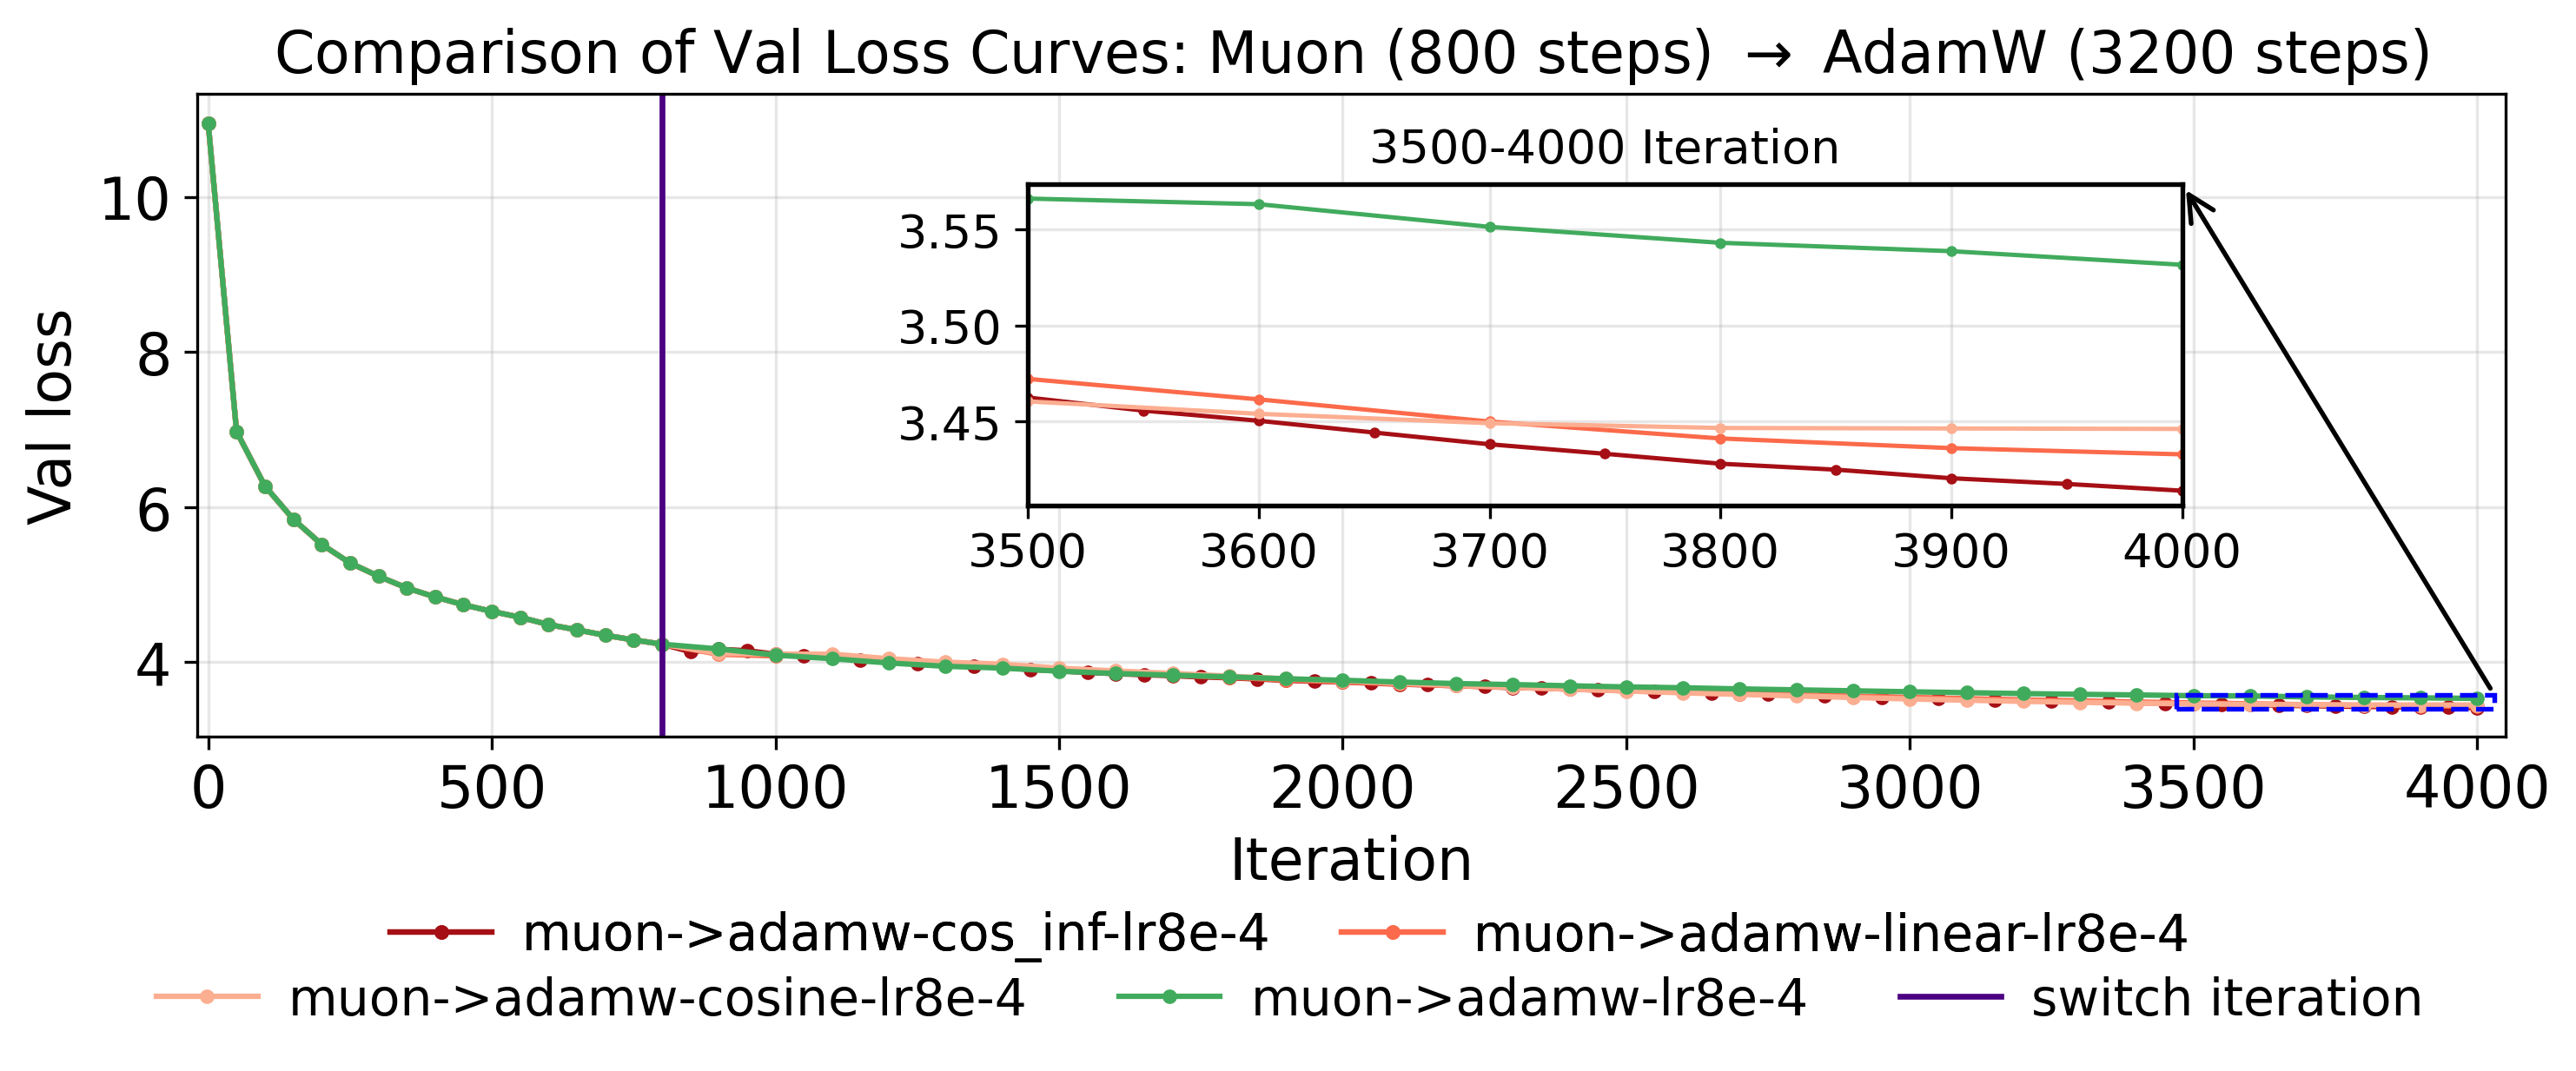

Saved figure to: llm_pretrain_lr_scheduler_muon800adamw3200_val.pdf


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr8e-4", "muon->adamw-linear-lr8e-4", "muon->adamw-cosine-lr8e-4", "muon->adamw-lr8e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon800", col_map_val[name], switch_iter, "val", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Val Loss Curves: Muon (800 steps) $\to$ AdamW (3200 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Val loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.36, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr8e-4", "muon->adamw-linear-lr8e-4", "muon->adamw-cosine-lr8e-4", "muon->adamw-lr8e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon800", col_map_val[name], switch_iter, "val", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon800", col_map_val["muon->adamw-cos_inf-lr8e-4"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon800", col_map_val["muon->adamw-linear-lr8e-4"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon800", col_map_val["muon->adamw-cosine-lr8e-4"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon800", col_map_val["muon->adamw-lr8e-4"], switch_iter, "val", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.0, 1.0),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr8e-4", "muon->adamw-linear-lr8e-4"]
row2 = ["muon->adamw-cosine-lr8e-4", "muon->adamw-lr8e-4", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon800adamw3200_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon800adamw3200_val.pdf")
plt.close()

### Experiment1 result of train loss curves: Muon (1000 steps) $\to$ AdamW (3000 steps)

In [8]:
csv_path = "llm_pretrain_lr_scheduler/1000muon+3000adamw-train.csv"
df = pd.read_csv(csv_path)

# Make sure the x-axis column is numeric
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")

# ===== 1. Determine the switch iteration =====
# We treat "muon1000" as the pre-switch phase of the hybrid run.
# The switch iteration is defined as the last iteration where muon1000 has a valid loss.
muon1000_series = df[[x_col, col_map_train["muon1000"]]].dropna()
if muon1000_series.empty:
    raise ValueError("Column 'muon1000 - train/loss' has no data; cannot determine switch iteration.")

switch_iter = int(muon1000_series[x_col].max())

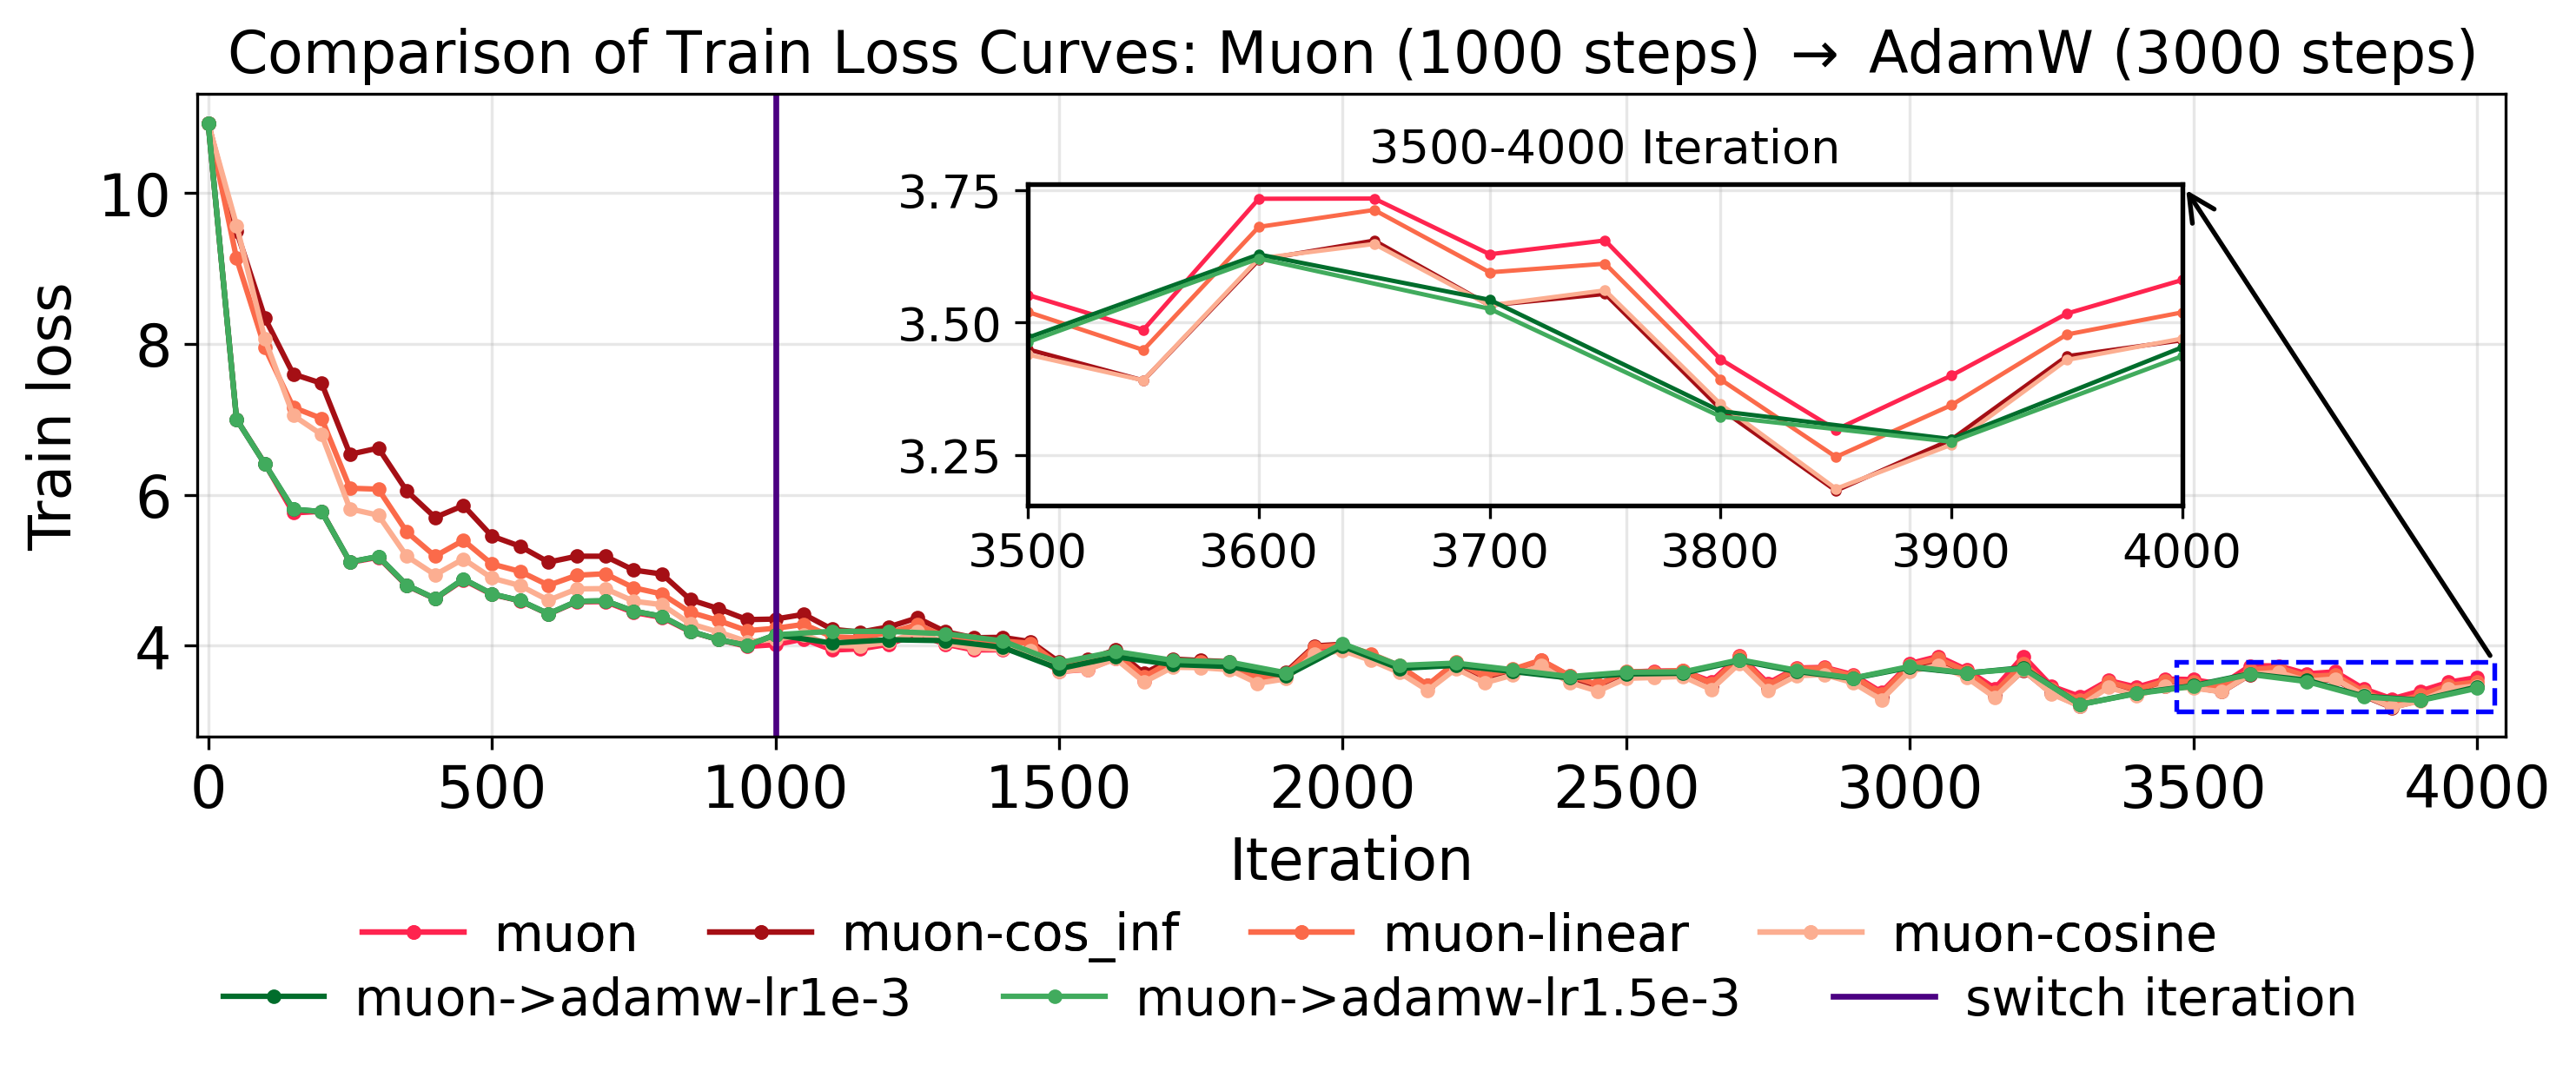

Saved figure to: llm_pretrain_lr_scheduler_muon1000adamw3000_train.pdf


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))

# Plot the non-hybrid algorithms
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_train[name])
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])

# Plot the hybrid algorithms (concatenated curves)
x1, y1 = get_hybrid_curve(df, x_col, "muon1000", col_map_train["muon->adamw-lr1e-3"], switch_iter, "train", keep="post")
ax.plot(x1, y1, marker="o", markersize=3, linewidth=1.5, 
        label="muon->adamw-lr1e-3", color=colors["muon->adamw-lr1e-3"])

x2, y2 = get_hybrid_curve(df, x_col, "muon1000", col_map_train["muon->adamw-lr1.5e-3"], switch_iter, "train", keep="post")
ax.plot(x2, y2, marker="o", markersize=3, linewidth=1.5,
        label="muon->adamw-lr1.5e-3", color=colors["muon->adamw-lr1.5e-3"])

# Draw the vertical switch line (shown once in the legend)
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")

ax.set_title(rf"Comparison of Train Loss Curves: Muon (1000 steps) $\to$ AdamW (3000 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)

# Create the inset axes (zoom into the last ~500 iters)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter

axins = ax.inset_axes([0.36, 0.36, 0.50, 0.50])

# Plot all selected curves in the inset
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_train[name])
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)

plot_on(axins, "muon->adamw-lr1e-3", x1, y1, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1.5e-3", x2, y2, zoom_x0, zoom_x1)

axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
# axins.set_xlabel("Iteration", fontsize=9)
# axins.set_ylabel("Train loss", fontsize=9)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)

# Make the inset border thicker and black
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

# Draw a rectangle on the main plot showing the inset region
# Compute the y-range for the inset window using all plotted curves
all_inset_vals = []
for x, y in [
    get_curve(df, x_col, col_map_train["muon"]),
    get_curve(df, x_col, col_map_train["muon-cos_inf"]),
    get_curve(df, x_col, col_map_train["muon-linear"]),
    get_curve(df, x_col, col_map_train["muon-cosine"]),
    (x1, y1),
    (x2, y2),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])

vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin

# Slightly expand the rectangle beyond the zoom region for aesthetics
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin

rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)

# Add an arrow from the rectangle to the inset axes
# clip_on=False helps avoid rare internal clipping/path issues
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.0, 1.0),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)

fig.tight_layout()
fig.subplots_adjust(bottom=0.28)

# Process Legend: 2 rows at the bottom of the whole figure
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]
row2 = ["muon->adamw-lr1e-3", "muon->adamw-lr1.5e-3", "switch iteration"]
# First row (4 items)
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
# Second row (3 items)
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)

plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon1000adamw3000_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon1000adamw3000_train.pdf")
plt.close()

### Experiment1 result of val loss curves: Muon (1000 steps) $\to$ AdamW (3000 steps)

In [10]:
csv_path = "llm_pretrain_lr_scheduler/1000muon+3000adamw-val.csv"
df = pd.read_csv(csv_path)
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon1000_series = df[[x_col, col_map_val["muon1000"]]].dropna()
if muon1000_series.empty:
    raise ValueError("Column 'muon1000 - val/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon1000_series[x_col].max())

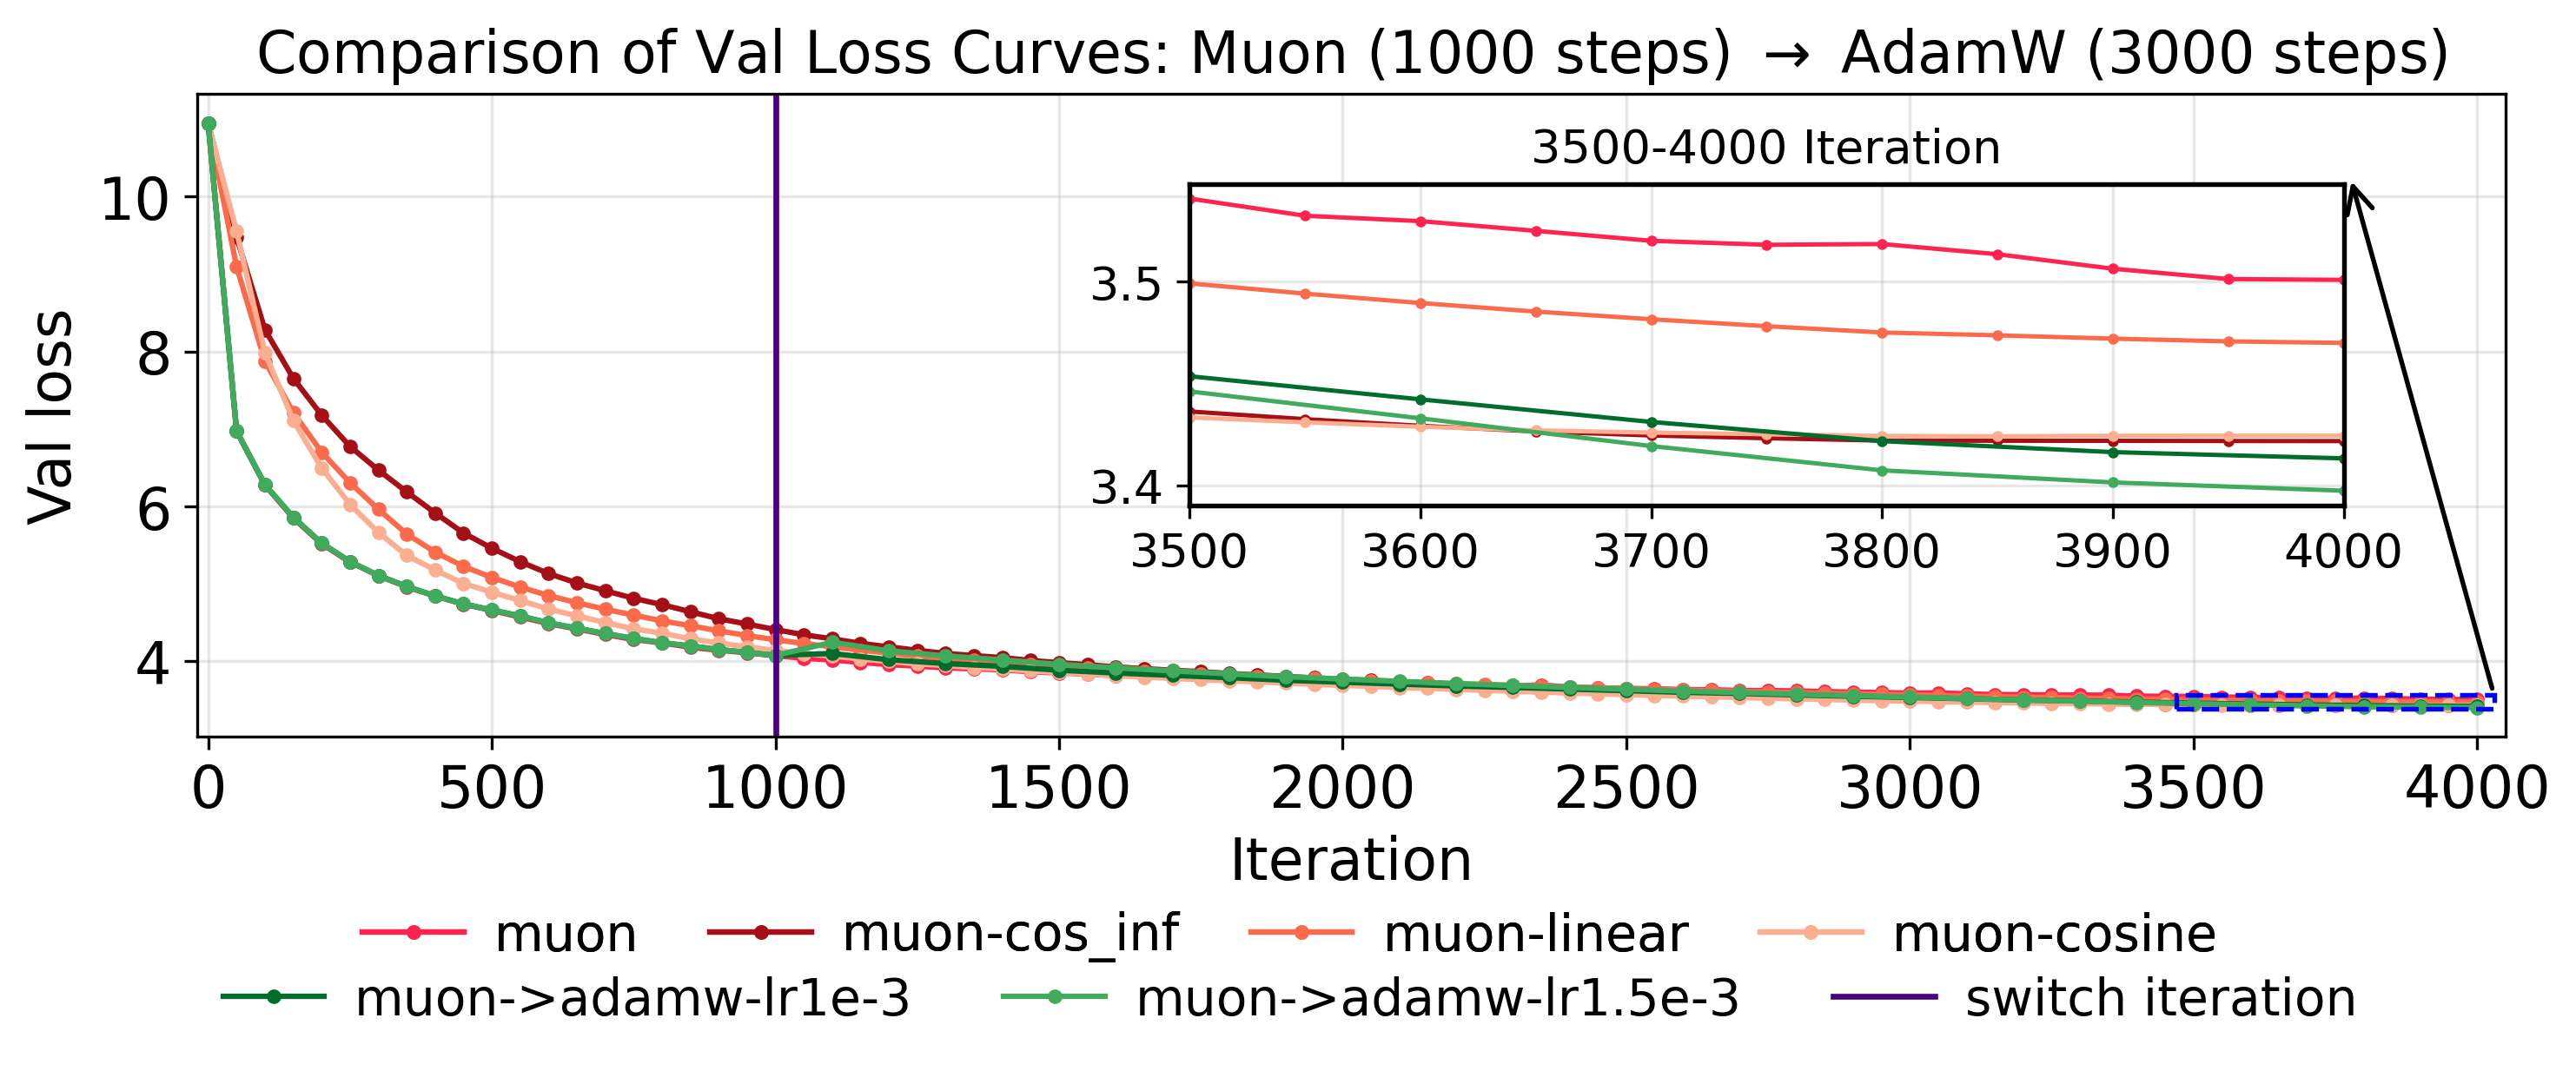

Saved figure to: llm_pretrain_lr_scheduler_muon1000adamw3000_val.pdf


In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_val[name])
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
x1, y1 = get_hybrid_curve(df, x_col, "muon1000", col_map_val["muon->adamw-lr1e-3"], switch_iter, "val", keep="post")
ax.plot(x1, y1, marker="o", markersize=3, linewidth=1.5, 
        label="muon->adamw-lr1e-3", color=colors["muon->adamw-lr1e-3"])
x2, y2 = get_hybrid_curve(df, x_col, "muon1000", col_map_val["muon->adamw-lr1.5e-3"], switch_iter, "val", keep="post")
ax.plot(x2, y2, marker="o", markersize=3, linewidth=1.5, 
        label="muon->adamw-lr1.5e-3", color=colors["muon->adamw-lr1.5e-3"])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Val Loss Curves: Muon (1000 steps) $\to$ AdamW (3000 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Val loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_val[name])
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1e-3", x1, y1, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1.5e-3", x2, y2, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_curve(df, x_col, col_map_val["muon"]),
    get_curve(df, x_col, col_map_val["muon-cos_inf"]),
    get_curve(df, x_col, col_map_val["muon-linear"]),
    get_curve(df, x_col, col_map_val["muon-cosine"]),
    (x1, y1),
    (x2, y2),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.005, 1.03),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]
row2 = ["muon->adamw-lr1e-3", "muon->adamw-lr1.5e-3", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon1000adamw3000_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon1000adamw3000_val.pdf")
plt.close()

### Experiment2 result of train loss curves: Muon (1500 steps) $\to$ AdamW (2500 steps)

In [12]:
csv_path = "llm_pretrain_lr_scheduler/1500muon+2500adamw-train.csv"
df = pd.read_csv(csv_path)
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon1500_series = df[[x_col, col_map_train["muon1500"]]].dropna()
if muon1500_series.empty:
    raise ValueError("Column 'muon1500 - train/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon1500_series[x_col].max())

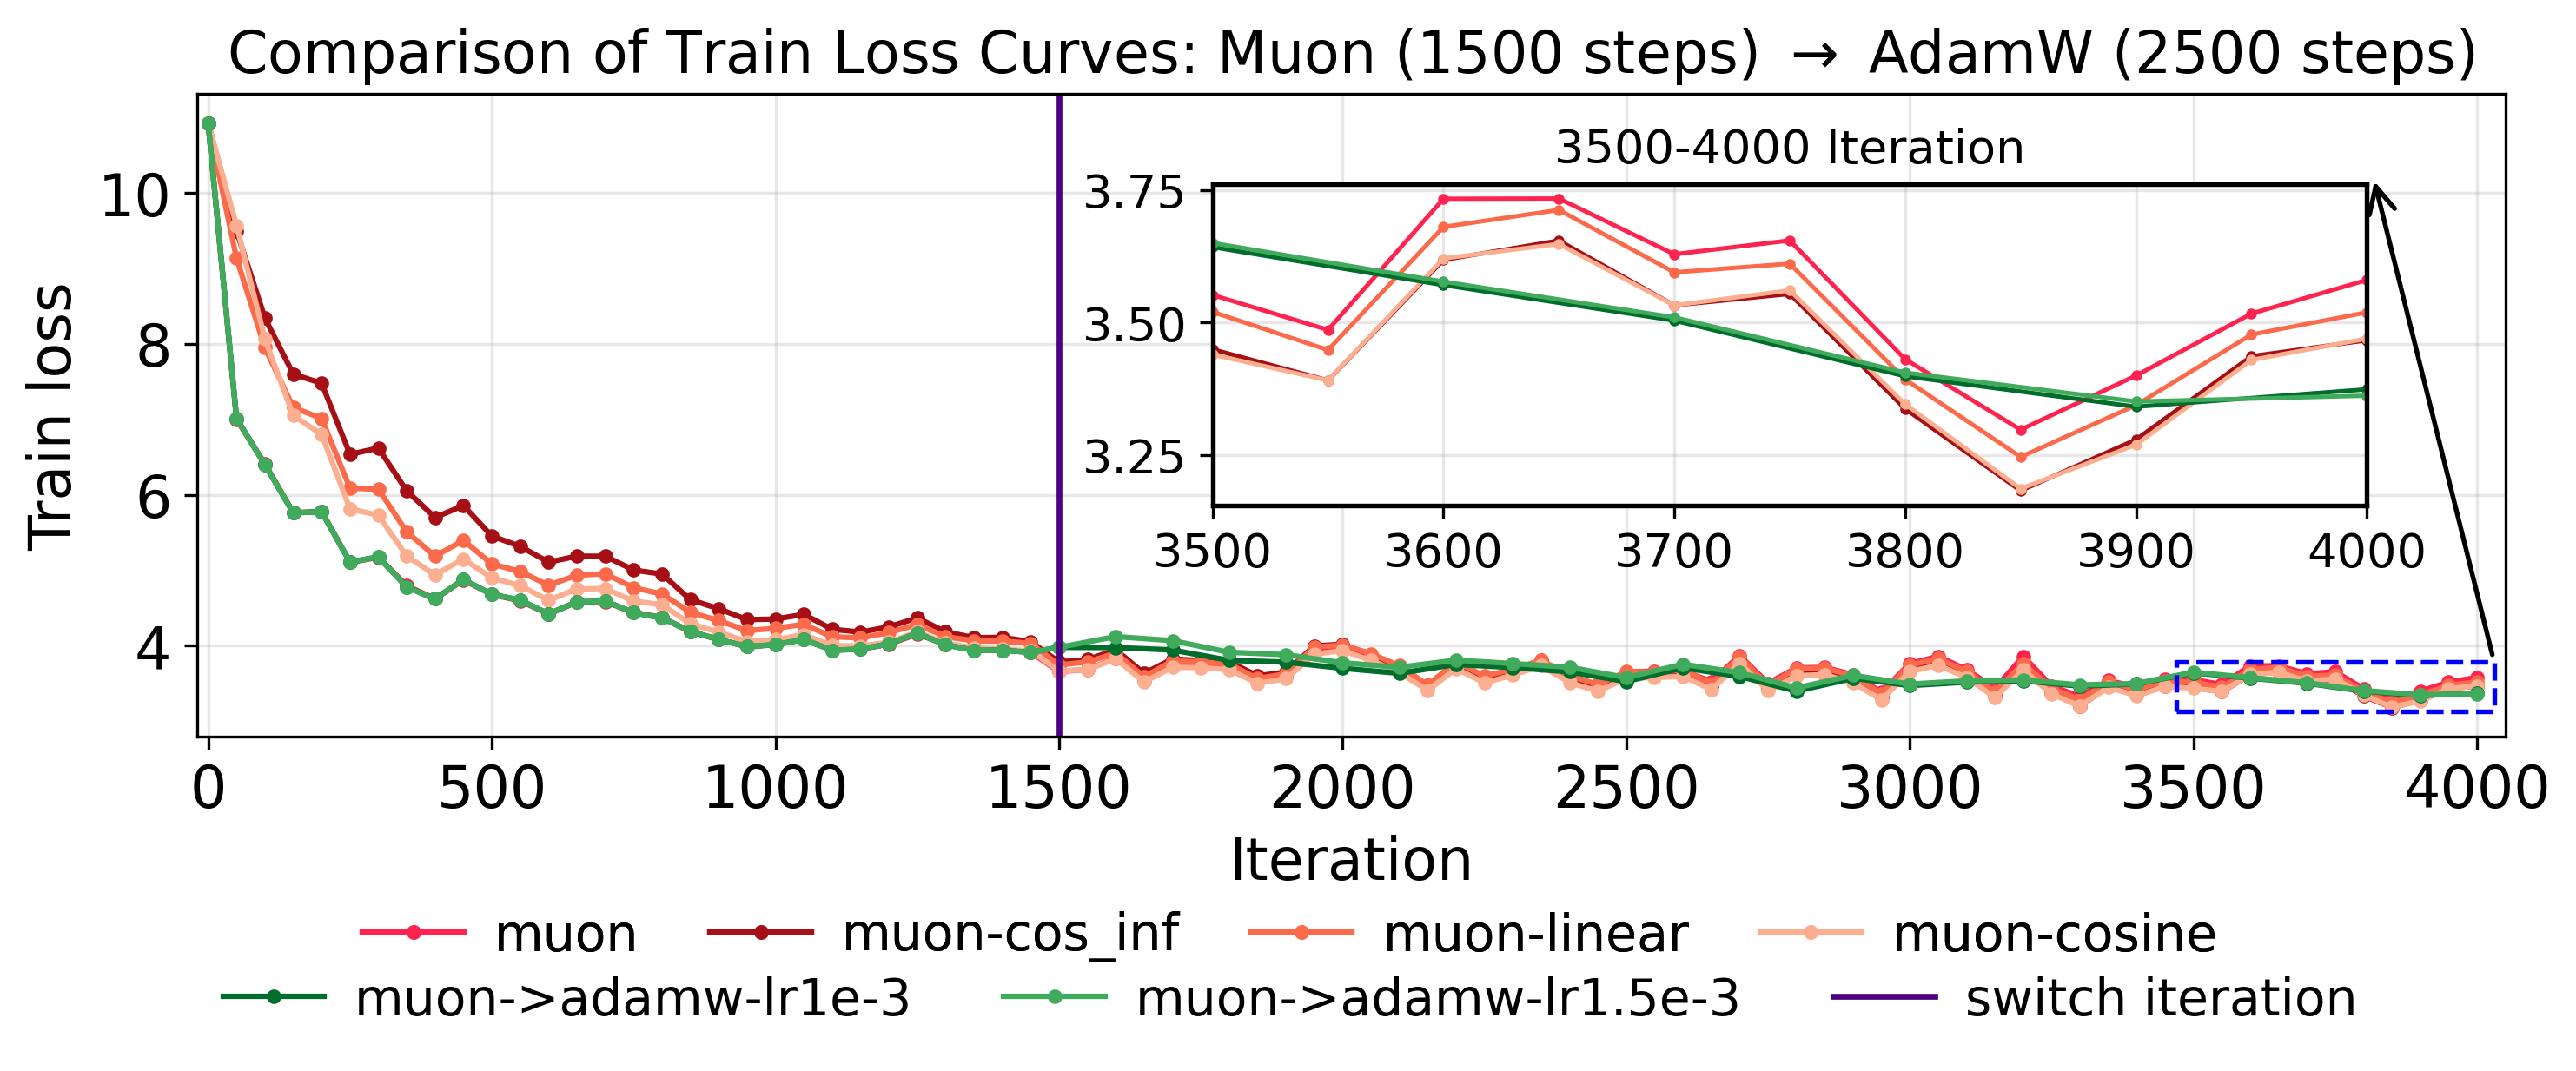

Saved figure to: llm_pretrain_lr_scheduler_muon1500adamw2500_train.pdf


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_train[name])
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
x1, y1 = get_hybrid_curve(df, x_col, "muon1500", col_map_train["muon->adamw-lr1e-3"], switch_iter, "train", keep="post")
ax.plot(x1, y1, marker="o", markersize=3, linewidth=1.5, 
        label="muon->adamw-lr1e-3", color=colors["muon->adamw-lr1e-3"])
x2, y2 = get_hybrid_curve(df, x_col, "muon1500", col_map_train["muon->adamw-lr1.5e-3"], switch_iter, "train", keep="post")
ax.plot(x2, y2, marker="o", markersize=3, linewidth=1.5,
        label="muon->adamw-lr1.5e-3", color=colors["muon->adamw-lr1.5e-3"])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Train Loss Curves: Muon (1500 steps) $\to$ AdamW (2500 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.44, 0.36, 0.50, 0.50])
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_train[name])
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1e-3", x1, y1, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1.5e-3", x2, y2, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_curve(df, x_col, col_map_train["muon"]),
    get_curve(df, x_col, col_map_train["muon-cos_inf"]),
    get_curve(df, x_col, col_map_train["muon-linear"]),
    get_curve(df, x_col, col_map_train["muon-cosine"]),
    (x1, y1),
    (x2, y2),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.005, 1.03),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]
row2 = ["muon->adamw-lr1e-3", "muon->adamw-lr1.5e-3", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon1500adamw2500_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon1500adamw2500_train.pdf")
plt.close()

### Experiment2 result of val loss curves: Muon (1500 steps) $\to$ AdamW (2500 steps)

In [14]:
csv_path = "llm_pretrain_lr_scheduler/1500muon+2500adamw-val.csv"
df = pd.read_csv(csv_path)
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon1500_series = df[[x_col, col_map_val["muon1500"]]].dropna()
if muon1500_series.empty:
    raise ValueError("Column 'muon1500 - val/loss' has no data; cannot determine switch iteration.")

switch_iter = int(muon1500_series[x_col].max())

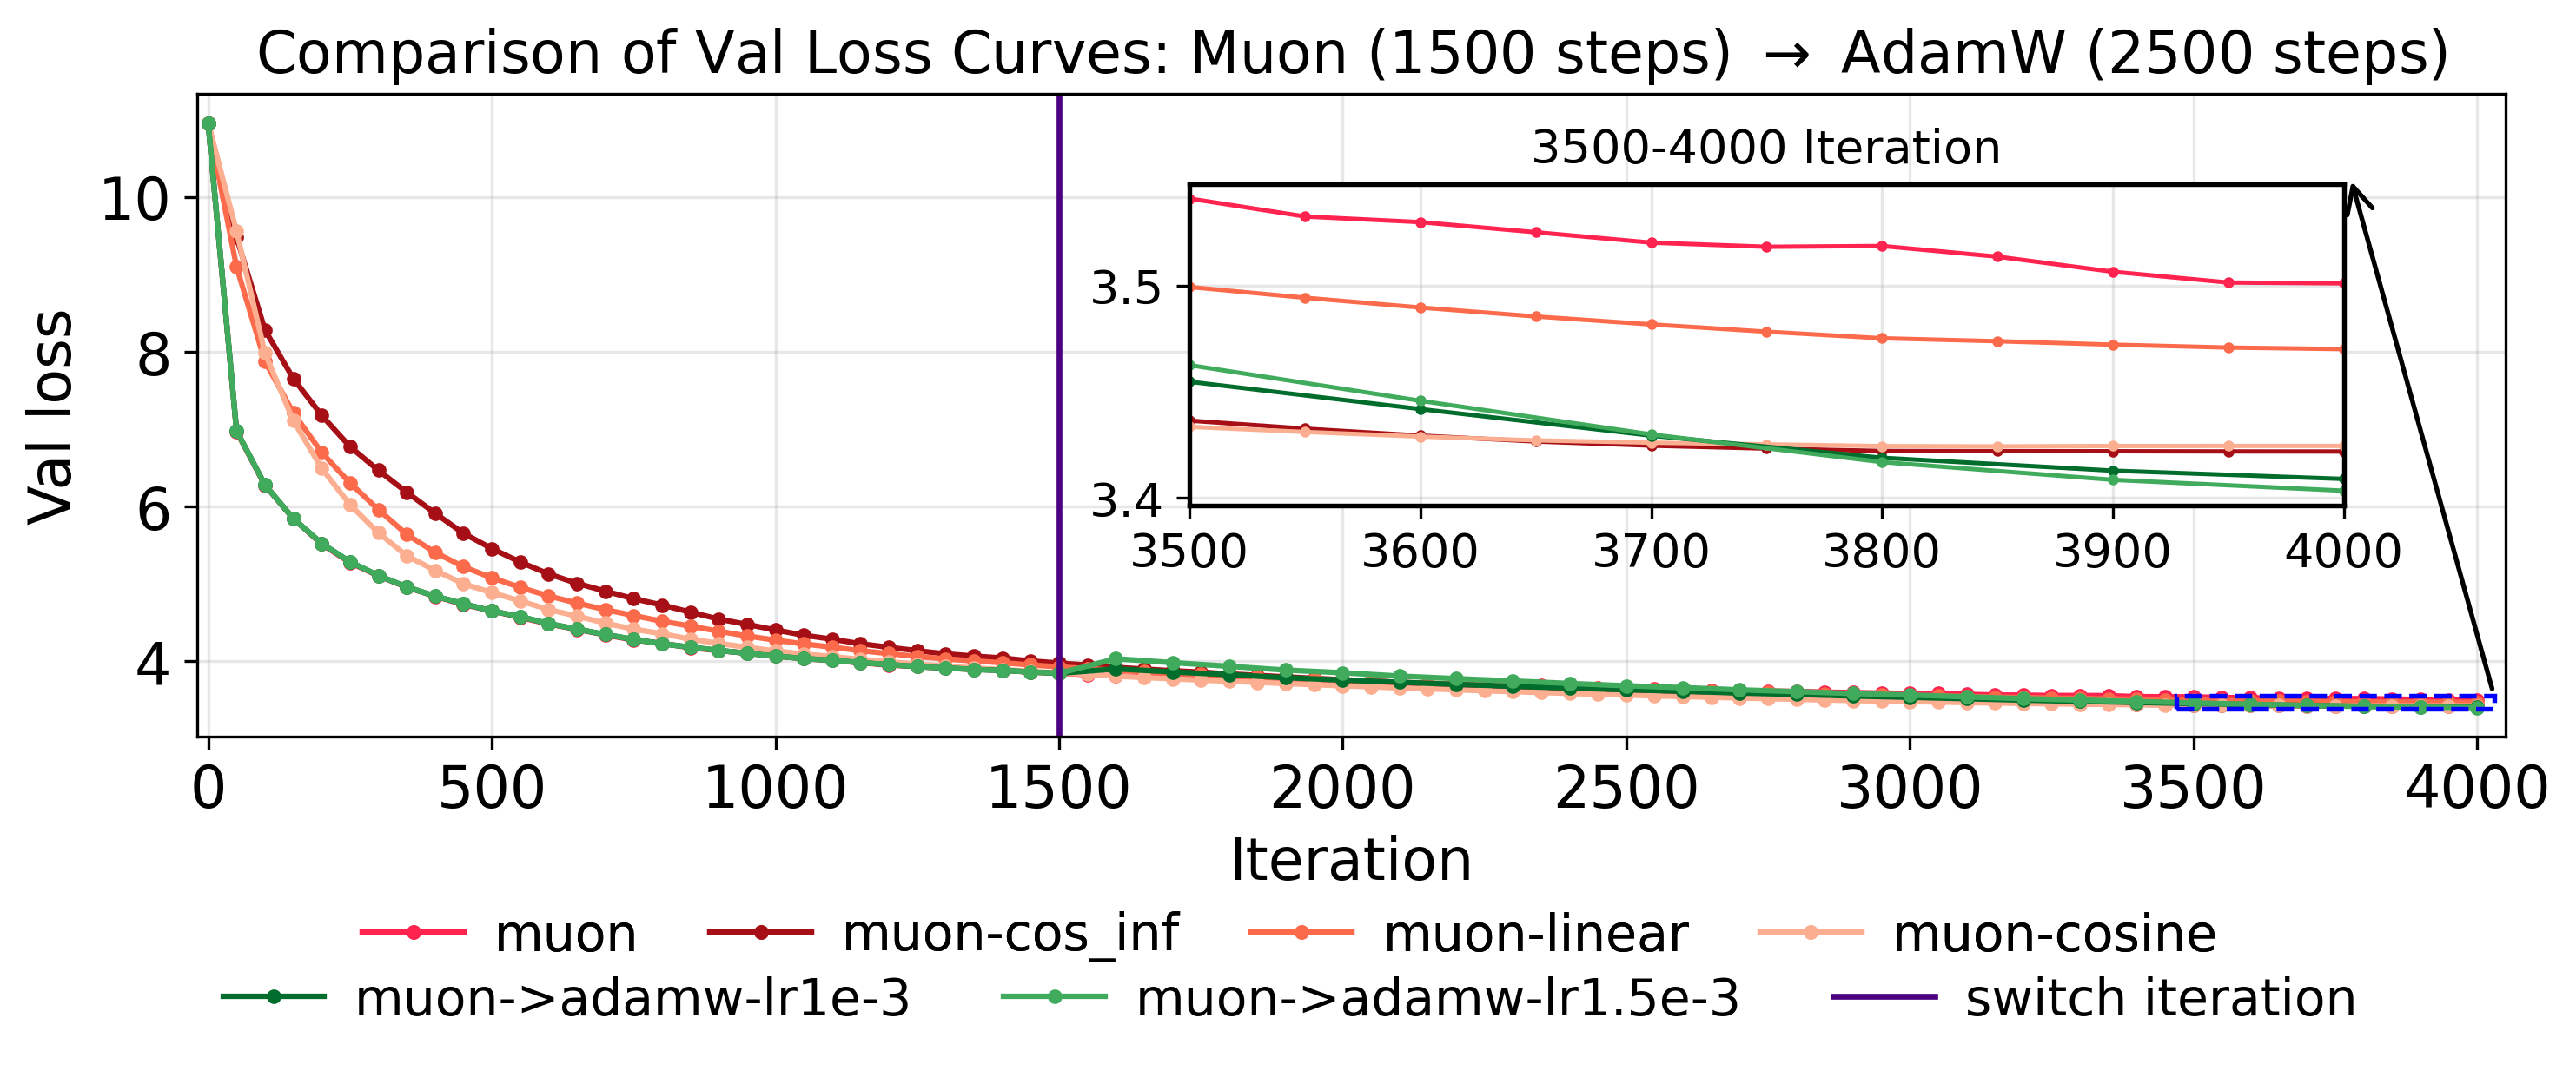

Saved figure to: llm_pretrain_lr_scheduler_muon1500adamw2500_val.pdf


In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_val[name])
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
x1, y1 = get_hybrid_curve(df, x_col, "muon1500", col_map_val["muon->adamw-lr1e-3"], switch_iter, "val", keep="post")
ax.plot(x1, y1, marker="o", markersize=3, linewidth=1.5, 
        label="muon->adamw-lr1e-3", color=colors["muon->adamw-lr1e-3"])
x2, y2 = get_hybrid_curve(df, x_col, "muon1500", col_map_val["muon->adamw-lr1.5e-3"], switch_iter, "val", keep="post")
ax.plot(x2, y2, marker="o", markersize=3, linewidth=1.5,
        label="muon->adamw-lr1.5e-3", color=colors["muon->adamw-lr1.5e-3"])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Val Loss Curves: Muon (1500 steps) $\to$ AdamW (2500 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Val loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])
for name in ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]:
    x, y = get_curve(df, x_col, col_map_val[name])
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1e-3", x1, y1, zoom_x0, zoom_x1)
plot_on(axins, "muon->adamw-lr1.5e-3", x2, y2, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_curve(df, x_col, col_map_val["muon"]),
    get_curve(df, x_col, col_map_val["muon-cos_inf"]),
    get_curve(df, x_col, col_map_val["muon-linear"]),
    get_curve(df, x_col, col_map_val["muon-cosine"]),
    (x1, y1),
    (x2, y2),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.005, 1.03),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon", "muon-cos_inf", "muon-linear", "muon-cosine"]
row2 = ["muon->adamw-lr1e-3", "muon->adamw-lr1.5e-3", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon1500adamw2500_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon1500adamw2500_val.pdf")
plt.close()

### Experiment3 result of train loss curves: Muon (2000 steps) $\to$ AdamW (2000 steps)

In [16]:
csv_path = "llm_pretrain_lr_scheduler/2000muon+2000adamw-train.csv"
df = pd.read_csv(csv_path)
#print(df.columns)  # different from the former two cases
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon2000_series = df[[x_col, col_map_train["muon2000"]]].dropna()
if muon2000_series.empty:
    raise ValueError("Column 'muon2000 - train/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon2000_series[x_col].max())

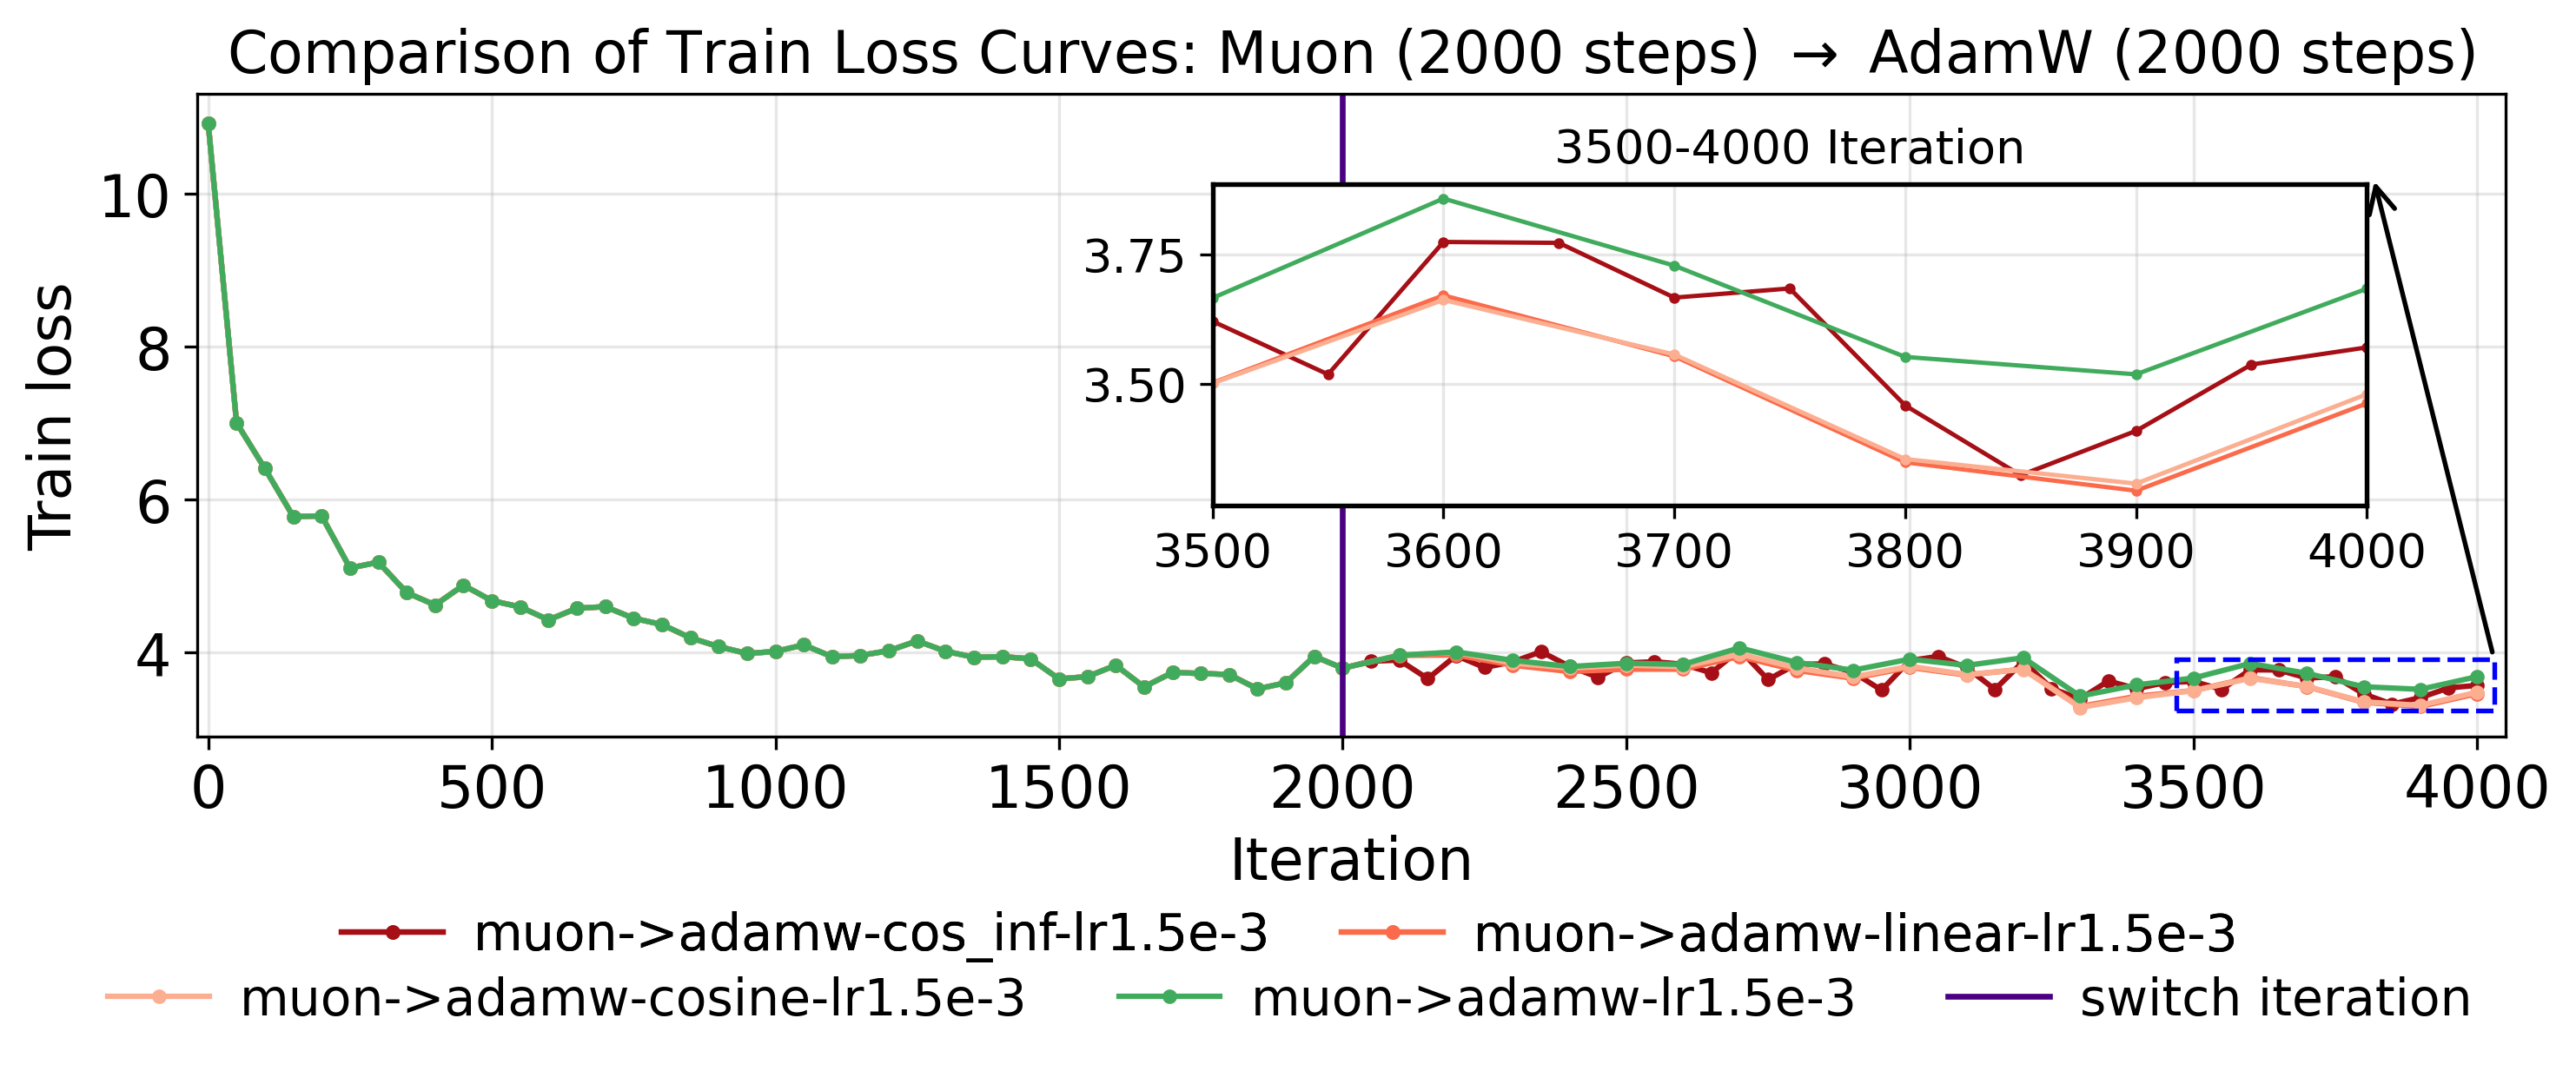

Saved figure to: llm_pretrain_lr_scheduler_muon2000adamw2000_train.pdf


In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr1.5e-3", "muon->adamw-linear-lr1.5e-3", "muon->adamw-cosine-lr1.5e-3", "muon->adamw-lr1.5e-3"]:
    x, y = get_hybrid_curve(df, x_col, "muon2000", col_map_train[name], switch_iter, "train", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Train Loss Curves: Muon (2000 steps) $\to$ AdamW (2000 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.44, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr1.5e-3", "muon->adamw-linear-lr1.5e-3", "muon->adamw-cosine-lr1.5e-3", "muon->adamw-lr1.5e-3"]:
    x, y = get_hybrid_curve(df, x_col, "muon2000", col_map_train[name], switch_iter, "train", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon2000", col_map_train["muon->adamw-cos_inf-lr1.5e-3"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon2000", col_map_train["muon->adamw-linear-lr1.5e-3"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon2000", col_map_train["muon->adamw-cosine-lr1.5e-3"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon2000", col_map_train["muon->adamw-lr1.5e-3"], switch_iter, "train", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.005, 1.03),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr1.5e-3", "muon->adamw-linear-lr1.5e-3"]
row2 = ["muon->adamw-cosine-lr1.5e-3", "muon->adamw-lr1.5e-3", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon2000adamw2000_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon2000adamw2000_train.pdf")
plt.close()

### Experiment3 result of val loss curves: Muon (2000 steps) $\to$ AdamW (2000 steps)

In [18]:
csv_path = "llm_pretrain_lr_scheduler/2000muon+2000adamw-val.csv"
df = pd.read_csv(csv_path)
#print(df.columns)  # different from the former two cases
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon2000_series = df[[x_col, col_map_val["muon2000"]]].dropna()
if muon2000_series.empty:
    raise ValueError("Column 'muon2000 - val/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon2000_series[x_col].max())

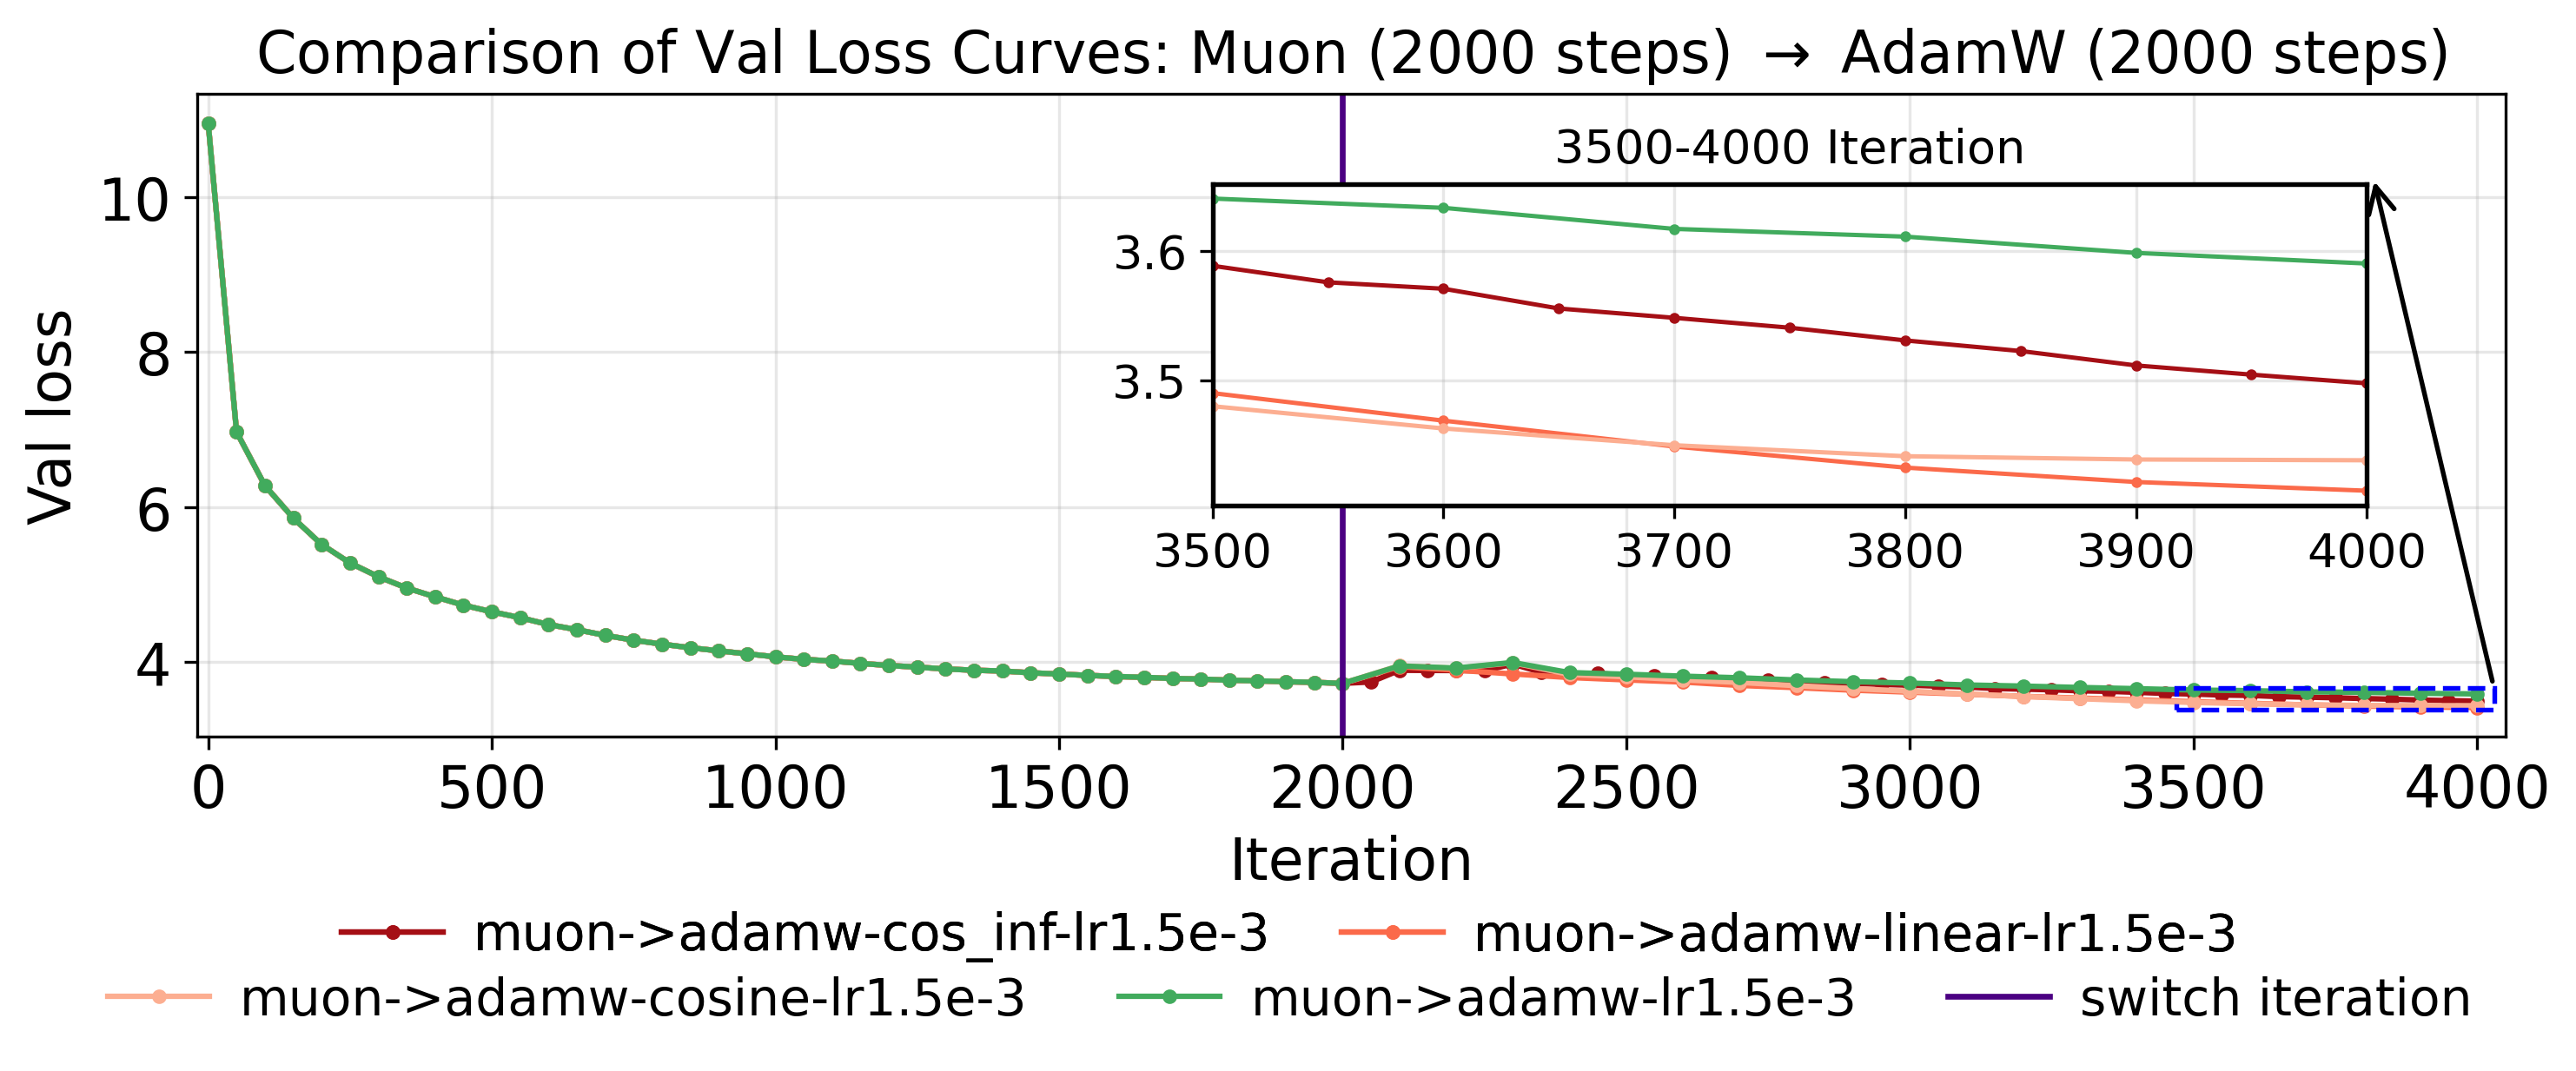

Saved figure to: llm_pretrain_lr_scheduler_muon2000adamw2000_val.pdf


In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr1.5e-3", "muon->adamw-linear-lr1.5e-3", "muon->adamw-cosine-lr1.5e-3", "muon->adamw-lr1.5e-3"]:
    x, y = get_hybrid_curve(df, x_col, "muon2000", col_map_val[name], switch_iter, "val", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Val Loss Curves: Muon (2000 steps) $\to$ AdamW (2000 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Val loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.44, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr1.5e-3", "muon->adamw-linear-lr1.5e-3", "muon->adamw-cosine-lr1.5e-3", "muon->adamw-lr1.5e-3"]:
    x, y = get_hybrid_curve(df, x_col, "muon2000", col_map_val[name], switch_iter, "val", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon2000", col_map_val["muon->adamw-cos_inf-lr1.5e-3"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon2000", col_map_val["muon->adamw-linear-lr1.5e-3"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon2000", col_map_val["muon->adamw-cosine-lr1.5e-3"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon2000", col_map_val["muon->adamw-lr1.5e-3"], switch_iter, "val", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(1.005, 1.03),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr1.5e-3", "muon->adamw-linear-lr1.5e-3"]
row2 = ["muon->adamw-cosine-lr1.5e-3", "muon->adamw-lr1.5e-3", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon2000adamw2000_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon2000adamw2000_val.pdf")
plt.close()

### Experiment4 result of train loss curves: Muon (3000 steps) $\to$ AdamW (1000 steps)

In [20]:
csv_path = "llm_pretrain_lr_scheduler/3000muon+1000adamw-train.csv"
df = pd.read_csv(csv_path)
#print(df.columns)  # different from the former two cases
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon3000_series = df[[x_col, col_map_train["muon3000"]]].dropna()
if muon3000_series.empty:
    raise ValueError("Column 'muon3000 - train/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon3000_series[x_col].max())

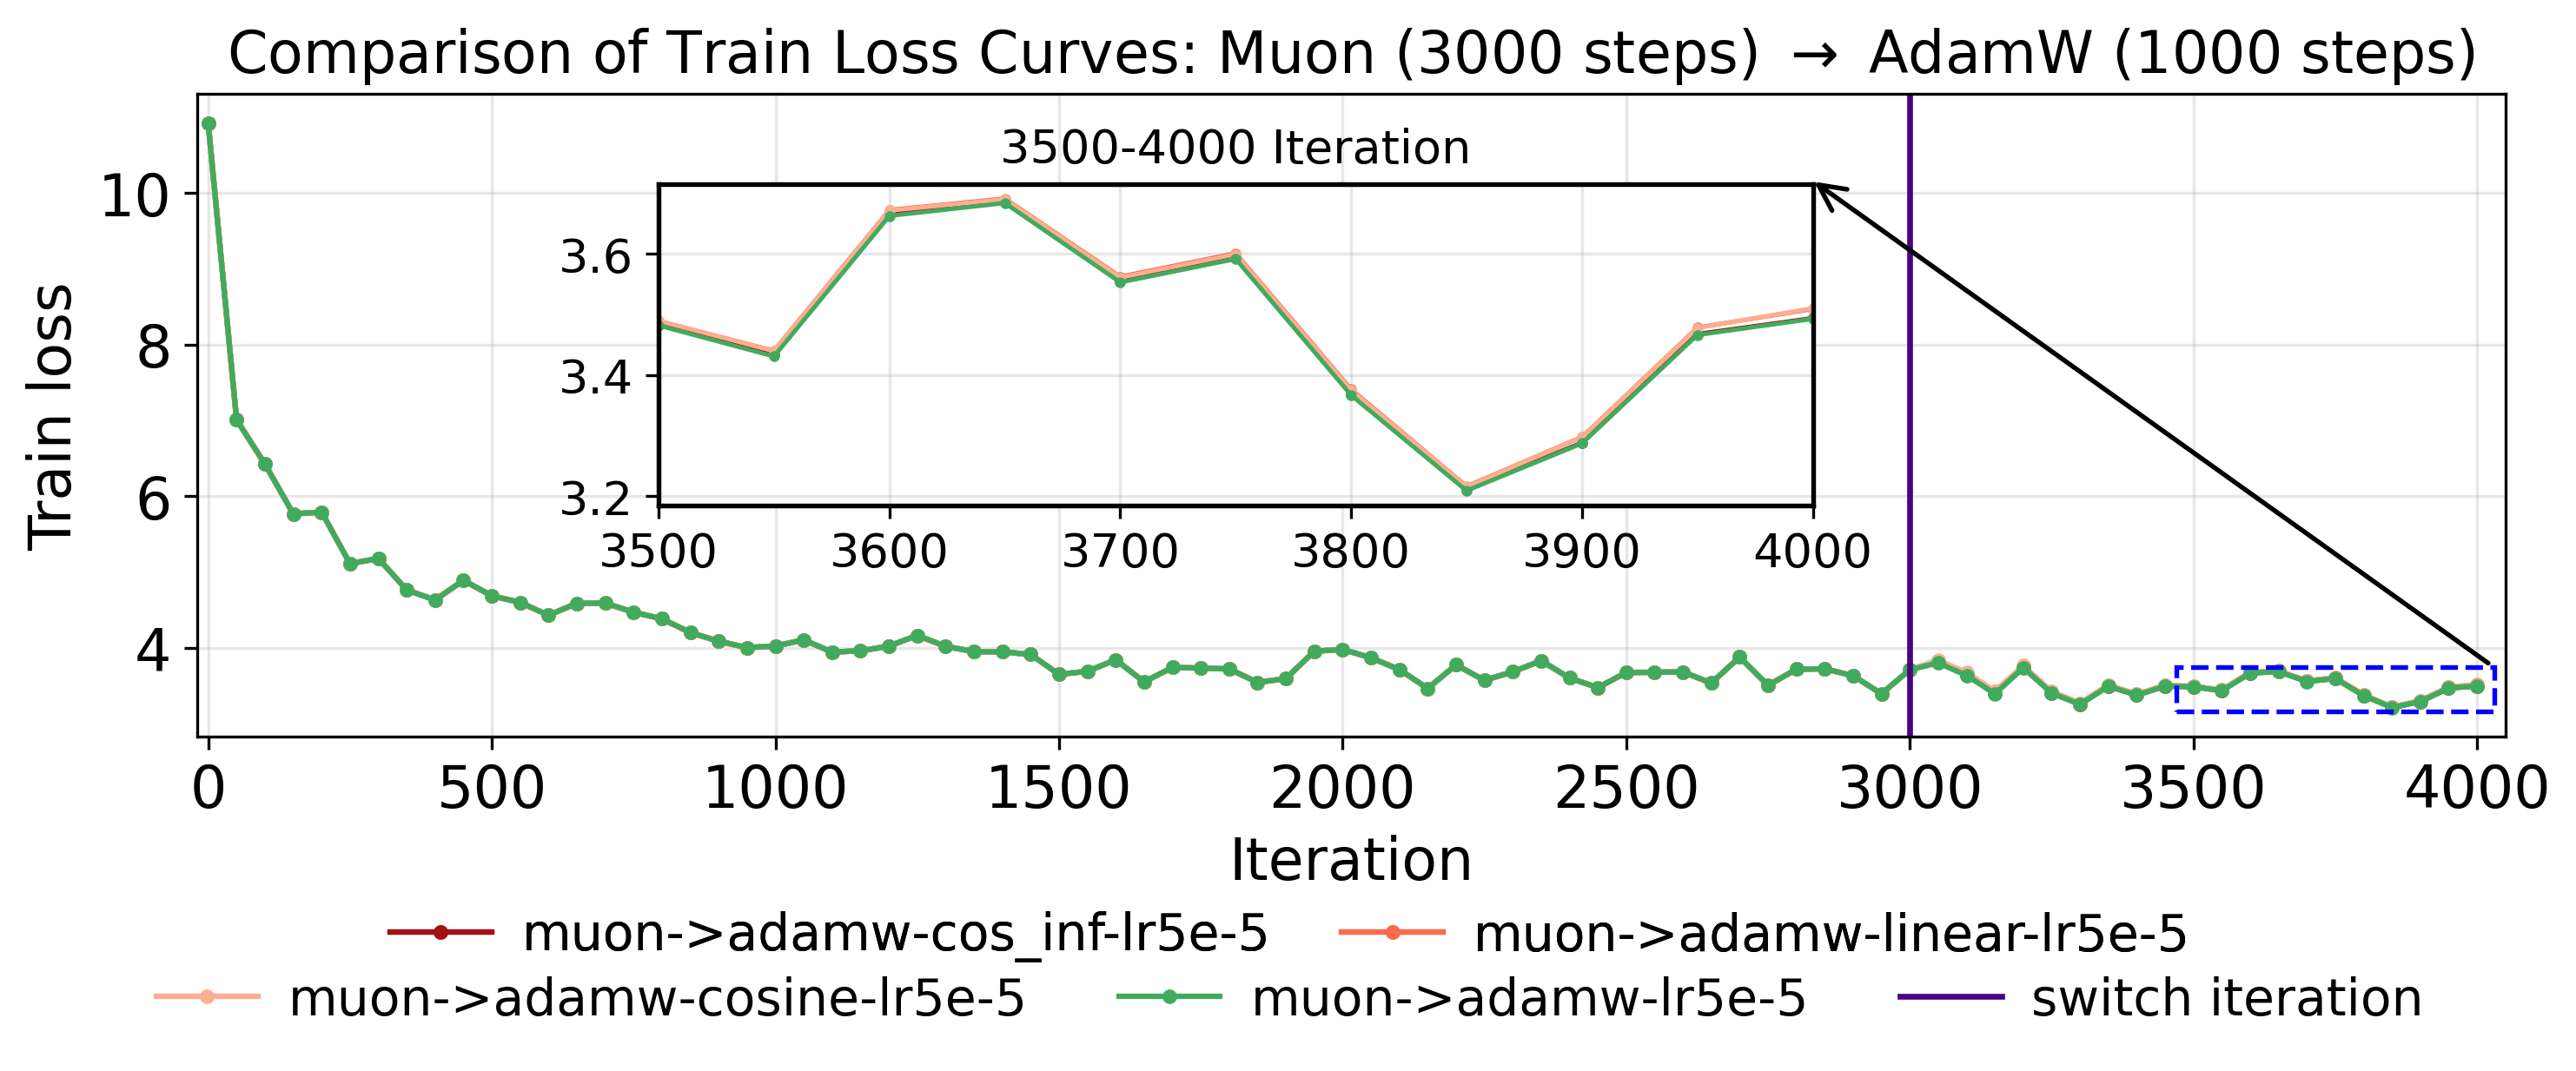

Saved figure to: llm_pretrain_lr_scheduler_muon3000adamw1000_train.pdf


In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr5e-5", "muon->adamw-linear-lr5e-5", "muon->adamw-cosine-lr5e-5", "muon->adamw-lr5e-5"]:
    x, y = get_hybrid_curve(df, x_col, "muon3000", col_map_train[name], switch_iter, "train", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Train Loss Curves: Muon (3000 steps) $\to$ AdamW (1000 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.20, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr5e-5", "muon->adamw-linear-lr5e-5", "muon->adamw-cosine-lr5e-5", "muon->adamw-lr5e-5"]:
    x, y = get_hybrid_curve(df, x_col, "muon3000", col_map_train[name], switch_iter, "train", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon3000", col_map_train["muon->adamw-cos_inf-lr5e-5"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon3000", col_map_train["muon->adamw-linear-lr5e-5"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon3000", col_map_train["muon->adamw-cosine-lr5e-5"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon3000", col_map_train["muon->adamw-lr5e-5"], switch_iter, "train", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(0.996, 1.02),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr5e-5", "muon->adamw-linear-lr5e-5"]
row2 = ["muon->adamw-cosine-lr5e-5", "muon->adamw-lr5e-5", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon3000adamw1000_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon3000adamw1000_train.pdf")
plt.close()

### Experiment4 result of val loss curves: Muon (3000 steps) $\to$ AdamW (1000 steps)

In [22]:
csv_path = "llm_pretrain_lr_scheduler/3000muon+1000adamw-val.csv"
df = pd.read_csv(csv_path)
#print(df.columns)  # different from the former two cases
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon3000_series = df[[x_col, col_map_val["muon3000"]]].dropna()
if muon3000_series.empty:
    raise ValueError("Column 'muon3000 - val/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon3000_series[x_col].max())

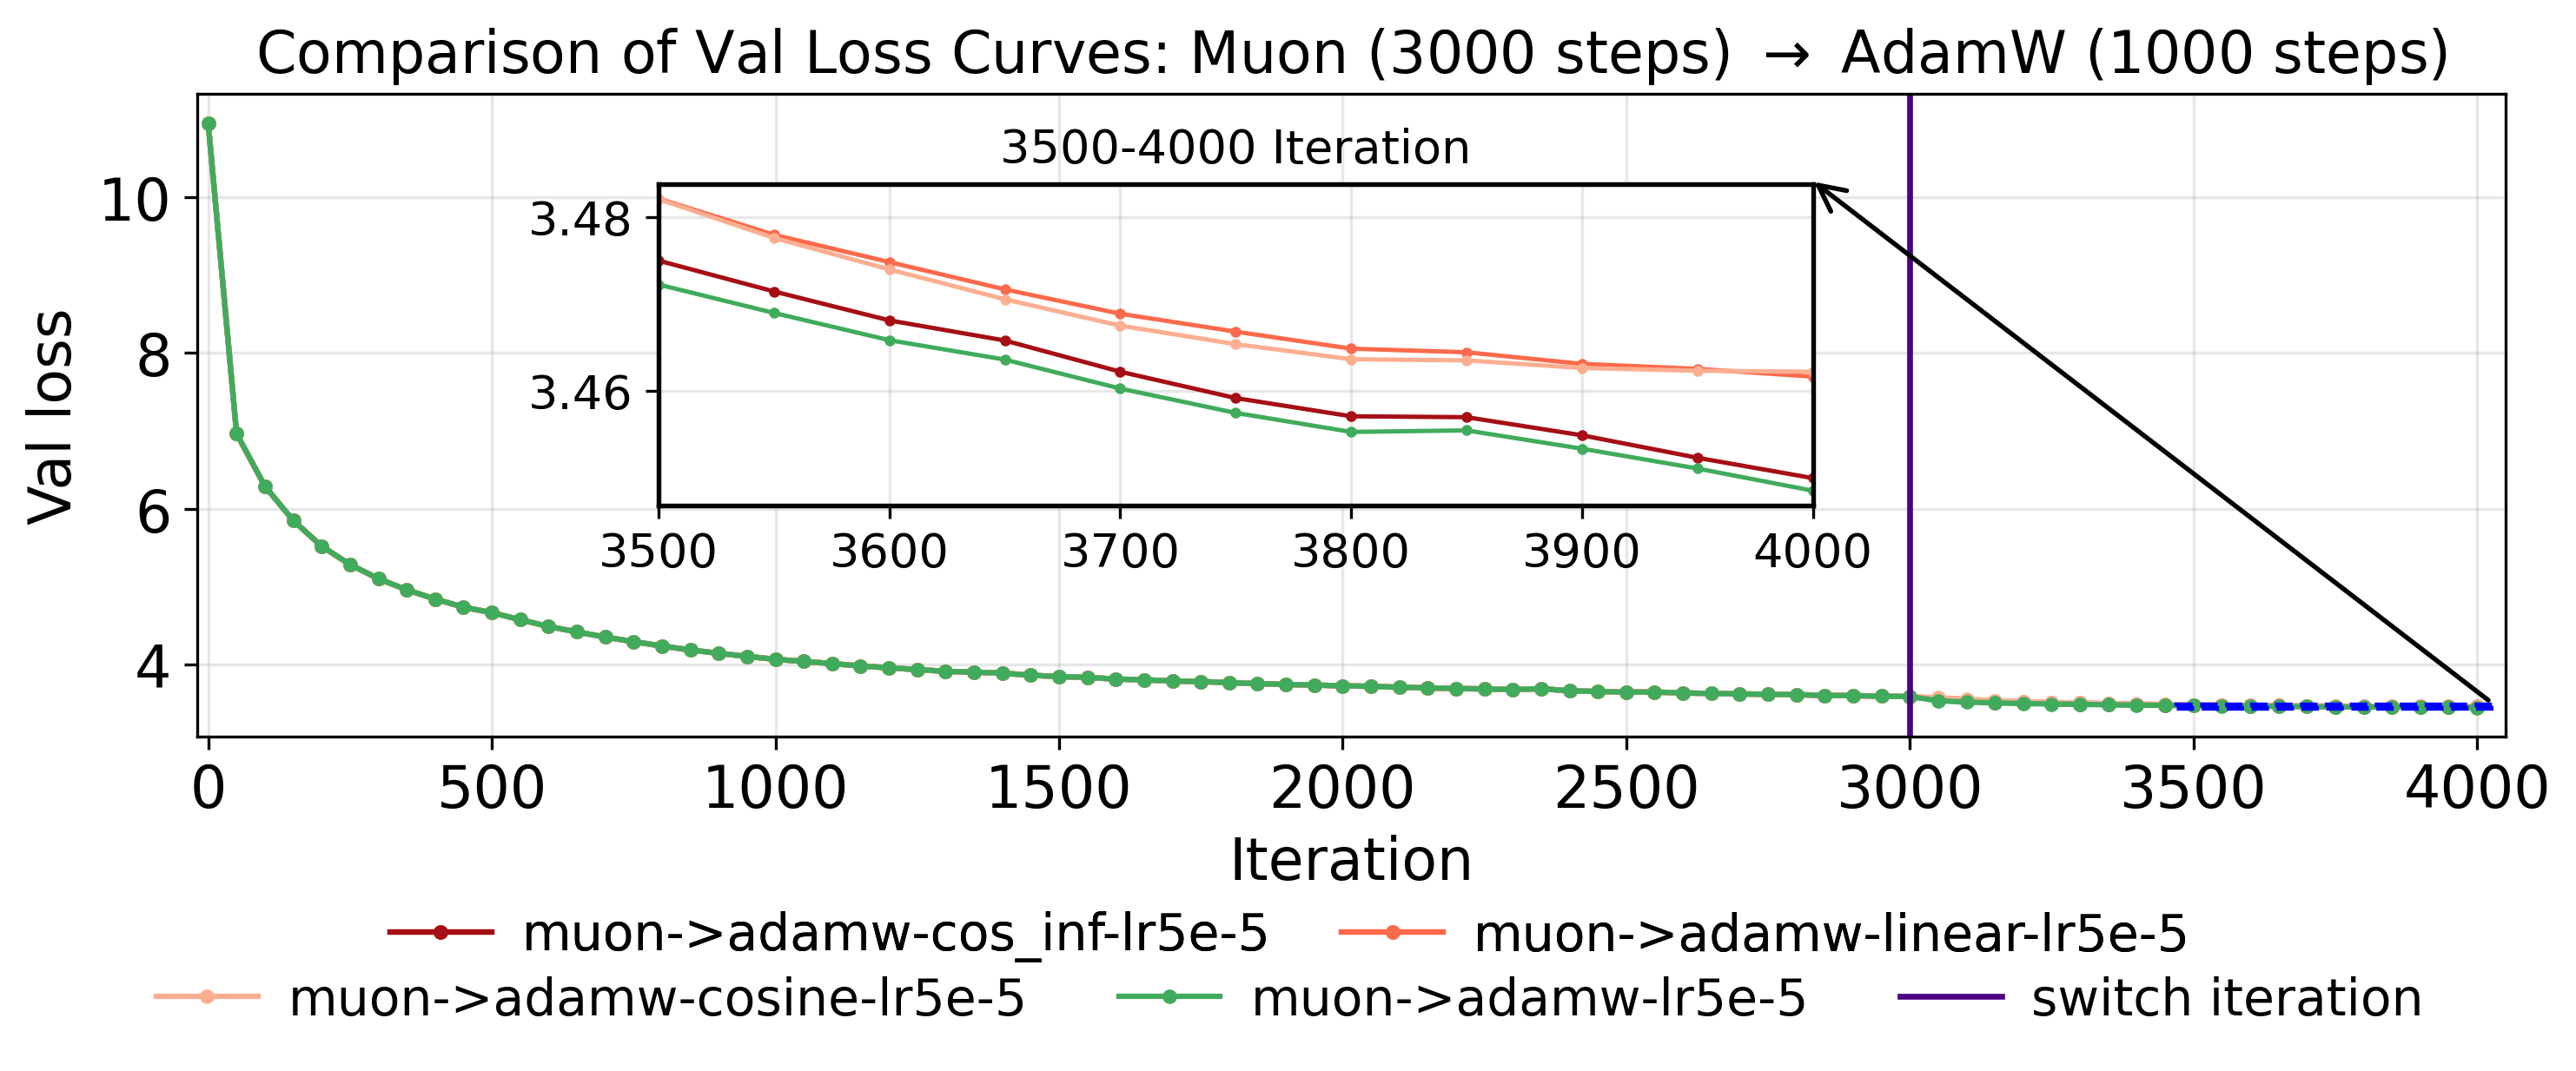

Saved figure to: llm_pretrain_lr_scheduler_muon3000adamw1000_val.pdf


In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr5e-5", "muon->adamw-linear-lr5e-5", "muon->adamw-cosine-lr5e-5", "muon->adamw-lr5e-5"]:
    x, y = get_hybrid_curve(df, x_col, "muon3000", col_map_val[name], switch_iter, "val", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Val Loss Curves: Muon (3000 steps) $\to$ AdamW (1000 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Val loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.20, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr5e-5", "muon->adamw-linear-lr5e-5", "muon->adamw-cosine-lr5e-5", "muon->adamw-lr5e-5"]:
    x, y = get_hybrid_curve(df, x_col, "muon3000", col_map_val[name], switch_iter, "val", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon3000", col_map_val["muon->adamw-cos_inf-lr5e-5"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon3000", col_map_val["muon->adamw-linear-lr5e-5"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon3000", col_map_val["muon->adamw-cosine-lr5e-5"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon3000", col_map_val["muon->adamw-lr5e-5"], switch_iter, "val", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(0.996, 1.02),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr5e-5", "muon->adamw-linear-lr5e-5"]
row2 = ["muon->adamw-cosine-lr5e-5", "muon->adamw-lr5e-5", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon3000adamw1000_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon3000adamw1000_val.pdf")
plt.close()

### Experiment5 result of train loss curves: Muon (3750 steps) $\to$ AdamW (250 steps)

In [24]:
csv_path = "llm_pretrain_lr_scheduler/3750muon+250adamw-train.csv"
df = pd.read_csv(csv_path)
#print(df.columns)  # different from the former two cases
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon3750_series = df[[x_col, col_map_train["muon3750"]]].dropna()
if muon3750_series.empty:
    raise ValueError("Column 'muon3750 - train/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon3750_series[x_col].max())

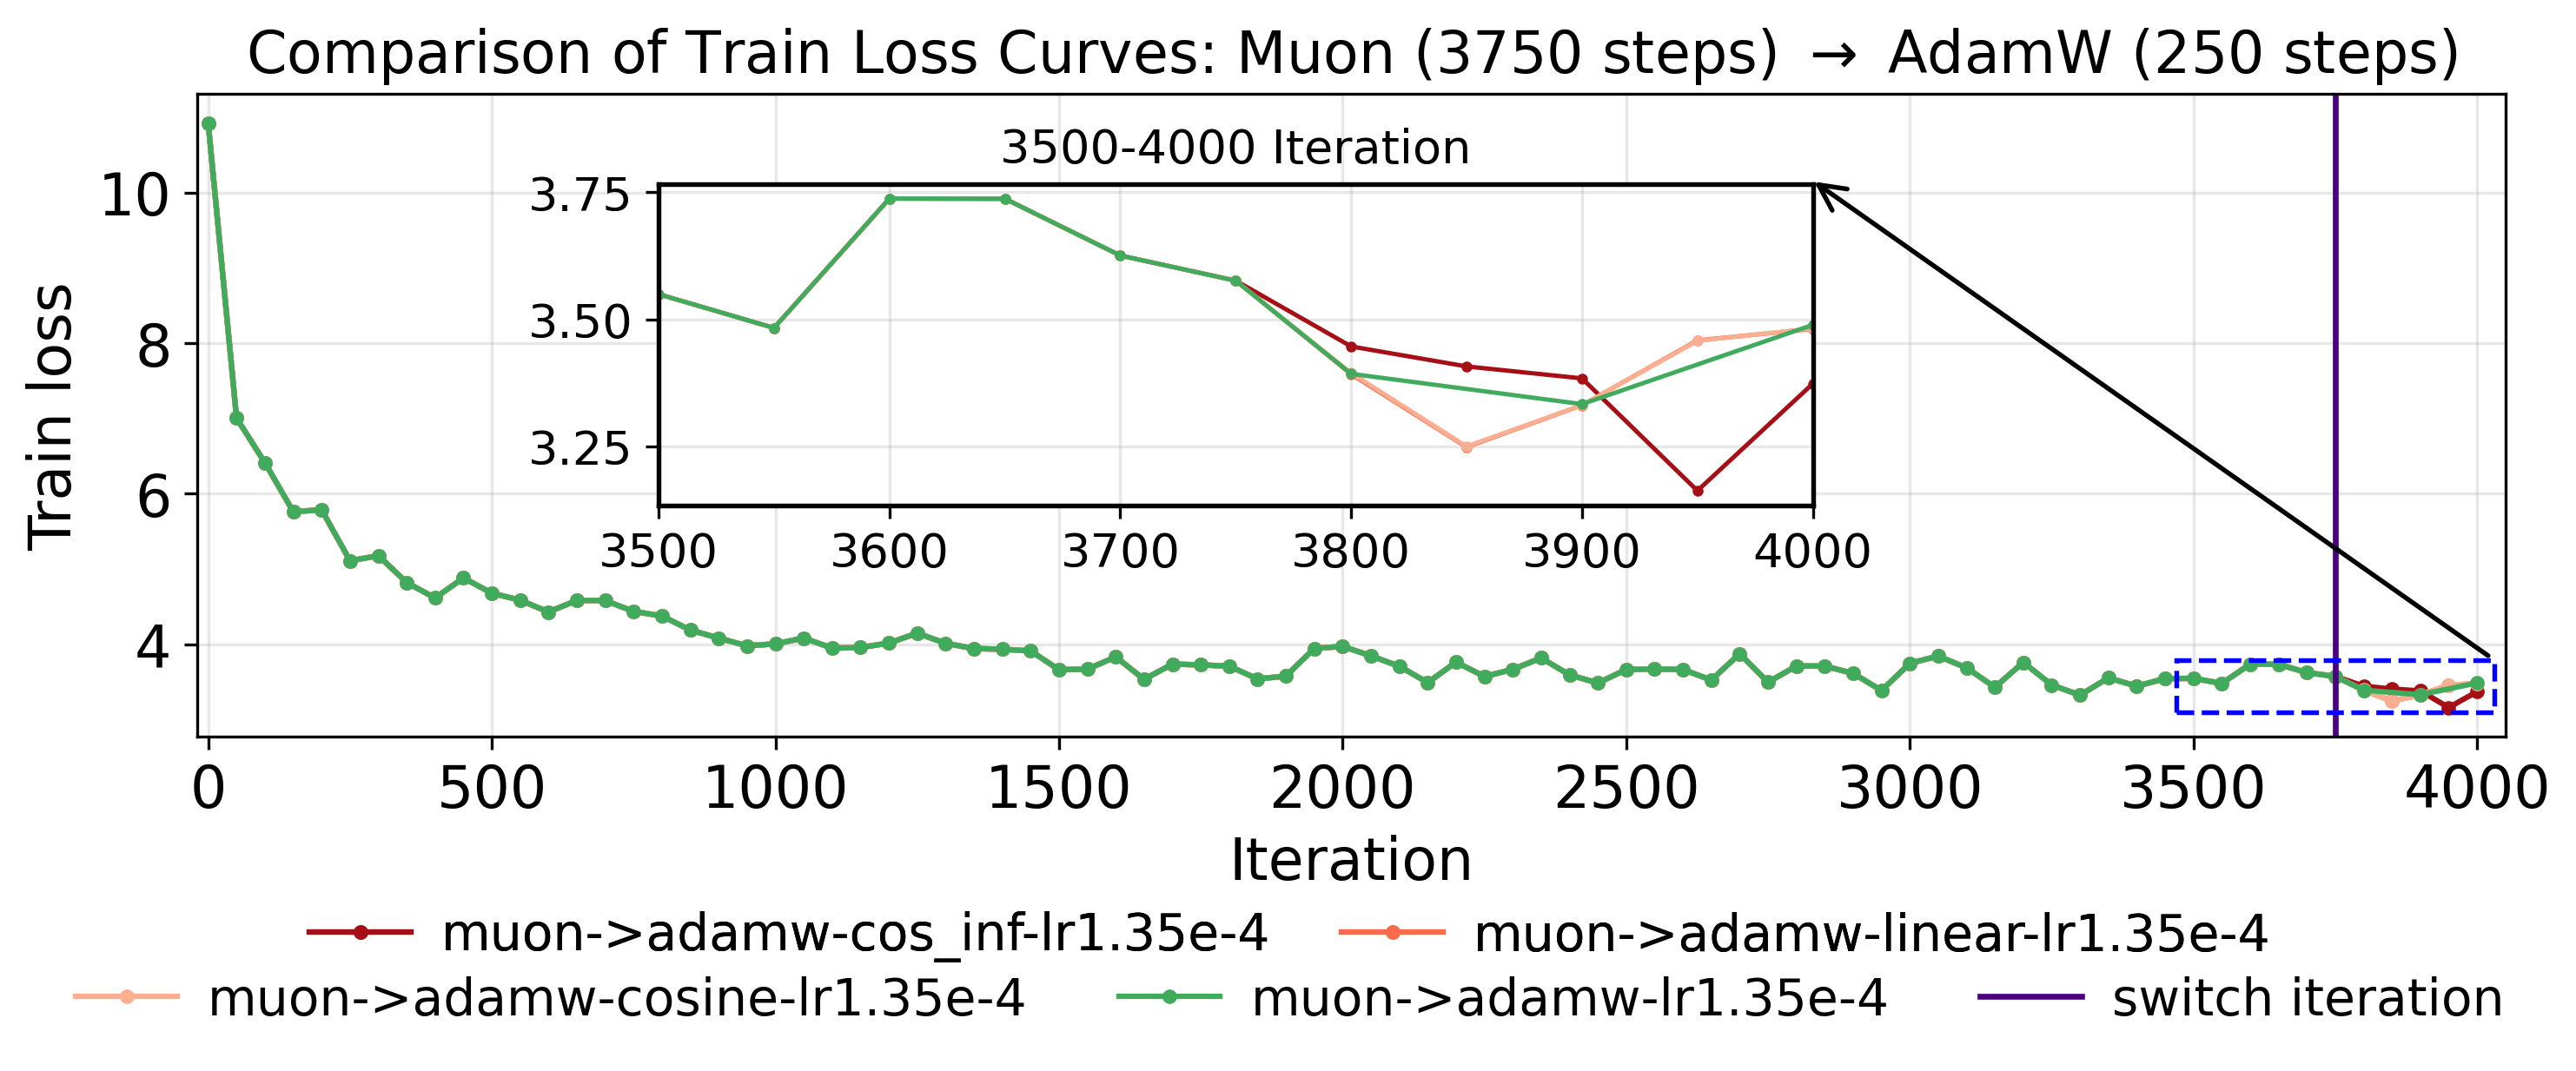

Saved figure to: llm_pretrain_lr_scheduler_muon3750adamw250_train.pdf


In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr1.35e-4", "muon->adamw-linear-lr1.35e-4", "muon->adamw-cosine-lr1.35e-4", "muon->adamw-lr1.35e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon3750", col_map_train[name], switch_iter, "train", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Train Loss Curves: Muon (3750 steps) $\to$ AdamW (250 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Train loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.20, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr1.35e-4", "muon->adamw-linear-lr1.35e-4", "muon->adamw-cosine-lr1.35e-4", "muon->adamw-lr1.35e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon3750", col_map_train[name], switch_iter, "train", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon3750", col_map_train["muon->adamw-cos_inf-lr1.35e-4"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon3750", col_map_train["muon->adamw-linear-lr1.35e-4"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon3750", col_map_train["muon->adamw-cosine-lr1.35e-4"], switch_iter, "train", keep="post"),
    get_hybrid_curve(df, x_col, "muon3750", col_map_train["muon->adamw-lr1.35e-4"], switch_iter, "train", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(0.996, 1.02),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr1.35e-4", "muon->adamw-linear-lr1.35e-4"]
row2 = ["muon->adamw-cosine-lr1.35e-4", "muon->adamw-lr1.35e-4", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon3750adamw250_train.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon3750adamw250_train.pdf")
plt.close()

### Experiment5 result of val loss curves: Muon (3750 steps) $\to$ AdamW (250 steps)

In [26]:
csv_path = "llm_pretrain_lr_scheduler/3750muon+250adamw-val.csv"
df = pd.read_csv(csv_path)
#print(df.columns)  # different from the former two cases
x_col = "iter"
df[x_col] = pd.to_numeric(df[x_col], errors="coerce")
muon3750_series = df[[x_col, col_map_val["muon3750"]]].dropna()
if muon3750_series.empty:
    raise ValueError("Column 'muon3750 - val/loss' has no data; cannot determine switch iteration.")
switch_iter = int(muon3750_series[x_col].max())

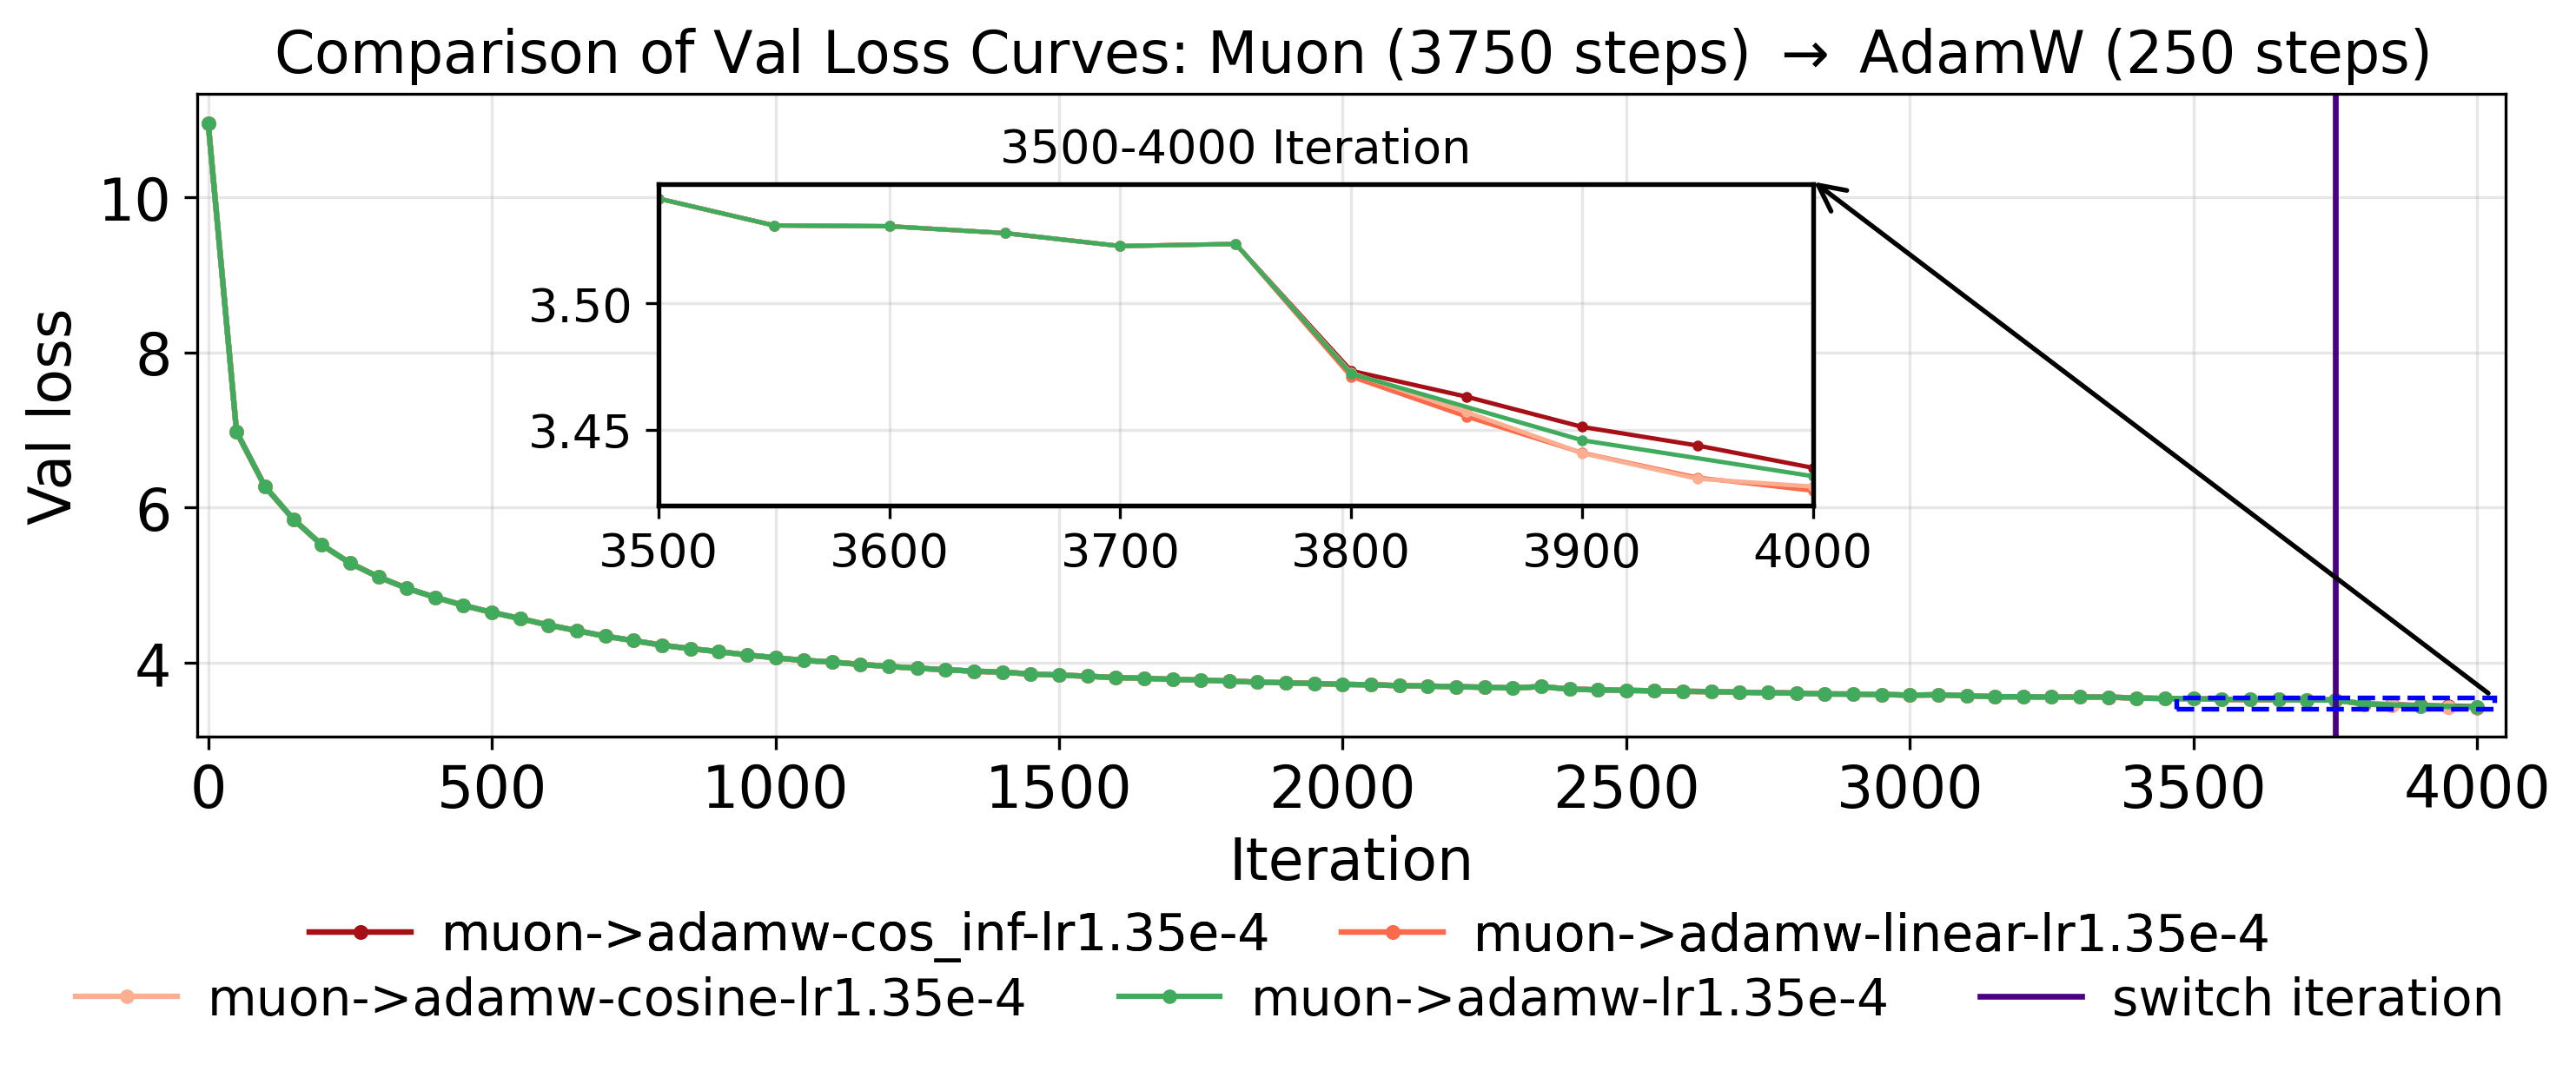

Saved figure to: llm_pretrain_lr_scheduler_muon3750adamw250_val.pdf


In [27]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["muon->adamw-cos_inf-lr1.35e-4", "muon->adamw-linear-lr1.35e-4", "muon->adamw-cosine-lr1.35e-4", "muon->adamw-lr1.35e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon3750", col_map_val[name], switch_iter, "val", keep="post")
    ax.plot(x, y, marker="o", markersize=3, linewidth=1.5, label=name, color=colors[name])
ax.axvline(switch_iter, color=switch_color, linewidth=1.6, linestyle="-", label="switch iteration")
ax.set_title(rf"Comparison of Val Loss Curves: Muon (3750 steps) $\to$ AdamW (250 steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16)
ax.set_ylabel("Val loss", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
max_iter = int(df[x_col].max())
ax.set_xlim(-20.0, float(max_iter)+50.0)
zoom_x0 = max_iter - 500
zoom_x1 = max_iter
axins = ax.inset_axes([0.20, 0.36, 0.50, 0.50])
for name in ["muon->adamw-cos_inf-lr1.35e-4", "muon->adamw-linear-lr1.35e-4", "muon->adamw-cosine-lr1.35e-4", "muon->adamw-lr1.35e-4"]:
    x, y = get_hybrid_curve(df, x_col, "muon3750", col_map_val[name], switch_iter, "val", keep="post")
    plot_on(axins, name, x, y, zoom_x0, zoom_x1)
axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0, zoom_x1)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)
all_inset_vals = []
for x, y in [
    get_hybrid_curve(df, x_col, "muon3750", col_map_val["muon->adamw-cos_inf-lr1.35e-4"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon3750", col_map_val["muon->adamw-linear-lr1.35e-4"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon3750", col_map_val["muon->adamw-cosine-lr1.35e-4"], switch_iter, "val", keep="post"),
    get_hybrid_curve(df, x_col, "muon3750", col_map_val["muon->adamw-lr1.35e-4"], switch_iter, "val", keep="post"),
]:
    m = (x >= zoom_x0) & (x <= zoom_x1)
    all_inset_vals.append(y[m])
vals = np.concatenate([v for v in all_inset_vals if v.size > 0])
vals = vals[np.isfinite(vals)]
y_min, y_max = vals.min(), vals.max()
margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
zoom_y0, zoom_y1 = y_min - margin, y_max + margin
rect_x0, rect_x1 = zoom_x0 - 30, zoom_x1 + 30
rect_y0, rect_y1 = zoom_y0 - 0.25 * margin, zoom_y1 + 0.25 * margin
rect = Rectangle((rect_x0, rect_y0), rect_x1 - rect_x0, rect_y1 - rect_y0, 
                 fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1, rect_y1),         # start point in main axes data coords
    coordsA=ax.transData,
    xyB=(0.996, 1.02),               # end point in inset axes (axes fraction coords)
    coordsB=axins.transAxes, axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black", shrinkA=2, shrinkB=2, clip_on=False,)
fig.add_artist(arrow)
fig.tight_layout()
fig.subplots_adjust(bottom=0.28)
handles, labels = ax.get_legend_handles_labels()
hmap = dict(zip(labels, handles))
row1 = ["muon->adamw-cos_inf-lr1.35e-4", "muon->adamw-linear-lr1.35e-4"]
row2 = ["muon->adamw-cosine-lr1.35e-4", "muon->adamw-lr1.35e-4", "switch iteration"]
leg1 = fig.legend([hmap[l] for l in row1], row1, loc="lower center", ncol=len(row1), frameon=False,
                  fontsize=14, bbox_to_anchor=(0.5, 0.02), columnspacing=1.4, handletextpad=0.6,)
fig.add_artist(leg1)  # IMPORTANT: keep the first legend when adding the second one
fig.legend([hmap[l] for l in row2], row2, loc="lower center", ncol=len(row2), frameon=False,
           fontsize=14, bbox_to_anchor=(0.5, -0.04), columnspacing=1.8, handletextpad=0.6,)
plt.show()
fig.savefig("llm_pretrain_lr_scheduler_muon3750adamw250_val.pdf", dpi=300, format="pdf", bbox_inches="tight")
print(f"Saved figure to: llm_pretrain_lr_scheduler_muon3750adamw250_val.pdf")
plt.close()

### 15k Muon vs. Muon→AdamW validation-loss curves

This section uses the full Muon run as the shared pre-switch trajectory, then joins each AdamW continuation at its recorded switch iteration. The CSV contains switches at 10k, 11k, 12k, 13k, and 14k; all runs end at 15k. The switch point keeps the AdamW value if both phases contain that iteration.

In [29]:
# Run from the directory containing this notebook and muon+adamw15kVAL.csv.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

csv_path_15k = "llm_pretrain_lr_scheduler/muon+adamw15kVAL.csv"
df_15k = pd.read_csv(csv_path_15k)
x_col_15k = "iter"
baseline_col_15k = "MA2_muon15k - val/loss"
df_15k[x_col_15k] = pd.to_numeric(df_15k[x_col_15k], errors="coerce")
df_15k = df_15k.dropna(subset=[x_col_15k]).sort_values(x_col_15k)

total_steps_15k = int(df_15k[x_col_15k].max())
if total_steps_15k != 15000:
    raise ValueError(f"Expected a 15,000-step run, found max iteration {total_steps_15k}.")

curve_specs_15k = [
    {
        "label": "Muon→AdamW (10k switch)",
        "column": "MA2_muon10k+adamw - val/loss",
        "switch_iter": 10000,
        "color": "#006d2c",
    },
    {
        "label": "Muon→AdamW (11k switch)",
        "column": "MA2_muon11k+adamw - val/loss",
        "switch_iter": 11000,
        "color": "#1f77b4",
    },
    {
        "label": "Muon→AdamW (12k switch)",
        "column": "MA2_muon12k+adamw - val/loss",
        "switch_iter": 12000,
        "color": "#ff7f0e",
    },
    {
        "label": "Muon→AdamW (13k switch)",
        "column": "MA2_muon13k+adamw - val/loss",
        "switch_iter": 13000,
        "color": "#9467bd",
    },
    {
        "label": "Muon→AdamW (14k switch)",
        "column": "MA2_muon14k+adamw - val/loss",
        "switch_iter": 14000,
        "color": "#17becf",
    },
]
baseline_label_15k = "Muon baseline (15k)"
baseline_color_15k = colors["muon"] if "colors" in globals() else "#ff244f"

required_cols_15k = [baseline_col_15k] + [spec["column"] for spec in curve_specs_15k]
missing_cols_15k = [column for column in required_cols_15k if column not in df_15k.columns]
if missing_cols_15k:
    raise KeyError(f"Missing required validation-loss columns: {missing_cols_15k}")

def get_curve_15k(column):
    data = df_15k[[x_col_15k, column]].copy()
    data[column] = pd.to_numeric(data[column], errors="coerce")
    data = data.dropna().sort_values(x_col_15k)
    return data[x_col_15k].to_numpy(), data[column].to_numpy()

def get_hybrid_curve_15k(adamw_col, switch_iter):
    # Reuse the full Muon trajectory before the switch, then the recorded AdamW continuation.
    pre = df_15k[[x_col_15k, baseline_col_15k]].copy()
    pre[baseline_col_15k] = pd.to_numeric(pre[baseline_col_15k], errors="coerce")
    pre = pre.dropna()
    pre = pre[pre[x_col_15k] <= switch_iter]
    pre = pre.rename(columns={baseline_col_15k: "loss"})

    post = df_15k[[x_col_15k, adamw_col]].copy()
    post[adamw_col] = pd.to_numeric(post[adamw_col], errors="coerce")
    post = post.dropna()
    post = post[post[x_col_15k] >= switch_iter]
    post = post.rename(columns={adamw_col: "loss"})

    # Stable sorting plus keep="last" selects the AdamW value at a duplicated switch point.
    combo = pd.concat([pre, post], ignore_index=True)
    combo = combo.sort_values(x_col_15k, kind="stable")
    combo = combo.drop_duplicates(subset=[x_col_15k], keep="last")
    return combo[x_col_15k].to_numpy(), combo["loss"].to_numpy()

muon_x_15k, muon_y_15k = get_curve_15k(baseline_col_15k)
if muon_x_15k.size == 0 or muon_x_15k[0] != 0 or muon_x_15k[-1] != total_steps_15k:
    raise ValueError("The full Muon baseline must cover iterations 0 through 15,000.")

for spec in curve_specs_15k:
    branch_x, branch_y = get_curve_15k(spec["column"])
    if branch_x.size == 0:
        raise ValueError(f"No validation-loss data found in {spec['column']!r}.")
    actual_switch = int(branch_x[0])
    if actual_switch != spec["switch_iter"]:
        raise ValueError(
            f"{spec['column']!r} starts at {actual_switch}, "
            f"but the configured switch is {spec['switch_iter']}."
        )
    if branch_x[-1] != total_steps_15k:
        raise ValueError(f"{spec['column']!r} does not reach iteration {total_steps_15k}.")
    spec["x"], spec["y"] = get_hybrid_curve_15k(spec["column"], actual_switch)

print(f"Loaded baseline and {len(curve_specs_15k)} Muon→AdamW branches through iteration {total_steps_15k}.")

Loaded baseline and 5 Muon→AdamW branches through iteration 15000.


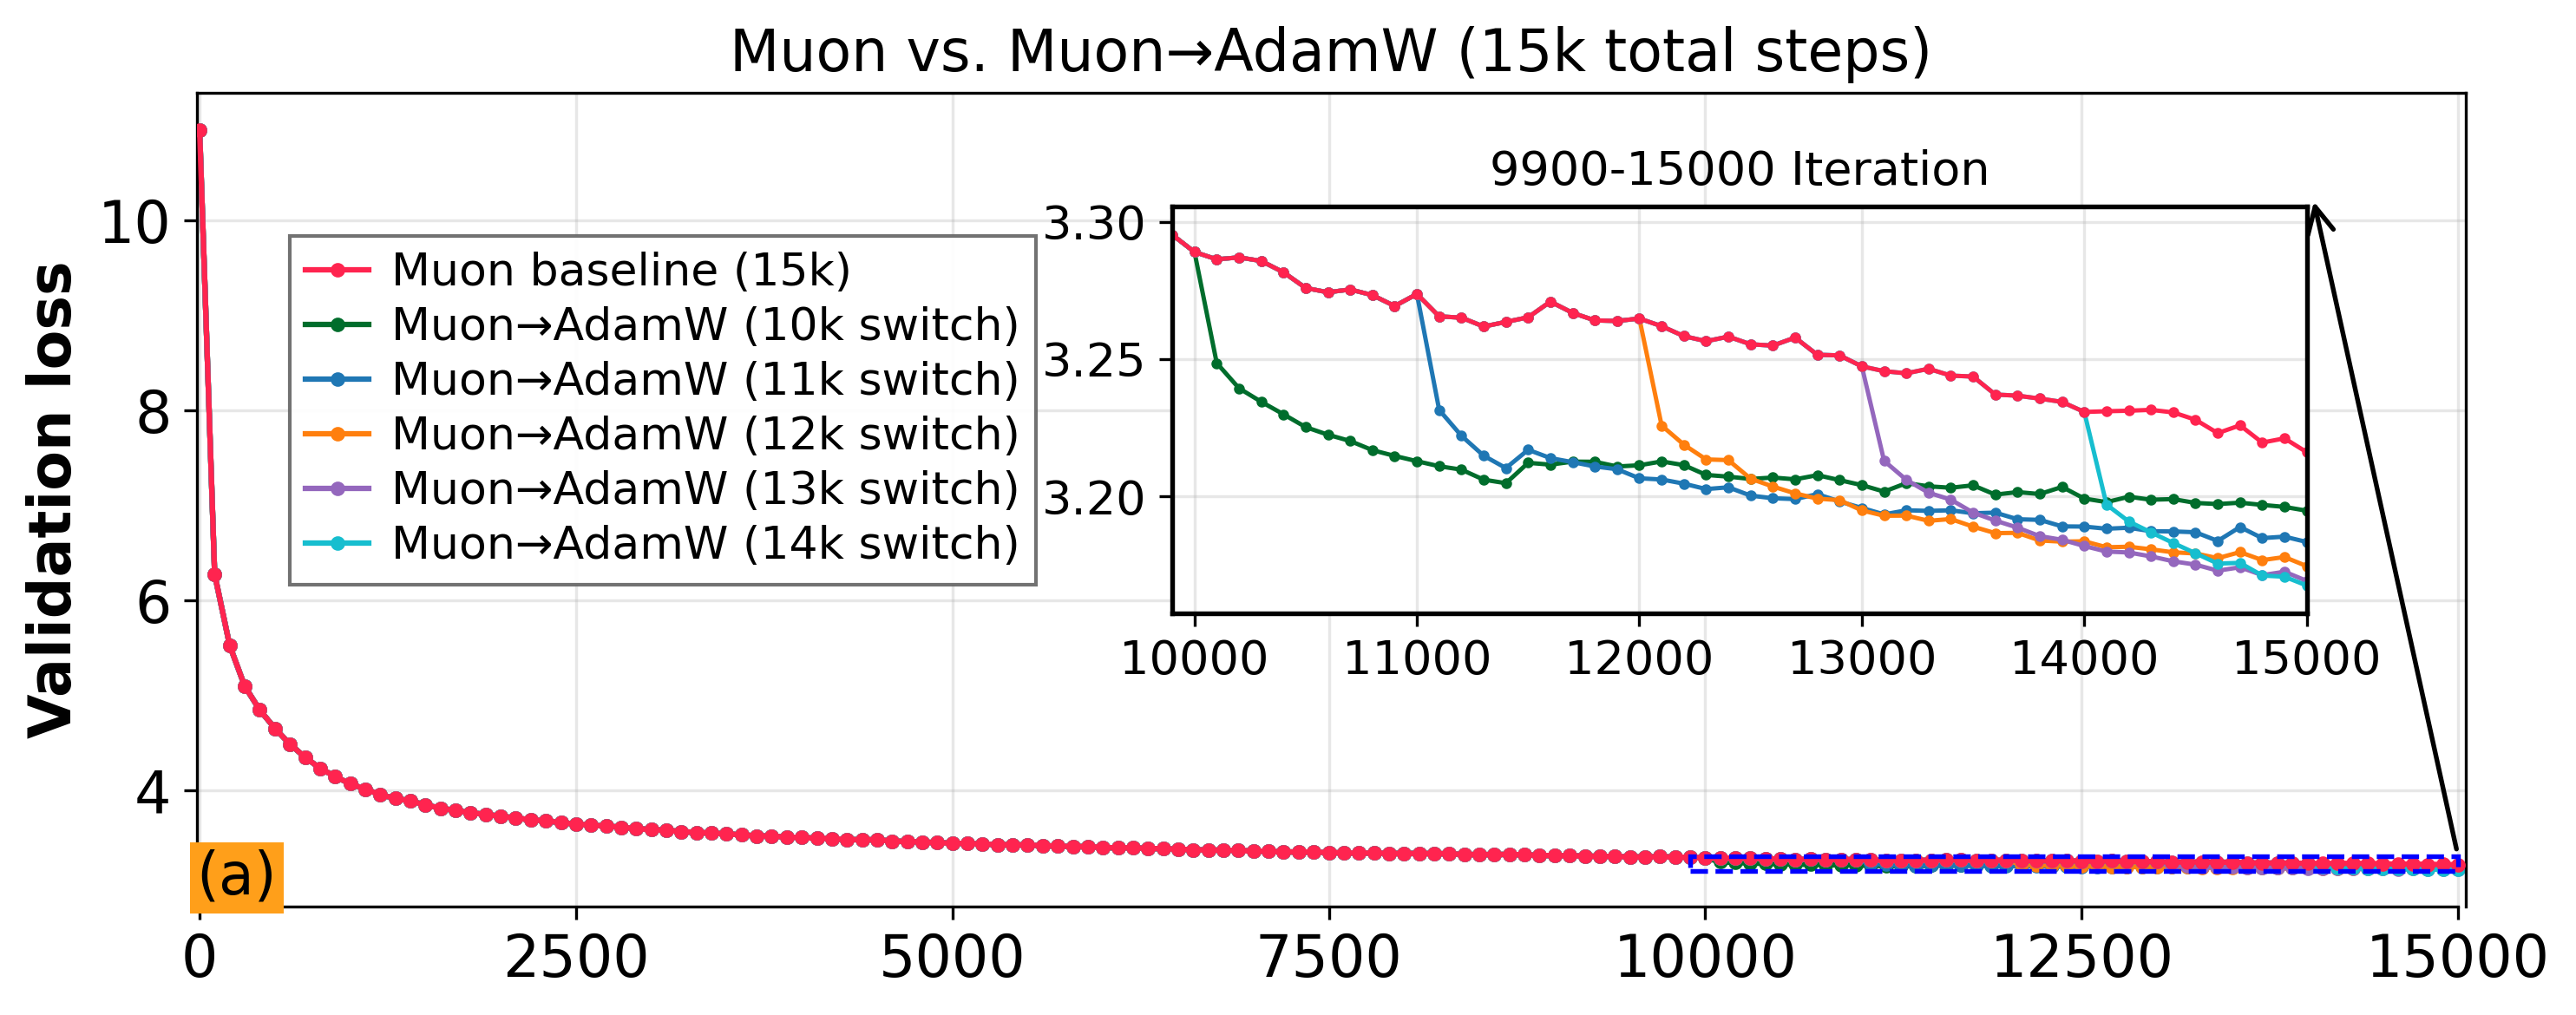

Saved vector PDF to: muon_adamw_15k_val_loss.pdf


In [43]:
fig, ax = plt.subplots(figsize=(10, 4))

# Draw the five stitched hybrid curves first; draw the Muon baseline last so its shared
# pre-switch trajectory remains visible.
for spec in curve_specs_15k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=2,
    )
ax.plot(
    muon_x_15k, muon_y_15k,
    marker="o", markersize=3, linewidth=1.5,
    label=baseline_label_15k, color=baseline_color_15k, zorder=4,
)

ax.set_title("Muon vs. Muon→AdamW (15k total steps)", fontsize=16)
ax.set_xlabel("")
ax.set_ylabel("Validation loss", fontsize=16, fontweight="bold")
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
ax.text(
    0.0, 0.0, "(a)", transform=ax.transAxes,
    ha="left", va="bottom", fontsize=16, color="black",
    bbox={"facecolor": "#ff9f1a", "edgecolor": "none", "pad": 2.0},
)

max_iter_15k = int(df_15k[x_col_15k].max())
ax.set_xlim(-20.0, float(max_iter_15k) + 50.0)
ax.spines["bottom"].set_bounds(0, max_iter_15k)
# Match the 20k plot's 2,500-iteration tick spacing and show the 15k endpoint.
ax.set_xticks(np.arange(0, max_iter_15k + 1, 2500))
ax.set_yticks([4, 6, 8, 10])
zoom_x0_15k = max_iter_15k - 5100
zoom_x1_15k = max_iter_15k
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])

for spec in curve_specs_15k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_15k) & (x <= zoom_x1_15k)
    axins.plot(
        x[in_zoom], y[in_zoom],
        marker="o", markersize=2, linewidth=1.2, color=spec["color"],
    )
muon_in_zoom = (muon_x_15k >= zoom_x0_15k) & (muon_x_15k <= zoom_x1_15k)
axins.plot(
    muon_x_15k[muon_in_zoom], muon_y_15k[muon_in_zoom],
    marker="o", markersize=2, linewidth=1.2, color=baseline_color_15k,
)
axins.set_title(f"{zoom_x0_15k}-{zoom_x1_15k} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0_15k, zoom_x1_15k)

all_zoom_values_15k = [muon_y_15k[muon_in_zoom]]
for spec in curve_specs_15k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_15k) & (x <= zoom_x1_15k)
    all_zoom_values_15k.append(y[in_zoom])
zoom_values_15k = np.concatenate([values for values in all_zoom_values_15k if values.size > 0])
zoom_values_15k = zoom_values_15k[np.isfinite(zoom_values_15k)]
y_min_15k, y_max_15k = zoom_values_15k.min(), zoom_values_15k.max()
y_margin_15k = (y_max_15k - y_min_15k) * 0.08 if y_max_15k > y_min_15k else 1e-6
zoom_y0_15k, zoom_y1_15k = y_min_15k - y_margin_15k, y_max_15k + y_margin_15k
axins.set_ylim(zoom_y0_15k, zoom_y1_15k)

for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

rect_x0_15k, rect_x1_15k = max(0, zoom_x0_15k), min(max_iter_15k, zoom_x1_15k)
rect_y0_15k = zoom_y0_15k - 0.25 * y_margin_15k
rect_y1_15k = zoom_y1_15k + 0.25 * y_margin_15k
rect = Rectangle(
    (rect_x0_15k, rect_y0_15k),
    rect_x1_15k - rect_x0_15k,
    rect_y1_15k - rect_y0_15k,
    fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20,
)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1_15k, rect_y1_15k),
    coordsA=ax.transData,
    xyB=(1.005, 1.03),
    coordsB=axins.transAxes,
    axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
)
fig.add_artist(arrow)

fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()
handle_map_15k = dict(zip(labels, handles))
legend_labels_15k = [
    baseline_label_15k,
    "Muon→AdamW (10k switch)",
    "Muon→AdamW (11k switch)",
    "Muon→AdamW (12k switch)",
    "Muon→AdamW (13k switch)",
    "Muon→AdamW (14k switch)",
]
# Place the 15k legend in the open area immediately left of its inset.
legend_15k = ax.legend(
    [handle_map_15k[label] for label in legend_labels_15k],
    legend_labels_15k,
    loc="center right", bbox_to_anchor=(0.38, 0.61),
    ncol=1, frameon=True, fancybox=False, framealpha=0.92,
    facecolor="white", edgecolor="0.4", fontsize=12.5,
    borderpad=0.35, labelspacing=0.25,
    handlelength=1.4, handletextpad=0.5,
)
legend_15k.set_zorder(30)
output_pdf_15k = "muon_adamw_15k_val_loss.pdf"
fig.savefig(output_pdf_15k, dpi=300, format="pdf", bbox_inches="tight")
plt.show()
print(f"Saved vector PDF to: {output_pdf_15k}")
plt.close()

### 20k Muon schedules vs. Muon→AdamW validation-loss curves

This section plots the constant, cos_inf, and linear Muon schedules together with the 16k, 18k, and 19k Muon→AdamW continuations. Hybrid curves use the constant-Muon 20k run as their shared pre-switch trajectory; at a duplicated switch iteration, the AdamW value is retained. The inset covers iterations 15,900–20,000. Colors for the Muon curves follow the mapping defined earlier in this notebook.

In [32]:
# Run from the directory containing this notebook and muon20k+adamwVAL.csv.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

csv_path_20k = "llm_pretrain_lr_scheduler/muon20k+adamwVAL.csv"
df_20k = pd.read_csv(csv_path_20k)
x_col_20k = "iter"
muon_baseline_col_20k = "2muon20k - val/loss"
df_20k[x_col_20k] = pd.to_numeric(df_20k[x_col_20k], errors="coerce")
df_20k = df_20k.dropna(subset=[x_col_20k]).sort_values(x_col_20k)

total_steps_20k = int(df_20k[x_col_20k].max())
if total_steps_20k != 20000:
    raise ValueError(f"Expected a 20,000-step run, found max iteration {total_steps_20k}.")

# Keep the notebook's original colors for the selected Muon curves.
muon_curve_specs_20k = [
    {
        "label": "Muon baseline (20k)",
        "column": "2muon20k - val/loss",
        "color": colors["muon"] if "colors" in globals() else "#ff244f",
    },
    {
        "label": "Muon-cos_inf (20k)",
        "column": "2muon20kcf - val/loss",
        "color": colors["muon-cos_inf"] if "colors" in globals() else "#a50f15",
    },
    {
        "label": "Muon-linear (20k)",
        "column": "2muon20klinear - val/loss",
        "color": colors["muon-linear"] if "colors" in globals() else "#fb6a4a",
    },
]

# Keep the original colors/order for the selected hybrid curves.
hybrid_curve_specs_20k = [
    {
        "label": "Muon→AdamW (16k switch)",
        "column": "2muon16000+adamw9e5cf - val/loss",
        "switch_iter": 16000,
        "color": "#1f77b4",
    },
    {
        "label": "Muon→AdamW (18k switch)",
        "column": "2muon18000+adamwcf - val/loss",
        "switch_iter": 18000,
        "color": "#9467bd",
    },
    {
        "label": "Muon→AdamW (19k switch)",
        "column": "2muon19000+adamw - val/loss",
        "switch_iter": 19000,
        "color": "#17becf",
    },
]

required_cols_20k = [spec["column"] for spec in muon_curve_specs_20k + hybrid_curve_specs_20k]
missing_cols_20k = [column for column in required_cols_20k if column not in df_20k.columns]
if missing_cols_20k:
    raise KeyError(f"Missing required validation-loss columns: {missing_cols_20k}")

def get_curve_20k(column):
    data = df_20k[[x_col_20k, column]].copy()
    data[column] = pd.to_numeric(data[column], errors="coerce")
    data = data.dropna().sort_values(x_col_20k)
    return data[x_col_20k].to_numpy(), data[column].to_numpy()

def get_hybrid_curve_20k(adamw_col, switch_iter):
    # The AdamW runs resume the constant-Muon trajectory at their respective checkpoints.
    pre = df_20k[[x_col_20k, muon_baseline_col_20k]].copy()
    pre[muon_baseline_col_20k] = pd.to_numeric(pre[muon_baseline_col_20k], errors="coerce")
    pre = pre.dropna()
    pre = pre[pre[x_col_20k] <= switch_iter]
    pre = pre.rename(columns={muon_baseline_col_20k: "loss"})

    post = df_20k[[x_col_20k, adamw_col]].copy()
    post[adamw_col] = pd.to_numeric(post[adamw_col], errors="coerce")
    post = post.dropna()
    post = post[post[x_col_20k] >= switch_iter]
    post = post.rename(columns={adamw_col: "loss"})

    # Stable sorting plus keep="last" retains the AdamW value at a duplicated switch point.
    combo = pd.concat([pre, post], ignore_index=True)
    combo = combo.sort_values(x_col_20k, kind="stable")
    combo = combo.drop_duplicates(subset=[x_col_20k], keep="last")
    return combo[x_col_20k].to_numpy(), combo["loss"].to_numpy()

for spec in muon_curve_specs_20k:
    x, y = get_curve_20k(spec["column"])
    if x.size == 0 or x[0] != 0 or x[-1] != total_steps_20k:
        raise ValueError(f"{spec['column']!r} must cover iterations 0 through {total_steps_20k}.")
    spec["x"], spec["y"] = x, y

for spec in hybrid_curve_specs_20k:
    branch_x, _ = get_curve_20k(spec["column"])
    if branch_x.size == 0:
        raise ValueError(f"No validation-loss data found in {spec['column']!r}.")
    actual_switch = int(branch_x[0])
    if actual_switch != spec["switch_iter"]:
        raise ValueError(
            f"{spec['column']!r} starts at {actual_switch}, "
            f"but the configured switch is {spec['switch_iter']}."
        )
    if branch_x[-1] != total_steps_20k:
        raise ValueError(f"{spec['column']!r} does not reach iteration {total_steps_20k}.")
    spec["x"], spec["y"] = get_hybrid_curve_20k(spec["column"], actual_switch)

print(
    f"Loaded {len(muon_curve_specs_20k)} Muon schedules and "
    f"{len(hybrid_curve_specs_20k)} Muon→AdamW branches through iteration {total_steps_20k}."
)

Loaded 3 Muon schedules and 3 Muon→AdamW branches through iteration 20000.


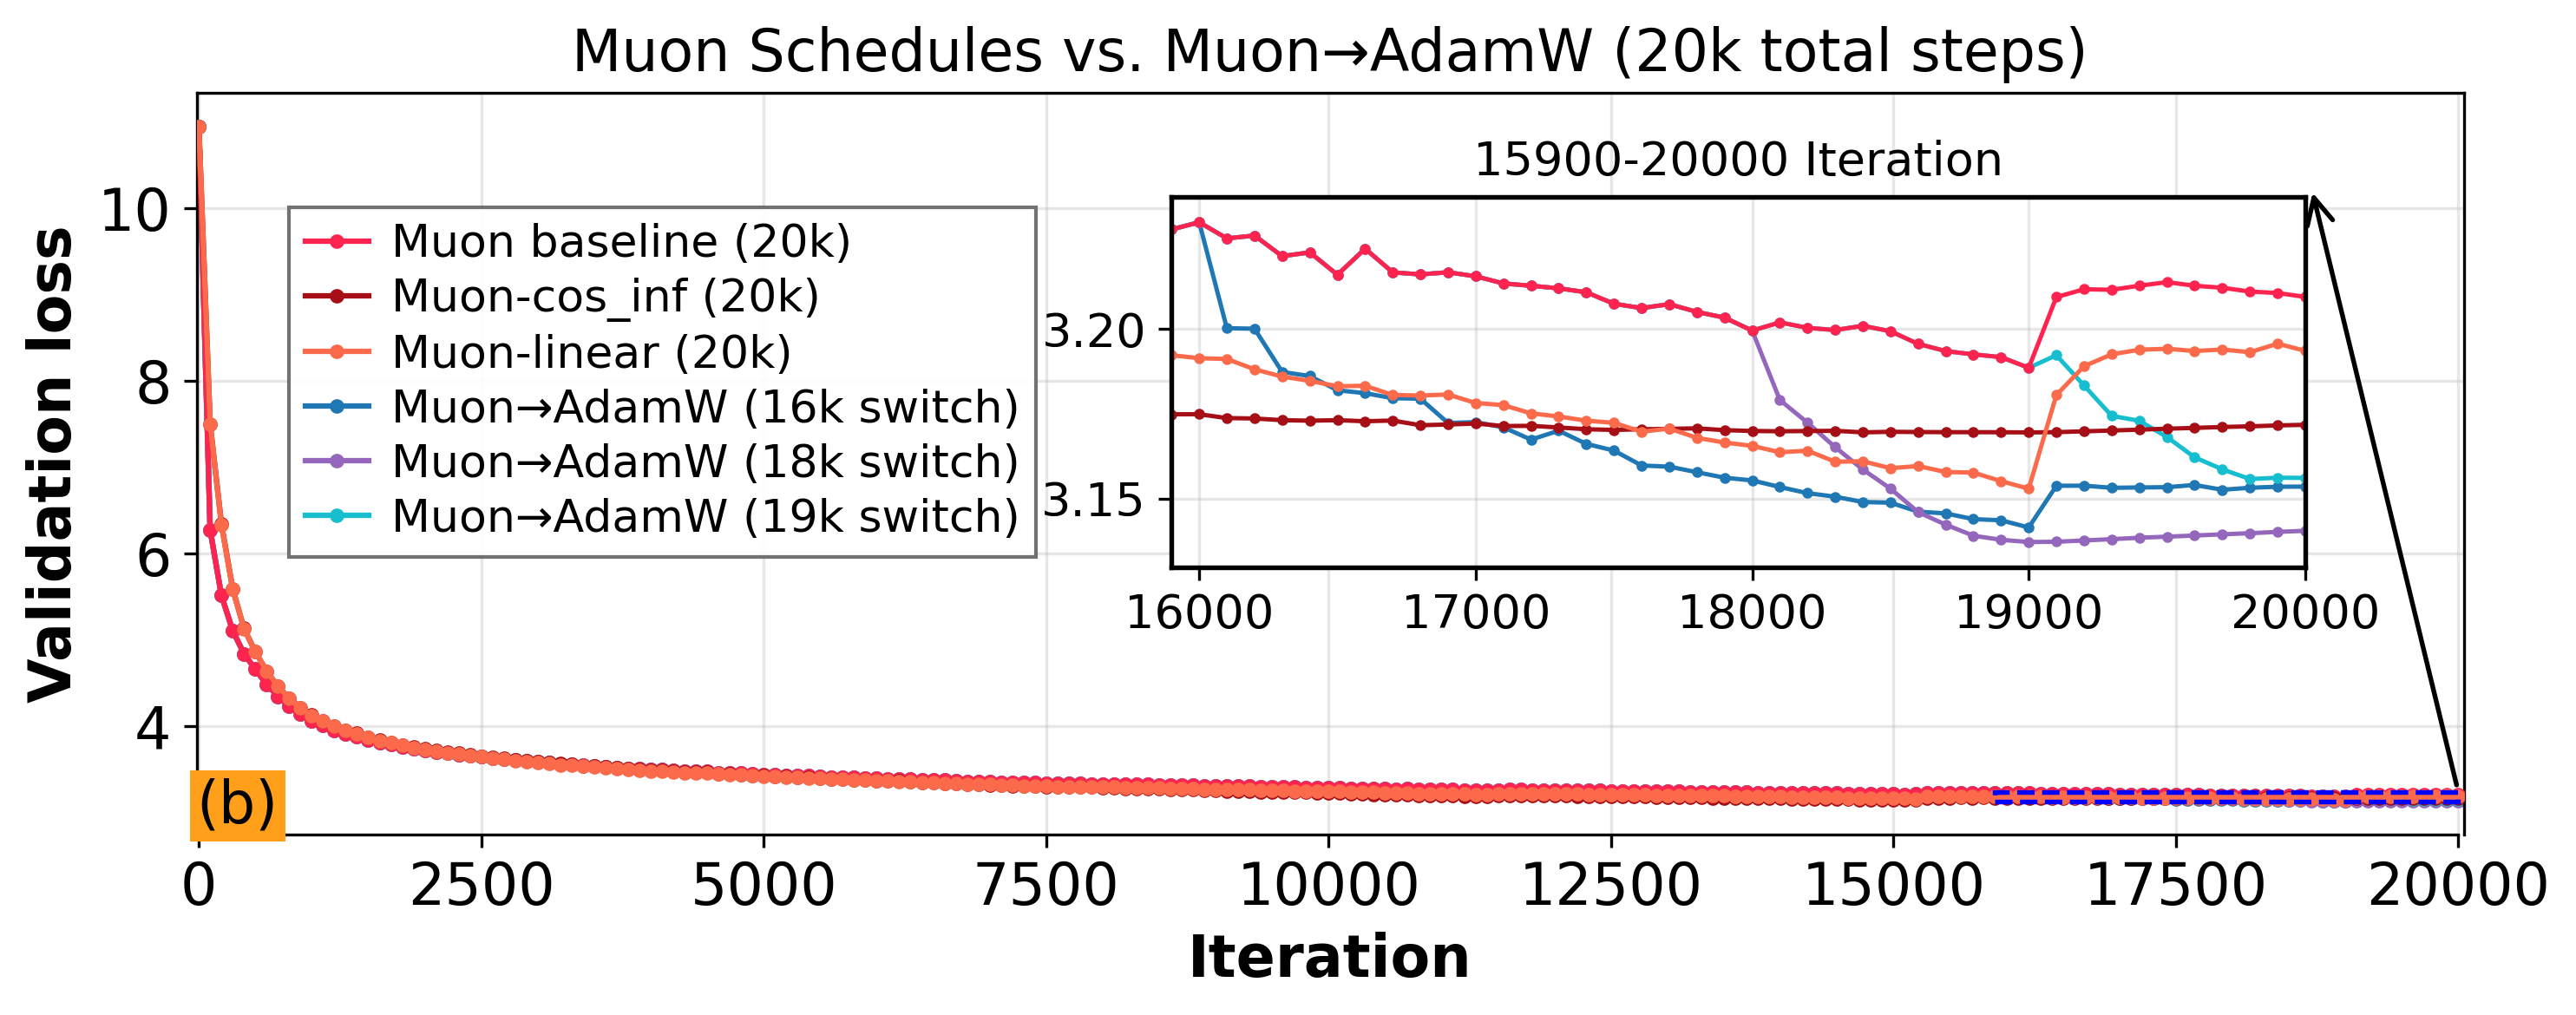

Saved vector PDF to: muon_adamw_20k_val_loss_selected.pdf


In [33]:
fig, ax = plt.subplots(figsize=(10, 4))

# Plot hybrids first and Muon-only runs after them, so the reference trajectories
# and their matching colors remain clear where curves overlap.
for spec in hybrid_curve_specs_20k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=2,
    )
for spec in muon_curve_specs_20k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=3,
    )

ax.set_title("Muon Schedules vs. Muon→AdamW (20k total steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16, fontweight="bold")
ax.set_ylabel("Validation loss", fontsize=16, fontweight="bold")
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
ax.text(
    0.0, 0.0, "(b)", transform=ax.transAxes,
    ha="left", va="bottom", fontsize=16, color="black",
    bbox={"facecolor": "#ff9f1a", "edgecolor": "none", "pad": 2.0},
)

max_iter_20k = int(df_20k[x_col_20k].max())
ax.set_xlim(-20.0, float(max_iter_20k) + 50.0)
ax.spines["bottom"].set_bounds(0, max_iter_20k)
ax.set_yticks([4, 6, 8, 10])
zoom_x0_20k = 15900
zoom_x1_20k = max_iter_20k
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])

for spec in hybrid_curve_specs_20k + muon_curve_specs_20k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_20k) & (x <= zoom_x1_20k)
    axins.plot(
        x[in_zoom], y[in_zoom],
        marker="o", markersize=2, linewidth=1.2, color=spec["color"],
    )
axins.set_title(f"{zoom_x0_20k}-{zoom_x1_20k} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0_20k, zoom_x1_20k)

all_zoom_values_20k = []
for spec in hybrid_curve_specs_20k + muon_curve_specs_20k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_20k) & (x <= zoom_x1_20k)
    all_zoom_values_20k.append(y[in_zoom])
zoom_values_20k = np.concatenate([values for values in all_zoom_values_20k if values.size > 0])
zoom_values_20k = zoom_values_20k[np.isfinite(zoom_values_20k)]
y_min_20k, y_max_20k = zoom_values_20k.min(), zoom_values_20k.max()
y_margin_20k = (y_max_20k - y_min_20k) * 0.08 if y_max_20k > y_min_20k else 1e-6
zoom_y0_20k, zoom_y1_20k = y_min_20k - y_margin_20k, y_max_20k + y_margin_20k
axins.set_ylim(zoom_y0_20k, zoom_y1_20k)

for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

rect_x0_20k, rect_x1_20k = max(0, zoom_x0_20k), min(max_iter_20k, zoom_x1_20k)
rect_y0_20k = zoom_y0_20k - 0.25 * y_margin_20k
rect_y1_20k = zoom_y1_20k + 0.25 * y_margin_20k
rect = Rectangle(
    (rect_x0_20k, rect_y0_20k),
    rect_x1_20k - rect_x0_20k,
    rect_y1_20k - rect_y0_20k,
    fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20,
)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1_20k, rect_y1_20k),
    coordsA=ax.transData,
    xyB=(1.005, 1.03),
    coordsB=axins.transAxes,
    axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
)
fig.add_artist(arrow)

fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()
handle_map_20k = dict(zip(labels, handles))
legend_labels_20k = [
    "Muon baseline (20k)",
    "Muon-cos_inf (20k)",
    "Muon-linear (20k)",
    "Muon→AdamW (16k switch)",
    "Muon→AdamW (18k switch)",
    "Muon→AdamW (19k switch)",
]
# Keep the distinct 20k legend beside this panel's 15,900-20,000 inset.
legend_20k = ax.legend(
    [handle_map_20k[label] for label in legend_labels_20k],
    legend_labels_20k,
    loc="center right", bbox_to_anchor=(0.38, 0.61),
    ncol=1, frameon=True, fancybox=False, framealpha=0.92,
    facecolor="white", edgecolor="0.4", fontsize=12.5,
    borderpad=0.35, labelspacing=0.25,
    handlelength=1.4, handletextpad=0.5,
)
legend_20k.set_zorder(30)
output_pdf_20k = "muon_adamw_20k_val_loss_selected.pdf"
fig.savefig(output_pdf_20k, dpi=300, format="pdf", bbox_inches="tight")
plt.show()
print(f"Saved vector PDF to: {output_pdf_20k}")
plt.close()

### Combined 15k and 20k validation-loss figures

This cell stacks the 15k and selected 20k vector PDFs, each with its own legend beside the inset. The 15k main x-axis label is omitted to tighten the panel spacing.


In [ ]:
# Run from the directory containing this notebook and both source PDFs.
from pathlib import Path
import fitz

pdf_15k_path = Path("muon_adamw_15k_val_loss.pdf")
pdf_20k_path = Path("muon_adamw_20k_val_loss_selected.pdf")
output_pdf_path = Path("muon_adamw_15k_20k_val_loss_combined.pdf")
overall_title = "Validation Loss Curves: Muon vs. Muon→AdamW"
font_path = Path("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf")

for source_path in (pdf_15k_path, pdf_20k_path):
    if not source_path.is_file():
        raise FileNotFoundError(f"Required source PDF not found: {source_path}")
if not font_path.is_file():
    raise FileNotFoundError(f"Title font not found: {font_path}")

# The source PDFs were exported at 300 DPI. show_pdf_page embeds their
# vector pages directly, keeping text and curves sharp at any zoom level.
source_15k = fitz.open(pdf_15k_path)
source_20k = fitz.open(pdf_20k_path)
try:
    if len(source_15k) != 1 or len(source_20k) != 1:
        raise ValueError("Both source PDFs must contain exactly one page.")

    page_15k = source_15k[0]
    page_20k = source_20k[0]
    margin = 18.0
    title_height = 34.0
    title_gap = 8.0
    panel_gap = 0.0  # Keep no extra gap beyond the panels' own margins.
    panel_width = max(page_15k.rect.width, page_20k.rect.width)
    page_width = panel_width + 2 * margin
    height_15k = panel_width * page_15k.rect.height / page_15k.rect.width
    height_20k = panel_width * page_20k.rect.height / page_20k.rect.width
    first_panel_top = margin + title_height + title_gap
    second_panel_top = first_panel_top + height_15k + panel_gap
    page_height = second_panel_top + height_20k + margin

    combined = fitz.open()
    page = combined.new_page(width=page_width, height=page_height)
    title_box = fitz.Rect(margin, margin, page_width - margin, margin + title_height)
    page.insert_textbox(
        title_box, overall_title,
        fontname="DejaVuSans-Bold", fontfile=str(font_path),
        fontsize=18, align=1, color=(0, 0, 0),
    )

    rect_15k = fitz.Rect(
        margin, first_panel_top, margin + panel_width, first_panel_top + height_15k
    )
    rect_20k = fitz.Rect(
        margin, second_panel_top, margin + panel_width, second_panel_top + height_20k
    )
    page.show_pdf_page(rect_15k, source_15k, 0, keep_proportion=True)
    page.show_pdf_page(rect_20k, source_20k, 0, keep_proportion=True)

    metadata = combined.metadata
    metadata.update({
        "title": overall_title,
        "subject": "15k and selected 20k validation-loss curves",
    })
    combined.set_metadata(metadata)
    combined.save(output_pdf_path, garbage=4, deflate=True)
    combined.close()
finally:
    source_15k.close()
    source_20k.close()

print(f"Saved combined PDF: {output_pdf_path}")
print("Page order: 15k figure on top, selected 20k figure below.")
print(f"Overall title: {overall_title}")

### 20k Muon schedules vs. Muon→AdamW training-loss curves

This section plots all nine 20k training-loss curves in `muon20k+adamwTrain.csv`: four Muon-only schedules (constant, cos_inf, linear, and cosine) and five Muon→AdamW runs switching at 15k–19k. The figure follows the validation plot styling, including the 15,900–20,000 inset.

Loaded 4 Muon schedules and 5 Muon→AdamW branches through iteration 20000.


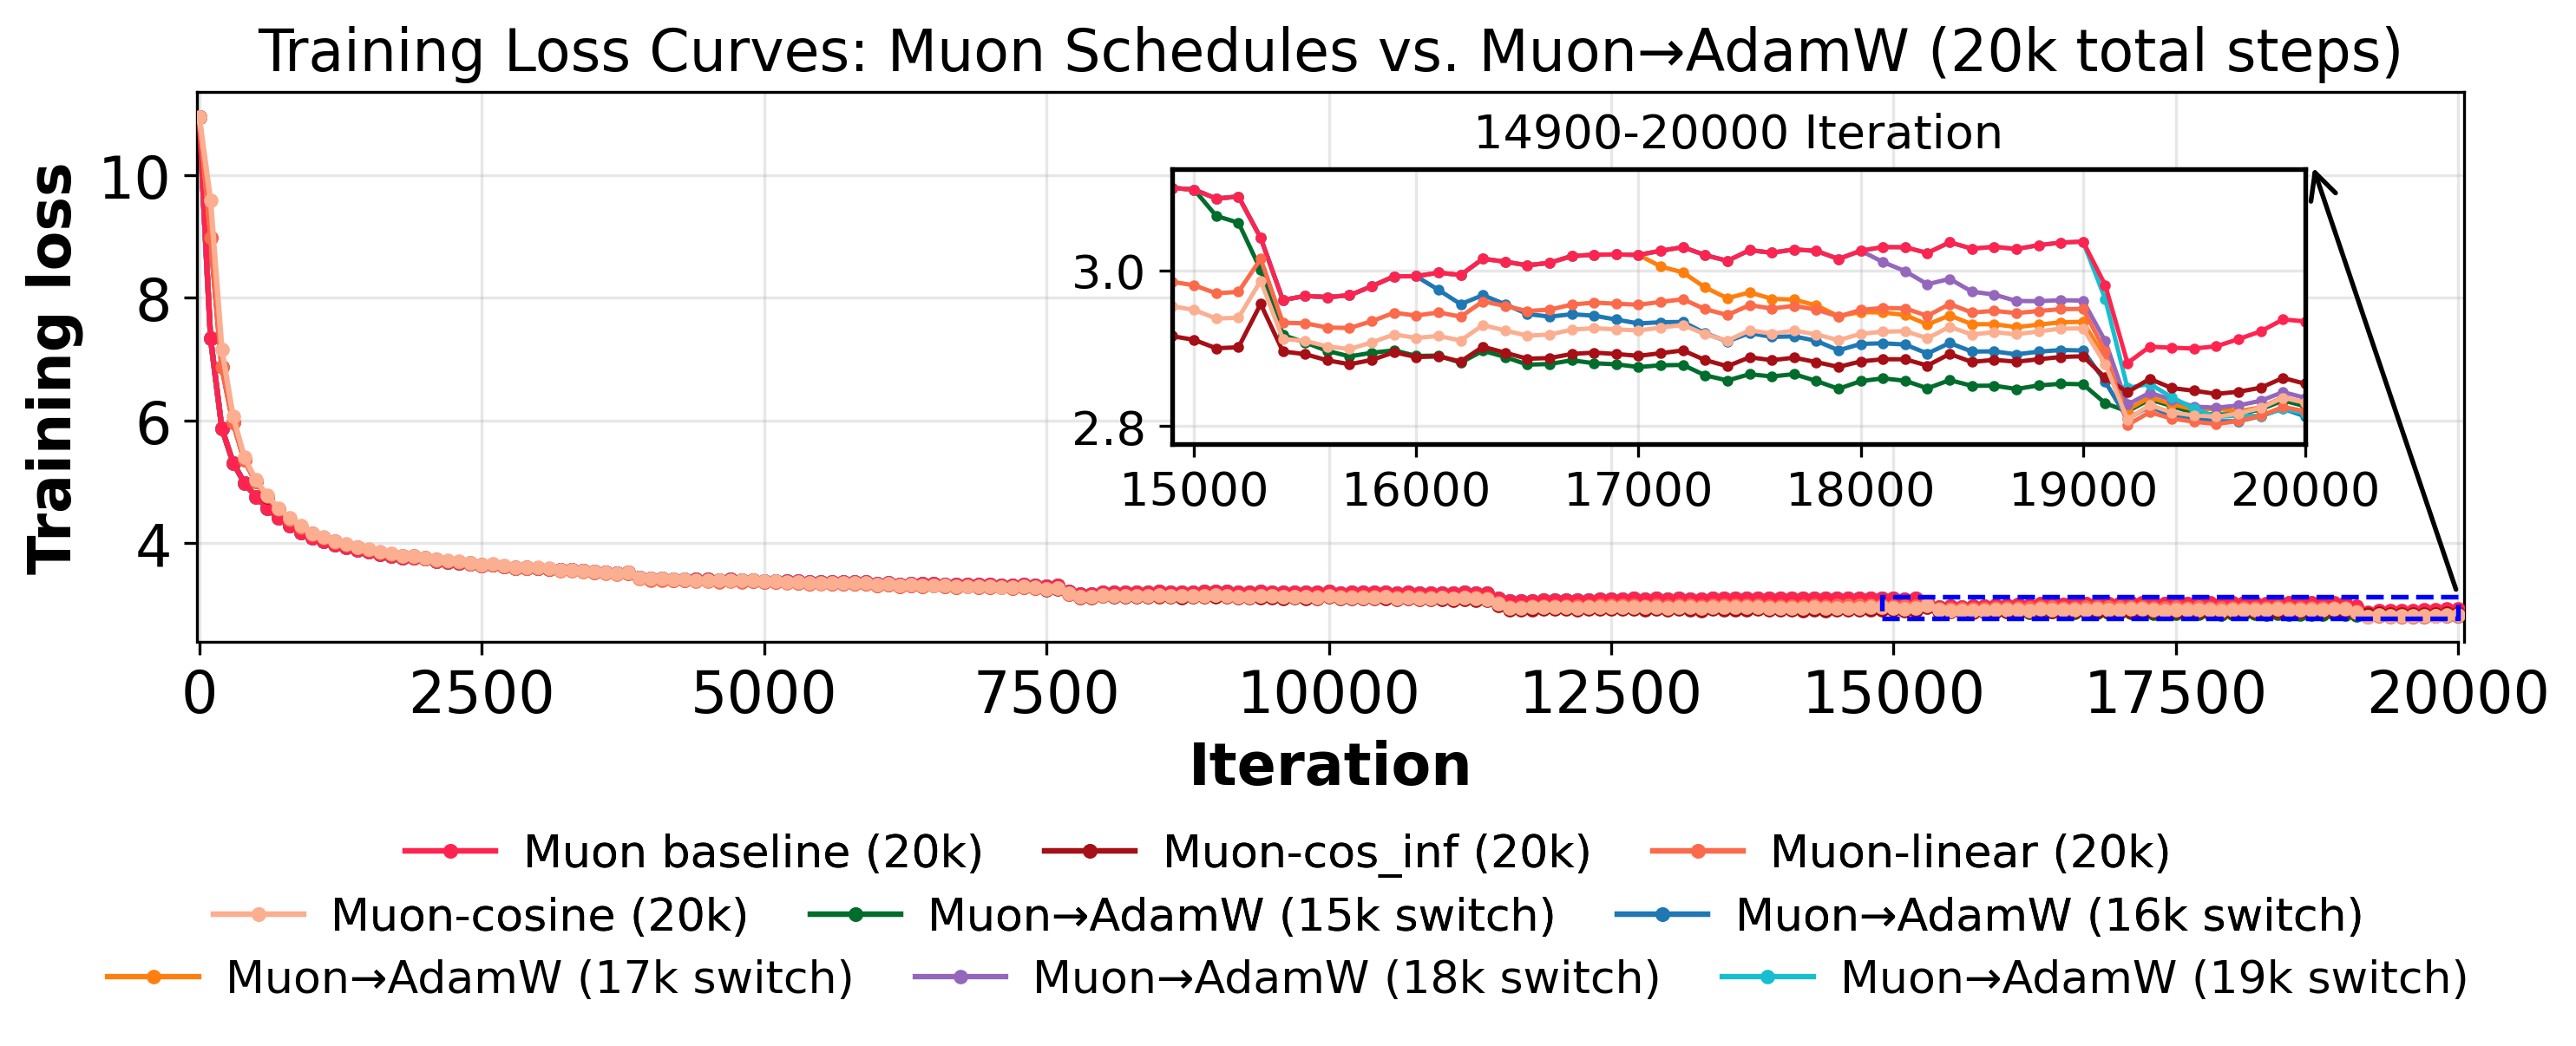

Saved vector PDF to: muon_adamw_20k_train_loss.pdf


In [34]:
# Run from the directory containing this notebook and muon20k+adamwTrain.csv.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

csv_path_train_20k = "llm_pretrain_lr_scheduler/muon20k+adamwTrain.csv"
df_train_20k = pd.read_csv(csv_path_train_20k)
x_col_train_20k = "iter"
muon_baseline_col_train_20k = "2muon20k - train/loss"
df_train_20k[x_col_train_20k] = pd.to_numeric(
    df_train_20k[x_col_train_20k], errors="coerce"
)
df_train_20k = df_train_20k.dropna(subset=[x_col_train_20k]).sort_values(x_col_train_20k)

total_steps_train_20k = int(df_train_20k[x_col_train_20k].max())
if total_steps_train_20k != 20000:
    raise ValueError(
        f"Expected a 20,000-step run, found max iteration {total_steps_train_20k}."
    )

# Include all four Muon-only schedules available in the training-loss CSV.
muon_curve_specs_train_20k = [
    {
        "label": "Muon baseline (20k)",
        "column": "2muon20k - train/loss",
        "color": "#ff244f",
    },
    {
        "label": "Muon-cos_inf (20k)",
        "column": "2muon20kcf - train/loss",
        "color": "#a50f15",
    },
    {
        "label": "Muon-linear (20k)",
        "column": "2muon20klinear - train/loss",
        "color": "#fb6a4a",
    },
    {
        "label": "Muon-cosine (20k)",
        "column": "2muon20kcos - train/loss",
        "color": "#fcae91",
    },
]
hybrid_curve_specs_train_20k = [
    {
        "label": "Muon→AdamW (15k switch)",
        "column": "2muon15000+adamwcf - train/loss",
        "switch_iter": 15000,
        "color": "#006d2c",
    },
    {
        "label": "Muon→AdamW (16k switch)",
        "column": "2muon16000+adamw9e5cf - train/loss",
        "switch_iter": 16000,
        "color": "#1f77b4",
    },
    {
        "label": "Muon→AdamW (17k switch)",
        "column": "2muon17000+adamw9e5cf2 - train/loss",
        "switch_iter": 17000,
        "color": "#ff7f0e",
    },
    {
        "label": "Muon→AdamW (18k switch)",
        "column": "2muon18000+adamwcf - train/loss",
        "switch_iter": 18000,
        "color": "#9467bd",
    },
    {
        "label": "Muon→AdamW (19k switch)",
        "column": "2muon19000+adamw - train/loss",
        "switch_iter": 19000,
        "color": "#17becf",
    },
]

required_cols_train_20k = [
    spec["column"]
    for spec in muon_curve_specs_train_20k + hybrid_curve_specs_train_20k
]
missing_cols_train_20k = [
    column for column in required_cols_train_20k if column not in df_train_20k.columns
]
if missing_cols_train_20k:
    raise KeyError(f"Missing required training-loss columns: {missing_cols_train_20k}")

def get_curve_train_20k(column):
    data = df_train_20k[[x_col_train_20k, column]].copy()
    data[column] = pd.to_numeric(data[column], errors="coerce")
    data = data.dropna().sort_values(x_col_train_20k)
    return data[x_col_train_20k].to_numpy(), data[column].to_numpy()

def get_hybrid_curve_train_20k(adamw_col, switch_iter):
    # Follow the constant-Muon training trajectory up to the switch, then the
    # corresponding AdamW continuation. Keep the AdamW value at a shared point.
    pre = df_train_20k[[x_col_train_20k, muon_baseline_col_train_20k]].copy()
    pre[muon_baseline_col_train_20k] = pd.to_numeric(
        pre[muon_baseline_col_train_20k], errors="coerce"
    )
    pre = pre.dropna()
    pre = pre[pre[x_col_train_20k] <= switch_iter]
    pre = pre.rename(columns={muon_baseline_col_train_20k: "loss"})

    post = df_train_20k[[x_col_train_20k, adamw_col]].copy()
    post[adamw_col] = pd.to_numeric(post[adamw_col], errors="coerce")
    post = post.dropna()
    post = post[post[x_col_train_20k] >= switch_iter]
    post = post.rename(columns={adamw_col: "loss"})

    combo = pd.concat([pre, post], ignore_index=True)
    combo = combo.sort_values(x_col_train_20k, kind="stable")
    combo = combo.drop_duplicates(subset=[x_col_train_20k], keep="last")
    return combo[x_col_train_20k].to_numpy(), combo["loss"].to_numpy()

for spec in muon_curve_specs_train_20k:
    x, y = get_curve_train_20k(spec["column"])
    if x.size == 0 or x[0] != 0 or x[-1] != total_steps_train_20k:
        raise ValueError(
            f"{spec['column']!r} must cover iterations 0 through "
            f"{total_steps_train_20k}."
        )
    spec["x"], spec["y"] = x, y

for spec in hybrid_curve_specs_train_20k:
    branch_x, _ = get_curve_train_20k(spec["column"])
    if branch_x.size == 0:
        raise ValueError(f"No training-loss data found in {spec['column']!r}.")
    actual_switch = int(branch_x[0])
    if actual_switch != spec["switch_iter"]:
        raise ValueError(
            f"{spec['column']!r} starts at {actual_switch}, "
            f"but the configured switch is {spec['switch_iter']}."
        )
    if branch_x[-1] != total_steps_train_20k:
        raise ValueError(
            f"{spec['column']!r} does not reach iteration {total_steps_train_20k}."
        )
    spec["x"], spec["y"] = get_hybrid_curve_train_20k(
        spec["column"], actual_switch
    )

print(
    f"Loaded {len(muon_curve_specs_train_20k)} Muon schedules and "
    f"{len(hybrid_curve_specs_train_20k)} Muon→AdamW branches through "
    f"iteration {total_steps_train_20k}."
)

fig, ax = plt.subplots(figsize=(10, 4))

# Plot hybrids first and Muon-only runs afterward, matching the validation plot.
for spec in hybrid_curve_specs_train_20k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=2,
    )
for spec in muon_curve_specs_train_20k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=3,
    )

ax.set_title(
    "Training Loss Curves: Muon Schedules vs. Muon→AdamW (20k total steps)",
    fontsize=16,
)
ax.set_xlabel("Iteration", fontsize=16, fontweight="bold")
ax.set_ylabel("Training loss", fontsize=16, fontweight="bold")
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)

max_iter_train_20k = int(df_train_20k[x_col_train_20k].max())
ax.set_xlim(-20.0, float(max_iter_train_20k) + 50.0)
ax.spines["bottom"].set_bounds(0, max_iter_train_20k)
ax.set_yticks([4, 6, 8, 10])
zoom_x0_train_20k = 14900
zoom_x1_train_20k = max_iter_train_20k
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])

for spec in hybrid_curve_specs_train_20k + muon_curve_specs_train_20k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_train_20k) & (x <= zoom_x1_train_20k)
    axins.plot(
        x[in_zoom], y[in_zoom],
        marker="o", markersize=2, linewidth=1.2, color=spec["color"],
    )
axins.set_title(
    f"{zoom_x0_train_20k}-{zoom_x1_train_20k} Iteration", fontsize=13
)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0_train_20k, zoom_x1_train_20k)

all_zoom_values_train_20k = []
for spec in hybrid_curve_specs_train_20k + muon_curve_specs_train_20k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_train_20k) & (x <= zoom_x1_train_20k)
    all_zoom_values_train_20k.append(y[in_zoom])
zoom_values_train_20k = np.concatenate(
    [values for values in all_zoom_values_train_20k if values.size > 0]
)
zoom_values_train_20k = zoom_values_train_20k[np.isfinite(zoom_values_train_20k)]
y_min_train_20k, y_max_train_20k = (
    zoom_values_train_20k.min(), zoom_values_train_20k.max()
)
y_margin_train_20k = (
    (y_max_train_20k - y_min_train_20k) * 0.08
    if y_max_train_20k > y_min_train_20k else 1e-6
)
zoom_y0_train_20k = y_min_train_20k - y_margin_train_20k
zoom_y1_train_20k = y_max_train_20k + y_margin_train_20k
axins.set_ylim(zoom_y0_train_20k, zoom_y1_train_20k)

for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

rect_x0_train_20k = max(0, zoom_x0_train_20k)
rect_x1_train_20k = min(max_iter_train_20k, zoom_x1_train_20k)
rect_y0_train_20k = zoom_y0_train_20k - 0.25 * y_margin_train_20k
rect_y1_train_20k = zoom_y1_train_20k + 0.25 * y_margin_train_20k
rect = Rectangle(
    (rect_x0_train_20k, rect_y0_train_20k),
    rect_x1_train_20k - rect_x0_train_20k,
    rect_y1_train_20k - rect_y0_train_20k,
    fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20,
)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1_train_20k, rect_y1_train_20k),
    coordsA=ax.transData,
    xyB=(1.005, 1.03),
    coordsB=axins.transAxes,
    axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
)
fig.add_artist(arrow)

fig.tight_layout()
fig.subplots_adjust(bottom=0.37)
handles, labels = ax.get_legend_handles_labels()
handle_map_train_20k = dict(zip(labels, handles))
legend_rows_train_20k = [
    ["Muon baseline (20k)", "Muon-cos_inf (20k)", "Muon-linear (20k)"],
    ["Muon-cosine (20k)", "Muon→AdamW (15k switch)", "Muon→AdamW (16k switch)"],
    ["Muon→AdamW (17k switch)", "Muon→AdamW (18k switch)", "Muon→AdamW (19k switch)"],
]
legend_y_anchors_train_20k = [0.105, 0.045, -0.015]
previous_legend = None
for row_index, row_labels in enumerate(legend_rows_train_20k):
    legend = fig.legend(
        [handle_map_train_20k[label] for label in row_labels],
        row_labels,
        loc="lower center", ncol=3, frameon=False, fontsize=12.5,
        bbox_to_anchor=(0.5, legend_y_anchors_train_20k[row_index]),
        columnspacing=1.35, handletextpad=0.6,
    )
    if previous_legend is not None:
        fig.add_artist(previous_legend)
    previous_legend = legend

output_pdf_train_20k = "muon_adamw_20k_train_loss.pdf"
fig.savefig(output_pdf_train_20k, dpi=300, format="pdf", bbox_inches="tight")
plt.show()
print(f"Saved vector PDF to: {output_pdf_train_20k}")
plt.close()


### All 20k Muon schedules vs. Muon→AdamW validation-loss curves

This plot shows all nine validation-loss curves from `muon20k+adamwVAL.csv`, with the same curve set and color mapping as the 20k training-loss plot. The inset covers iterations 14,900–20,000 so the 15k switch is visible.

Loaded 4 Muon schedules and 5 Muon→AdamW branches through iteration 20000.


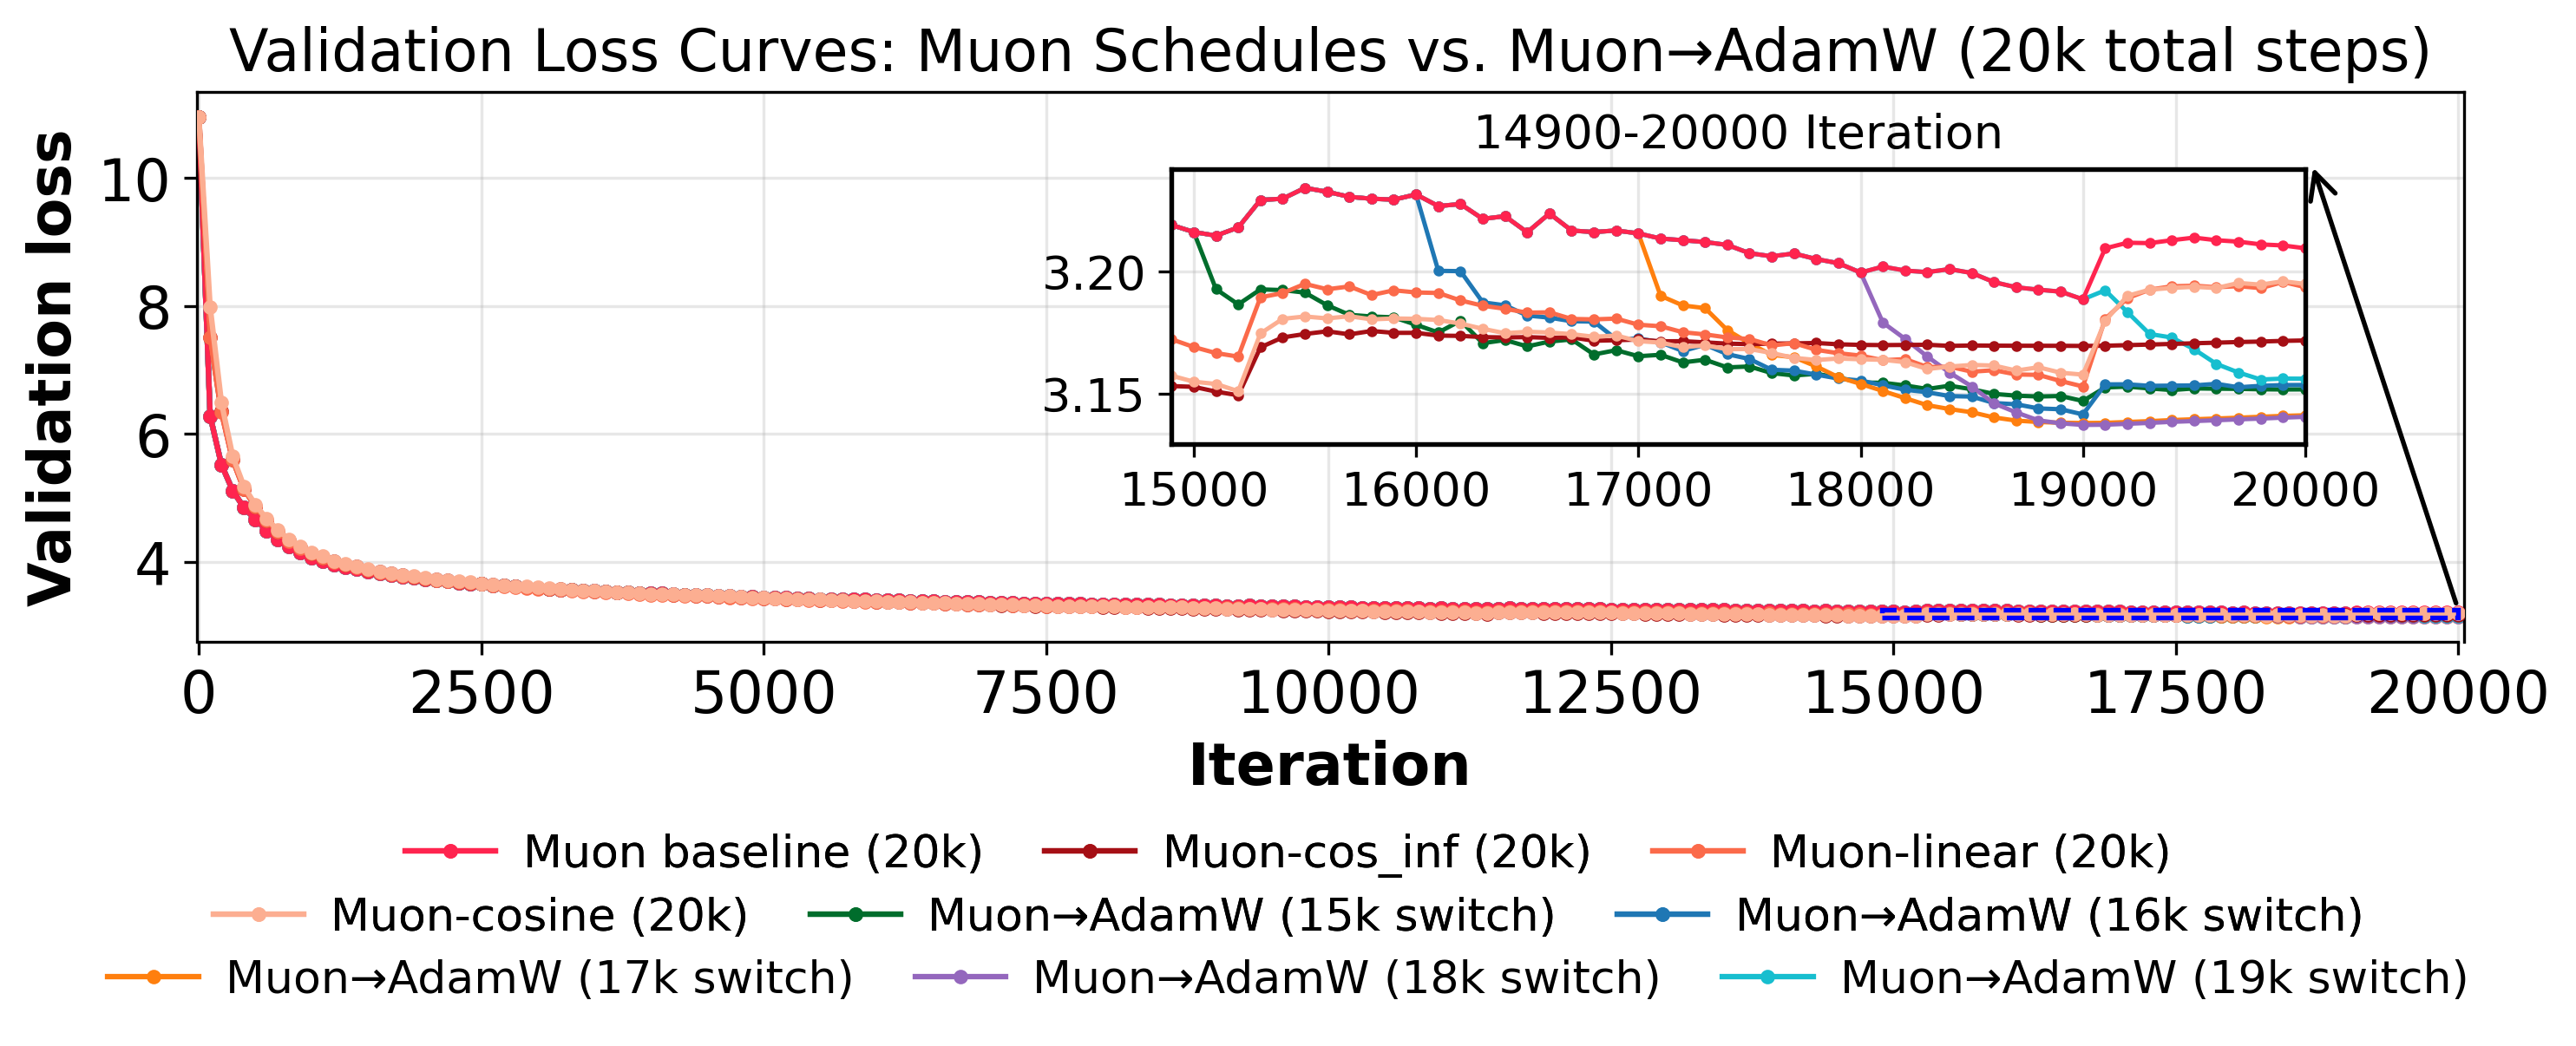

Saved vector PDF to: muon_adamw_20k_val_loss_all.pdf


In [35]:
# Run from the directory containing this notebook and muon20k+adamwVAL.csv.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

csv_path_val_all_20k = "llm_pretrain_lr_scheduler/muon20k+adamwVAL.csv"
df_val_all_20k = pd.read_csv(csv_path_val_all_20k)
x_col_val_all_20k = "iter"
muon_baseline_col_val_all_20k = "2muon20k - val/loss"
df_val_all_20k[x_col_val_all_20k] = pd.to_numeric(
    df_val_all_20k[x_col_val_all_20k], errors="coerce"
)
df_val_all_20k = df_val_all_20k.dropna(
    subset=[x_col_val_all_20k]
).sort_values(x_col_val_all_20k)

total_steps_val_all_20k = int(df_val_all_20k[x_col_val_all_20k].max())
if total_steps_val_all_20k != 20000:
    raise ValueError(
        f"Expected a 20,000-step run, found max iteration {total_steps_val_all_20k}."
    )

# Use exactly the same algorithm colors and curve labels as the training-loss plot.
muon_curve_specs_val_all_20k = [
    {
        "label": "Muon baseline (20k)",
        "column": "2muon20k - val/loss",
        "color": "#ff244f",
    },
    {
        "label": "Muon-cos_inf (20k)",
        "column": "2muon20kcf - val/loss",
        "color": "#a50f15",
    },
    {
        "label": "Muon-linear (20k)",
        "column": "2muon20klinear - val/loss",
        "color": "#fb6a4a",
    },
    {
        "label": "Muon-cosine (20k)",
        "column": "2muon20kcos - val/loss",
        "color": "#fcae91",
    },
]
hybrid_curve_specs_val_all_20k = [
    {
        "label": "Muon→AdamW (15k switch)",
        "column": "2muon15000+adamwcf - val/loss",
        "switch_iter": 15000,
        "color": "#006d2c",
    },
    {
        "label": "Muon→AdamW (16k switch)",
        "column": "2muon16000+adamw9e5cf - val/loss",
        "switch_iter": 16000,
        "color": "#1f77b4",
    },
    {
        "label": "Muon→AdamW (17k switch)",
        "column": "2muon17000+adamw9e5cf2 - val/loss",
        "switch_iter": 17000,
        "color": "#ff7f0e",
    },
    {
        "label": "Muon→AdamW (18k switch)",
        "column": "2muon18000+adamwcf - val/loss",
        "switch_iter": 18000,
        "color": "#9467bd",
    },
    {
        "label": "Muon→AdamW (19k switch)",
        "column": "2muon19000+adamw - val/loss",
        "switch_iter": 19000,
        "color": "#17becf",
    },
]

required_cols_val_all_20k = [
    spec["column"]
    for spec in muon_curve_specs_val_all_20k + hybrid_curve_specs_val_all_20k
]
missing_cols_val_all_20k = [
    column for column in required_cols_val_all_20k
    if column not in df_val_all_20k.columns
]
if missing_cols_val_all_20k:
    raise KeyError(f"Missing required validation-loss columns: {missing_cols_val_all_20k}")

def get_curve_val_all_20k(column):
    data = df_val_all_20k[[x_col_val_all_20k, column]].copy()
    data[column] = pd.to_numeric(data[column], errors="coerce")
    data = data.dropna().sort_values(x_col_val_all_20k)
    return data[x_col_val_all_20k].to_numpy(), data[column].to_numpy()

def get_hybrid_curve_val_all_20k(adamw_col, switch_iter):
    # Reuse the constant-Muon validation path through the switch, then append
    # the corresponding AdamW continuation. Keep AdamW's value at the switch.
    pre = df_val_all_20k[[x_col_val_all_20k, muon_baseline_col_val_all_20k]].copy()
    pre[muon_baseline_col_val_all_20k] = pd.to_numeric(
        pre[muon_baseline_col_val_all_20k], errors="coerce"
    )
    pre = pre.dropna()
    pre = pre[pre[x_col_val_all_20k] <= switch_iter]
    pre = pre.rename(columns={muon_baseline_col_val_all_20k: "loss"})

    post = df_val_all_20k[[x_col_val_all_20k, adamw_col]].copy()
    post[adamw_col] = pd.to_numeric(post[adamw_col], errors="coerce")
    post = post.dropna()
    post = post[post[x_col_val_all_20k] >= switch_iter]
    post = post.rename(columns={adamw_col: "loss"})

    combo = pd.concat([pre, post], ignore_index=True)
    combo = combo.sort_values(x_col_val_all_20k, kind="stable")
    combo = combo.drop_duplicates(subset=[x_col_val_all_20k], keep="last")
    return combo[x_col_val_all_20k].to_numpy(), combo["loss"].to_numpy()

for spec in muon_curve_specs_val_all_20k:
    x, y = get_curve_val_all_20k(spec["column"])
    if x.size == 0 or x[0] != 0 or x[-1] != total_steps_val_all_20k:
        raise ValueError(
            f"{spec['column']!r} must cover iterations 0 through "
            f"{total_steps_val_all_20k}."
        )
    spec["x"], spec["y"] = x, y

for spec in hybrid_curve_specs_val_all_20k:
    branch_x, _ = get_curve_val_all_20k(spec["column"])
    if branch_x.size == 0:
        raise ValueError(f"No validation-loss data found in {spec['column']!r}.")
    actual_switch = int(branch_x[0])
    if actual_switch != spec["switch_iter"]:
        raise ValueError(
            f"{spec['column']!r} starts at {actual_switch}, "
            f"but the configured switch is {spec['switch_iter']}."
        )
    if branch_x[-1] != total_steps_val_all_20k:
        raise ValueError(
            f"{spec['column']!r} does not reach iteration {total_steps_val_all_20k}."
        )
    spec["x"], spec["y"] = get_hybrid_curve_val_all_20k(
        spec["column"], actual_switch
    )

print(
    f"Loaded {len(muon_curve_specs_val_all_20k)} Muon schedules and "
    f"{len(hybrid_curve_specs_val_all_20k)} Muon→AdamW branches through "
    f"iteration {total_steps_val_all_20k}."
)

fig, ax = plt.subplots(figsize=(10, 4))
for spec in hybrid_curve_specs_val_all_20k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=2,
    )
for spec in muon_curve_specs_val_all_20k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=3,
    )

ax.set_title(
    "Validation Loss Curves: Muon Schedules vs. Muon→AdamW (20k total steps)",
    fontsize=16,
)
ax.set_xlabel("Iteration", fontsize=16, fontweight="bold")
ax.set_ylabel("Validation loss", fontsize=16, fontweight="bold")
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)

max_iter_val_all_20k = int(df_val_all_20k[x_col_val_all_20k].max())
ax.set_xlim(-20.0, float(max_iter_val_all_20k) + 50.0)
ax.spines["bottom"].set_bounds(0, max_iter_val_all_20k)
ax.set_xticks(np.arange(0, max_iter_val_all_20k + 1, 2500))
ax.set_yticks([4, 6, 8, 10])
zoom_x0_val_all_20k = 14900
zoom_x1_val_all_20k = max_iter_val_all_20k
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])

all_val_curves_20k = hybrid_curve_specs_val_all_20k + muon_curve_specs_val_all_20k
for spec in all_val_curves_20k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_val_all_20k) & (x <= zoom_x1_val_all_20k)
    axins.plot(
        x[in_zoom], y[in_zoom],
        marker="o", markersize=2, linewidth=1.2, color=spec["color"],
    )
axins.set_title(
    f"{zoom_x0_val_all_20k}-{zoom_x1_val_all_20k} Iteration", fontsize=13
)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0_val_all_20k, zoom_x1_val_all_20k)

zoom_values_val_all_20k = []
for spec in all_val_curves_20k:
    x = np.asarray(spec["x"])
    y = np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_val_all_20k) & (x <= zoom_x1_val_all_20k)
    zoom_values_val_all_20k.append(y[in_zoom])
zoom_values_val_all_20k = np.concatenate(
    [values for values in zoom_values_val_all_20k if values.size > 0]
)
zoom_values_val_all_20k = zoom_values_val_all_20k[np.isfinite(zoom_values_val_all_20k)]
y_min_val_all_20k = zoom_values_val_all_20k.min()
y_max_val_all_20k = zoom_values_val_all_20k.max()
y_margin_val_all_20k = (
    (y_max_val_all_20k - y_min_val_all_20k) * 0.08
    if y_max_val_all_20k > y_min_val_all_20k else 1e-6
)
zoom_y0_val_all_20k = y_min_val_all_20k - y_margin_val_all_20k
zoom_y1_val_all_20k = y_max_val_all_20k + y_margin_val_all_20k
axins.set_ylim(zoom_y0_val_all_20k, zoom_y1_val_all_20k)

for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

rect_x0_val_all_20k = max(0, zoom_x0_val_all_20k)
rect_x1_val_all_20k = min(max_iter_val_all_20k, zoom_x1_val_all_20k)
rect_y0_val_all_20k = zoom_y0_val_all_20k - 0.25 * y_margin_val_all_20k
rect_y1_val_all_20k = zoom_y1_val_all_20k + 0.25 * y_margin_val_all_20k
rect = Rectangle(
    (rect_x0_val_all_20k, rect_y0_val_all_20k),
    rect_x1_val_all_20k - rect_x0_val_all_20k,
    rect_y1_val_all_20k - rect_y0_val_all_20k,
    fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20,
)
ax.add_patch(rect)
arrow = ConnectionPatch(
    xyA=(rect_x1_val_all_20k, rect_y1_val_all_20k),
    coordsA=ax.transData,
    xyB=(1.005, 1.03),
    coordsB=axins.transAxes,
    axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
)
fig.add_artist(arrow)

fig.tight_layout()
fig.subplots_adjust(bottom=0.37)
handle_map_val_all_20k = {
    spec["label"]: ax.lines[index]
    for index, spec in enumerate(hybrid_curve_specs_val_all_20k + muon_curve_specs_val_all_20k)
}
legend_rows_val_all_20k = [
    ["Muon baseline (20k)", "Muon-cos_inf (20k)", "Muon-linear (20k)"],
    ["Muon-cosine (20k)", "Muon→AdamW (15k switch)", "Muon→AdamW (16k switch)"],
    ["Muon→AdamW (17k switch)", "Muon→AdamW (18k switch)", "Muon→AdamW (19k switch)"],
]
legend_y_anchors_val_all_20k = [0.105, 0.045, -0.015]
previous_legend_val_all_20k = None
for row_index, row_labels in enumerate(legend_rows_val_all_20k):
    legend = fig.legend(
        [handle_map_val_all_20k[label] for label in row_labels],
        row_labels,
        loc="lower center", ncol=3, frameon=False, fontsize=12.5,
        bbox_to_anchor=(0.5, legend_y_anchors_val_all_20k[row_index]),
        columnspacing=1.35, handletextpad=0.6,
    )
    if previous_legend_val_all_20k is not None:
        fig.add_artist(previous_legend_val_all_20k)
    previous_legend_val_all_20k = legend

output_pdf_val_all_20k = "muon_adamw_20k_val_loss_all.pdf"
fig.savefig(output_pdf_val_all_20k, dpi=300, format="pdf", bbox_inches="tight")
plt.show()
print(f"Saved vector PDF to: {output_pdf_val_all_20k}")
plt.close()


### Combined 20k training and validation-loss curves

Run this cell after the all-curve training-loss and validation-loss cells above. It stacks training loss over validation loss, hides the upper panel’s main x-axis ticks and label, and uses one shared legend for all nine algorithms. Both insets cover iterations 14,900–20,000.

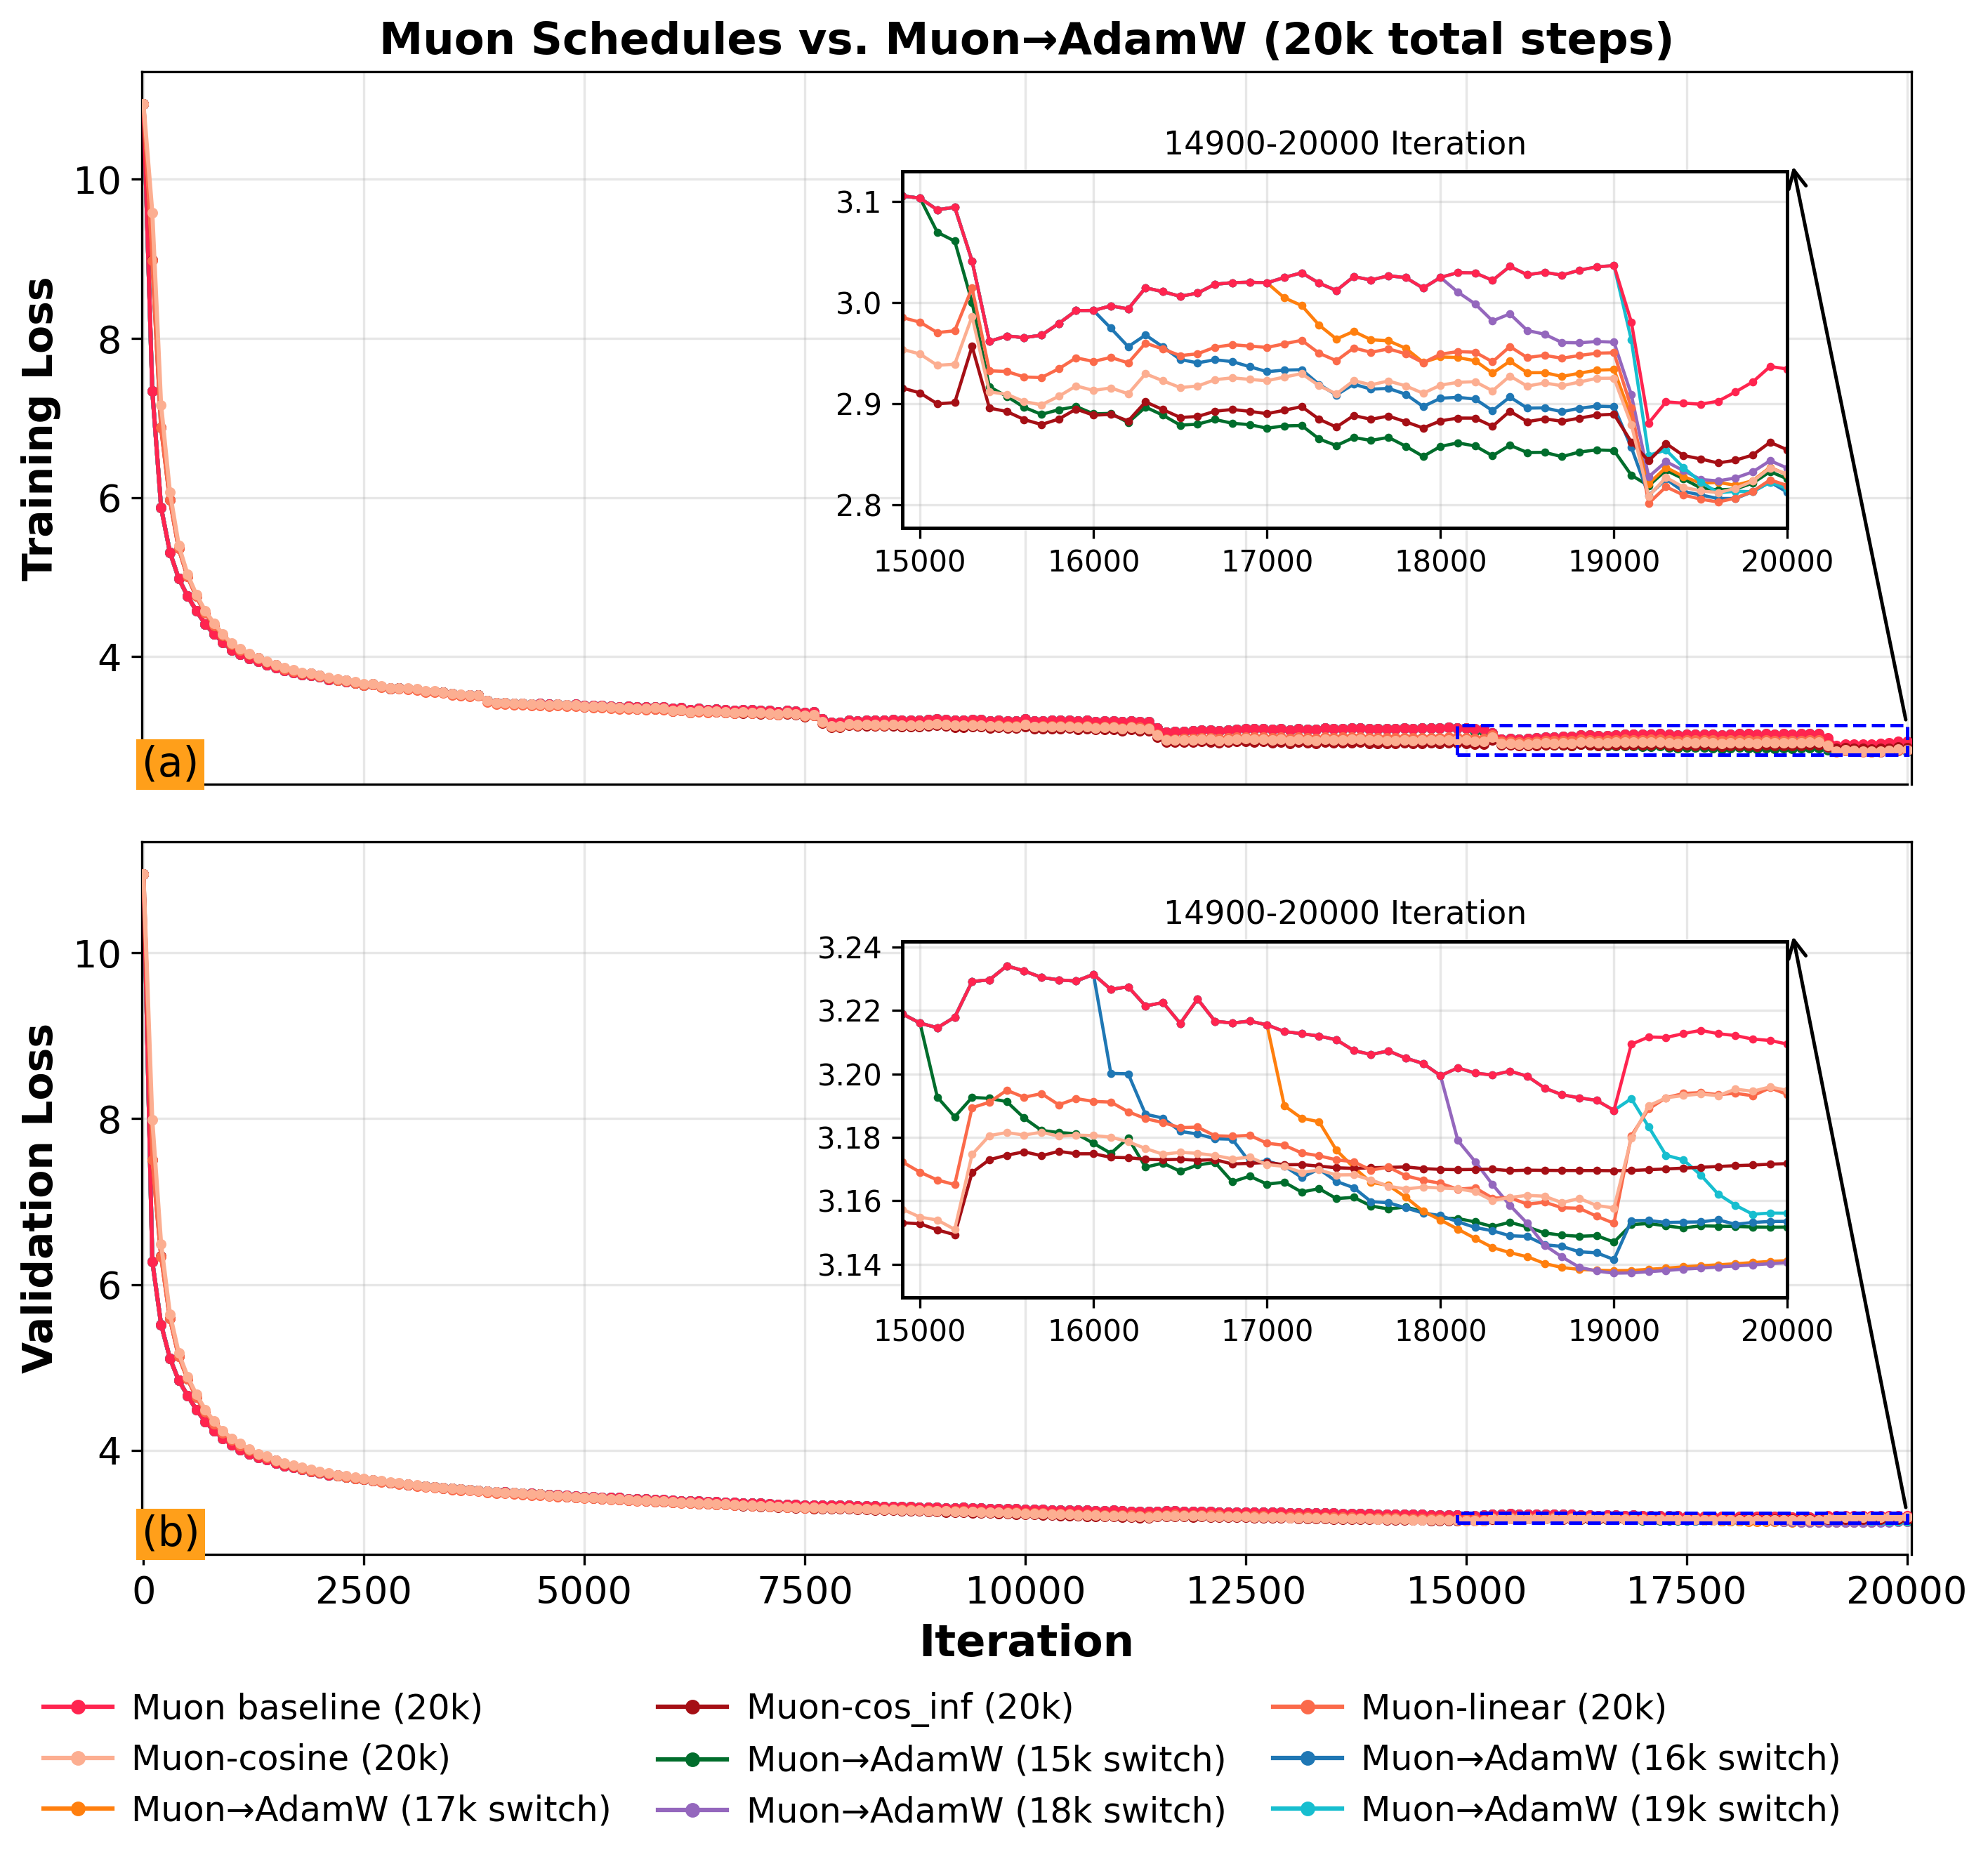

Saved vector PDF to: muon_adamw_20k_train_val_loss_combined.pdf
Panels: training loss on top, validation loss below; one shared legend.


In [36]:
# Run after the 20k all-curve training-loss and validation-loss cells above.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

train_muon_specs = muon_curve_specs_train_20k
train_hybrid_specs = hybrid_curve_specs_train_20k
val_muon_specs = muon_curve_specs_val_all_20k
val_hybrid_specs = hybrid_curve_specs_val_all_20k

train_color_map = {
    spec["label"]: spec["color"] for spec in train_muon_specs + train_hybrid_specs
}
val_color_map = {
    spec["label"]: spec["color"] for spec in val_muon_specs + val_hybrid_specs
}
if train_color_map != val_color_map:
    raise ValueError("Training and validation curves must use identical labels and colors.")
if len(train_color_map) != 9:
    raise ValueError(f"Expected nine matching algorithms, found {len(train_color_map)}.")

fig, (ax_train, ax_val) = plt.subplots(
    2, 1, figsize=(10, 8.8), sharex=True
)


def draw_loss_panel(ax, muon_specs, hybrid_specs, ylabel, panel_label, hide_main_xaxis=False):
    all_specs = hybrid_specs + muon_specs
    for spec in hybrid_specs:
        ax.plot(
            spec["x"], spec["y"],
            marker="o", markersize=2.6, linewidth=1.4,
            color=spec["color"], zorder=2,
        )
    for spec in muon_specs:
        ax.plot(
            spec["x"], spec["y"],
            marker="o", markersize=2.6, linewidth=1.4,
            color=spec["color"], zorder=3,
        )

    if ylabel == "Training Loss":
        ax.set_title(
            "Muon Schedules vs. Muon→AdamW (20k total steps)",
            fontsize=15, fontweight="bold",
        )
    else:
        ax.set_title("")
    ax.set_ylabel(ylabel, fontsize=14, fontweight="bold")
    ax.tick_params(axis="both", labelsize=13)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-20.0, 20050.0)
    ax.spines["bottom"].set_bounds(0, 20000)
    ax.set_xticks(np.arange(0, 20001, 2500))
    ax.set_yticks([4, 6, 8, 10])
    if hide_main_xaxis:
        ax.set_xlabel("")
        ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    else:
        ax.set_xlabel("Iteration", fontsize=15, fontweight="bold")

    zoom_x0, zoom_x1 = 14900, 20000
    axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])
    for spec in all_specs:
        x = np.asarray(spec["x"])
        y = np.asarray(spec["y"])
        in_zoom = (x >= zoom_x0) & (x <= zoom_x1)
        axins.plot(
            x[in_zoom], y[in_zoom],
            marker="o", markersize=1.8, linewidth=1.1, color=spec["color"],
        )
    axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=11)
    axins.tick_params(axis="both", labelsize=10)
    axins.grid(True, alpha=0.3)
    axins.set_xlim(zoom_x0, zoom_x1)

    zoom_values = []
    for spec in all_specs:
        x = np.asarray(spec["x"])
        y = np.asarray(spec["y"])
        in_zoom = (x >= zoom_x0) & (x <= zoom_x1)
        zoom_values.append(y[in_zoom])
    zoom_values = np.concatenate([values for values in zoom_values if values.size > 0])
    zoom_values = zoom_values[np.isfinite(zoom_values)]
    y_min, y_max = zoom_values.min(), zoom_values.max()
    y_margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
    zoom_y0, zoom_y1 = y_min - y_margin, y_max + y_margin
    axins.set_ylim(zoom_y0, zoom_y1)
    for spine in axins.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)

    rect_y0 = zoom_y0 - 0.25 * y_margin
    rect_y1 = zoom_y1 + 0.25 * y_margin
    rect = Rectangle(
        (zoom_x0, rect_y0), zoom_x1 - zoom_x0, rect_y1 - rect_y0,
        fill=False, edgecolor="blue", linewidth=1.2, linestyle="--", zorder=20,
    )
    ax.add_patch(rect)
    arrow = ConnectionPatch(
        xyA=(zoom_x1, rect_y1), coordsA=ax.transData,
        xyB=(1.005, 1.03), coordsB=axins.transAxes,
        axesA=ax, axesB=axins,
        arrowstyle="->", mutation_scale=15, linewidth=1.2, color="black",
        shrinkA=2, shrinkB=2, clip_on=False,
    )
    fig.add_artist(arrow)
    ax.text(
        0.0, 0.0, panel_label, transform=ax.transAxes,
        ha="left", va="bottom", fontsize=14, color="black",
        bbox={"facecolor": "#ff9f1a", "edgecolor": "none", "pad": 1.8},
    )


draw_loss_panel(
    ax_train, train_muon_specs, train_hybrid_specs,
    "Training Loss", "(a)", hide_main_xaxis=True,
)
draw_loss_panel(
    ax_val, val_muon_specs, val_hybrid_specs,
    "Validation Loss", "(b)", hide_main_xaxis=False,
)

# One shared legend for both panels. Reorder handles for three row-wise groups
# because Matplotlib arranges a multi-column legend column by column.
legend_rows = [
    ["Muon baseline (20k)", "Muon-cos_inf (20k)", "Muon-linear (20k)"],
    ["Muon-cosine (20k)", "Muon→AdamW (15k switch)", "Muon→AdamW (16k switch)"],
    ["Muon→AdamW (17k switch)", "Muon→AdamW (18k switch)", "Muon→AdamW (19k switch)"],
]
legend_labels = [legend_rows[row][column] for column in range(3) for row in range(3)]
legend_handles = [
    Line2D([], [], color=train_color_map[label], marker="o", linewidth=1.5, markersize=4)
    for label in legend_labels
]
fig.subplots_adjust(left=0.12, right=0.96, top=0.97, bottom=0.17, hspace=0.08)
fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=3, frameon=False, fontsize=11.8,
    bbox_to_anchor=(0.5, 0.005), columnspacing=1.35, handletextpad=0.55,
)

output_pdf_train_val_20k = "muon_adamw_20k_train_val_loss_combined.pdf"
fig.savefig(
    output_pdf_train_val_20k, dpi=300, format="pdf", bbox_inches="tight",
    metadata={"Title": "20k Training and Validation Loss Curves: Muon Schedules vs. Muon→AdamW"},
)
plt.show()
print(f"Saved vector PDF to: {output_pdf_train_val_20k}")
print("Panels: training loss on top, validation loss below; one shared legend.")
plt.close()


### 15k Training and Validation Loss Curves

This section plots the 15k training loss and combines it above the matching validation-loss panel. Both panels use the same six algorithms and colors. The combined figure keeps the shared legend and the main iteration axis below, following the 20k training/validation layout; both insets cover iterations 9,900–15,000.


Loaded the 15k training baseline and 5 Muon→AdamW branches through iteration 15000.


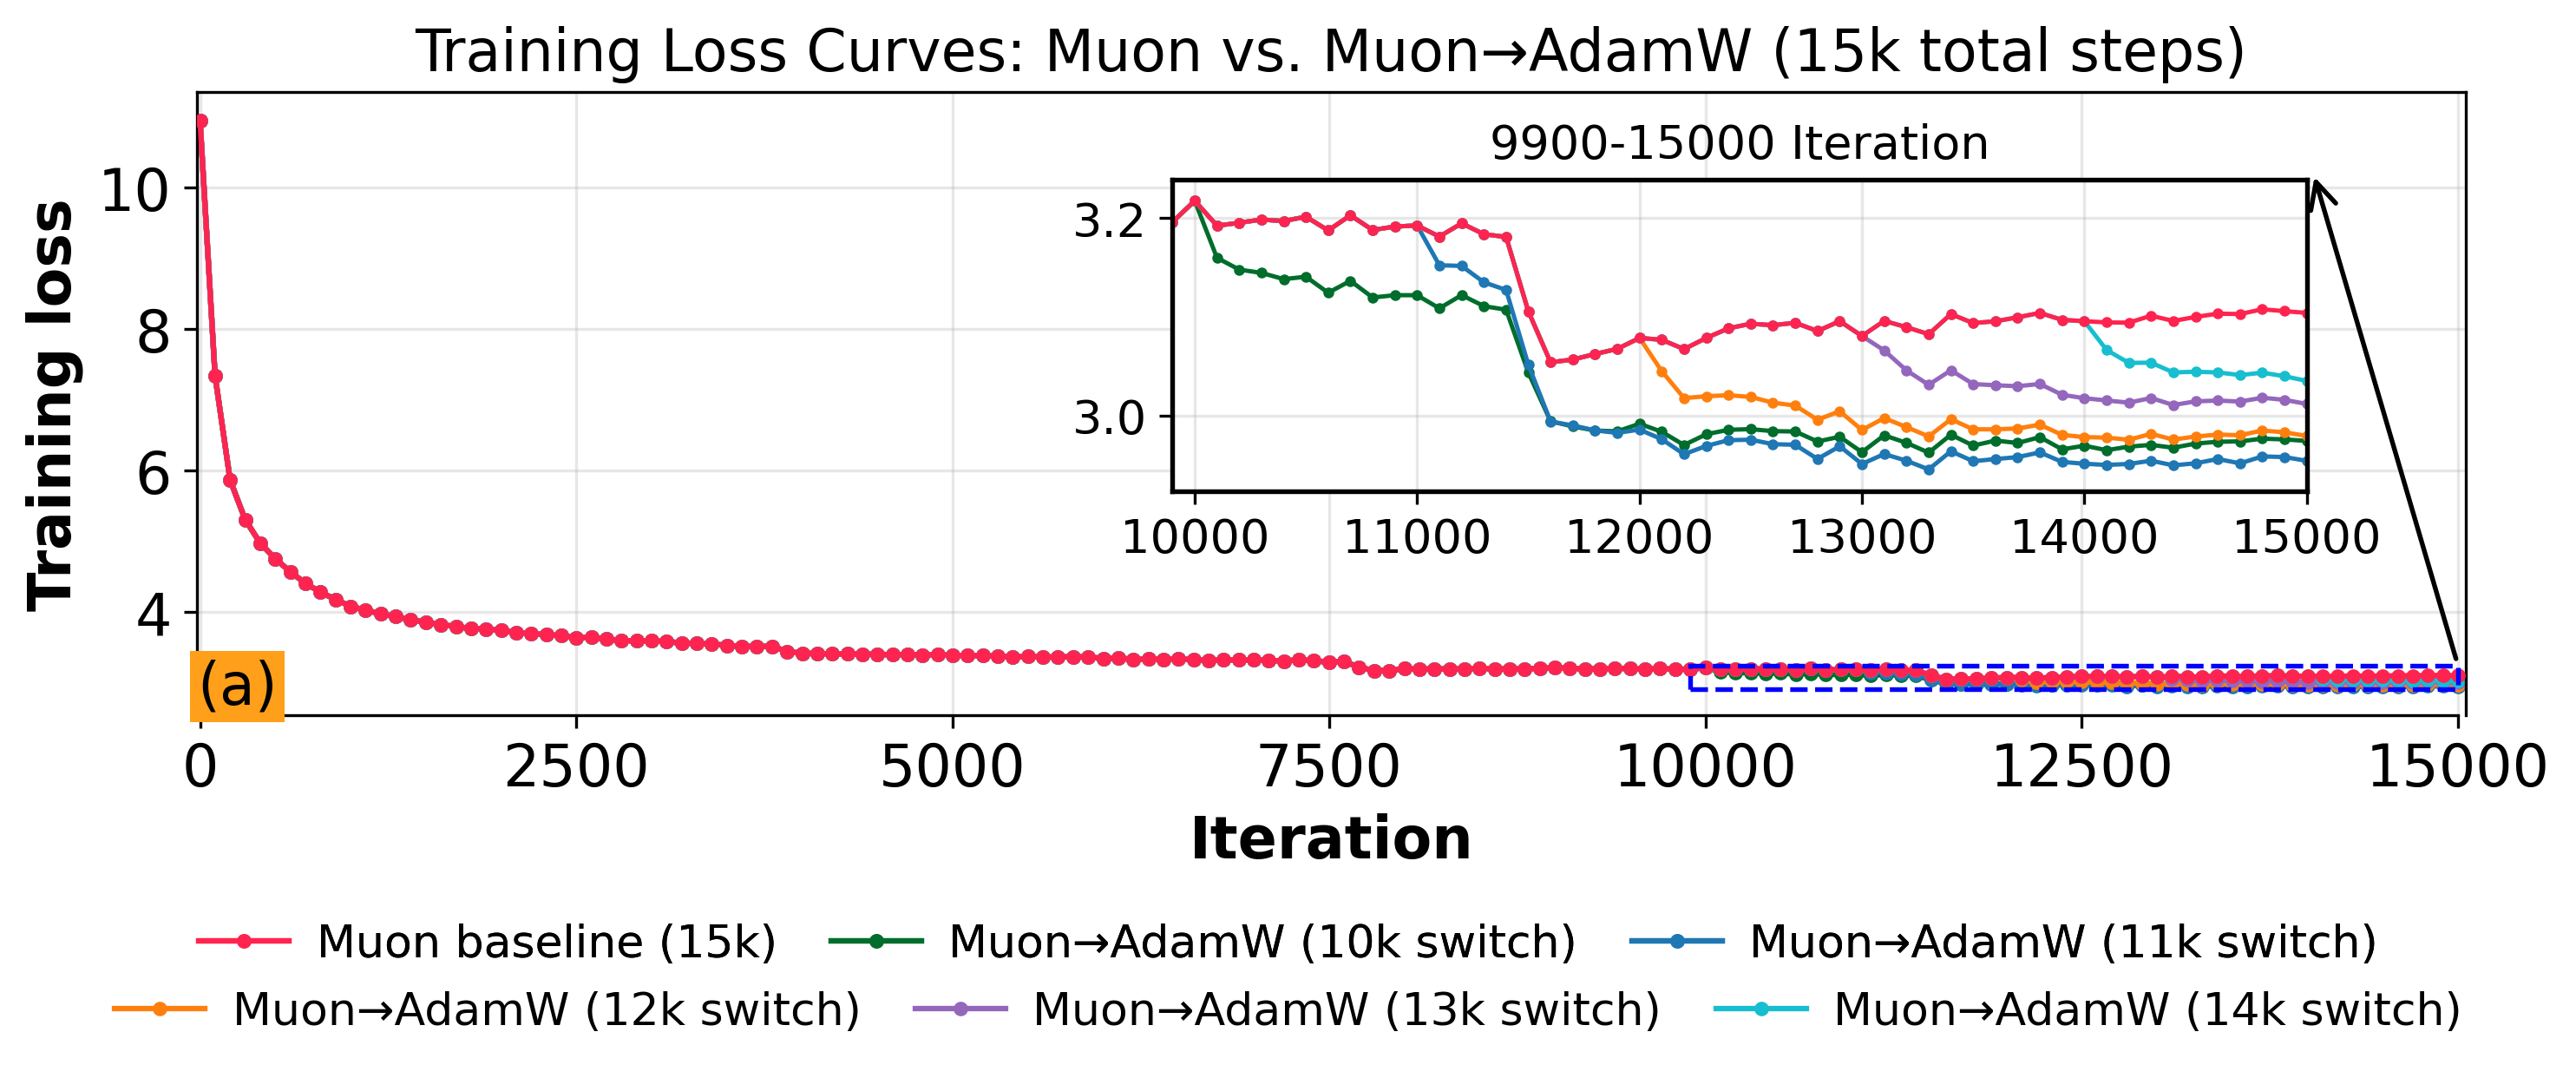

Saved vector PDF to: muon_adamw_15k_train_loss.pdf


In [37]:
# Run after the 15k validation-loss cells above.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

if "curve_specs_15k" not in globals() or "muon_x_15k" not in globals():
    raise RuntimeError("Run the 15k validation-loss data cell before this cell.")

csv_path_train_15k = "llm_pretrain_lr_scheduler/muon+adamw15kTrain.csv"
df_train_15k = pd.read_csv(csv_path_train_15k)
x_col_train_15k = "iter"
baseline_col_train_15k = baseline_col_15k.replace("val/loss", "train/loss")
df_train_15k[x_col_train_15k] = pd.to_numeric(
    df_train_15k[x_col_train_15k], errors="coerce"
)
df_train_15k = df_train_15k.dropna(
    subset=[x_col_train_15k]
).sort_values(x_col_train_15k)

total_steps_train_15k = int(df_train_15k[x_col_train_15k].max())
if total_steps_train_15k != 15000:
    raise ValueError(
        f"Expected a 15,000-step training run, found max iteration {total_steps_train_15k}."
    )

# Reuse the validation panel's labels, switch points, and colors verbatim.
curve_specs_train_15k = [
    {
        "label": val_spec["label"],
        "column": val_spec["column"].replace("val/loss", "train/loss"),
        "switch_iter": val_spec["switch_iter"],
        "color": val_spec["color"],
    }
    for val_spec in curve_specs_15k
]
required_cols_train_15k = [baseline_col_train_15k] + [
    spec["column"] for spec in curve_specs_train_15k
]
missing_cols_train_15k = [
    column for column in required_cols_train_15k if column not in df_train_15k.columns
]
if missing_cols_train_15k:
    raise KeyError(f"Missing required training-loss columns: {missing_cols_train_15k}")

def get_curve_train_15k(column):
    data = df_train_15k[[x_col_train_15k, column]].copy()
    data[column] = pd.to_numeric(data[column], errors="coerce")
    data = data.dropna().sort_values(x_col_train_15k)
    return data[x_col_train_15k].to_numpy(), data[column].to_numpy()

def get_hybrid_curve_train_15k(adamw_col, switch_iter):
    # Join the shared Muon trajectory through the switch to the AdamW continuation.
    pre = df_train_15k[[x_col_train_15k, baseline_col_train_15k]].copy()
    pre[baseline_col_train_15k] = pd.to_numeric(
        pre[baseline_col_train_15k], errors="coerce"
    )
    pre = pre.dropna()
    pre = pre[pre[x_col_train_15k] <= switch_iter]
    pre = pre.rename(columns={baseline_col_train_15k: "loss"})

    post = df_train_15k[[x_col_train_15k, adamw_col]].copy()
    post[adamw_col] = pd.to_numeric(post[adamw_col], errors="coerce")
    post = post.dropna()
    post = post[post[x_col_train_15k] >= switch_iter]
    post = post.rename(columns={adamw_col: "loss"})

    # At a duplicated switch iteration, retain the AdamW continuation value.
    combo = pd.concat([pre, post], ignore_index=True)
    combo = combo.sort_values(x_col_train_15k, kind="stable")
    combo = combo.drop_duplicates(subset=[x_col_train_15k], keep="last")
    return combo[x_col_train_15k].to_numpy(), combo["loss"].to_numpy()

muon_x_train_15k, muon_y_train_15k = get_curve_train_15k(baseline_col_train_15k)
if (
    muon_x_train_15k.size == 0
    or muon_x_train_15k[0] != 0
    or muon_x_train_15k[-1] != total_steps_train_15k
):
    raise ValueError("The full Muon training baseline must cover iterations 0 through 15,000.")

for spec in curve_specs_train_15k:
    branch_x, _ = get_curve_train_15k(spec["column"])
    if branch_x.size == 0:
        raise ValueError(f"No training-loss data found in {spec['column']!r}.")
    actual_switch = int(branch_x[0])
    if actual_switch != spec["switch_iter"]:
        raise ValueError(
            f"{spec['column']!r} starts at {actual_switch}, "
            f"but the configured switch is {spec['switch_iter']}."
        )
    if branch_x[-1] != total_steps_train_15k:
        raise ValueError(f"{spec['column']!r} does not reach iteration 15,000.")
    spec["x"], spec["y"] = get_hybrid_curve_train_15k(
        spec["column"], actual_switch
    )

print(
    f"Loaded the 15k training baseline and {len(curve_specs_train_15k)} "
    f"Muon→AdamW branches through iteration {total_steps_train_15k}."
)

# Standalone training-loss PDF, styled to match the existing 15k validation PDF.
fig, ax = plt.subplots(figsize=(10, 4))
for spec in curve_specs_train_15k:
    ax.plot(
        spec["x"], spec["y"],
        marker="o", markersize=3, linewidth=1.5,
        label=spec["label"], color=spec["color"], zorder=2,
    )
ax.plot(
    muon_x_train_15k, muon_y_train_15k,
    marker="o", markersize=3, linewidth=1.5,
    label=baseline_label_15k, color=baseline_color_15k, zorder=4,
)

ax.set_title("Training Loss Curves: Muon vs. Muon→AdamW (15k total steps)", fontsize=16)
ax.set_xlabel("Iteration", fontsize=16, fontweight="bold")
ax.set_ylabel("Training loss", fontsize=16, fontweight="bold")
ax.tick_params(axis="both", labelsize=16)
ax.grid(True, alpha=0.3)
ax.text(
    0.0, 0.0, "(a)", transform=ax.transAxes,
    ha="left", va="bottom", fontsize=16, color="black",
    bbox={"facecolor": "#ff9f1a", "edgecolor": "none", "pad": 2.0},
)

max_iter_train_15k = int(df_train_15k[x_col_train_15k].max())
ax.set_xlim(-20.0, float(max_iter_train_15k) + 50.0)
ax.spines["bottom"].set_bounds(0, max_iter_train_15k)
ax.set_xticks(np.arange(0, max_iter_train_15k + 1, 2500))
ax.set_yticks([4, 6, 8, 10])
zoom_x0_train_15k, zoom_x1_train_15k = 9900, max_iter_train_15k
axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])

for spec in curve_specs_train_15k:
    x, y = np.asarray(spec["x"]), np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_train_15k) & (x <= zoom_x1_train_15k)
    axins.plot(
        x[in_zoom], y[in_zoom],
        marker="o", markersize=2, linewidth=1.2, color=spec["color"],
    )
muon_in_zoom_train_15k = (
    (muon_x_train_15k >= zoom_x0_train_15k)
    & (muon_x_train_15k <= zoom_x1_train_15k)
)
axins.plot(
    muon_x_train_15k[muon_in_zoom_train_15k],
    muon_y_train_15k[muon_in_zoom_train_15k],
    marker="o", markersize=2, linewidth=1.2, color=baseline_color_15k,
)
axins.set_title(f"{zoom_x0_train_15k}-{zoom_x1_train_15k} Iteration", fontsize=13)
axins.tick_params(axis="both", labelsize=13)
axins.grid(True, alpha=0.3)
axins.set_xlim(zoom_x0_train_15k, zoom_x1_train_15k)

all_zoom_values_train_15k = [muon_y_train_15k[muon_in_zoom_train_15k]]
for spec in curve_specs_train_15k:
    x, y = np.asarray(spec["x"]), np.asarray(spec["y"])
    in_zoom = (x >= zoom_x0_train_15k) & (x <= zoom_x1_train_15k)
    all_zoom_values_train_15k.append(y[in_zoom])
zoom_values_train_15k = np.concatenate(
    [values for values in all_zoom_values_train_15k if values.size > 0]
)
zoom_values_train_15k = zoom_values_train_15k[np.isfinite(zoom_values_train_15k)]
y_min_train_15k, y_max_train_15k = (
    zoom_values_train_15k.min(), zoom_values_train_15k.max()
)
y_margin_train_15k = (
    (y_max_train_15k - y_min_train_15k) * 0.08
    if y_max_train_15k > y_min_train_15k else 1e-6
)
zoom_y0_train_15k = y_min_train_15k - y_margin_train_15k
zoom_y1_train_15k = y_max_train_15k + y_margin_train_15k
axins.set_ylim(zoom_y0_train_15k, zoom_y1_train_15k)
for spine in axins.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.3)

rect_x0_train_15k = max(0, zoom_x0_train_15k)
rect_x1_train_15k = min(max_iter_train_15k, zoom_x1_train_15k)
rect_y0_train_15k = zoom_y0_train_15k - 0.25 * y_margin_train_15k
rect_y1_train_15k = zoom_y1_train_15k + 0.25 * y_margin_train_15k
ax.add_patch(Rectangle(
    (rect_x0_train_15k, rect_y0_train_15k),
    rect_x1_train_15k - rect_x0_train_15k,
    rect_y1_train_15k - rect_y0_train_15k,
    fill=False, edgecolor="blue", linewidth=1.3, linestyle="--", zorder=20,
))
fig.add_artist(ConnectionPatch(
    xyA=(rect_x1_train_15k, rect_y1_train_15k), coordsA=ax.transData,
    xyB=(1.005, 1.03), coordsB=axins.transAxes,
    axesA=ax, axesB=axins,
    arrowstyle="->", mutation_scale=18, linewidth=1.3, color="black",
    shrinkA=2, shrinkB=2, clip_on=False,
))

fig.tight_layout()
fig.subplots_adjust(bottom=0.30)
handles, labels = ax.get_legend_handles_labels()
handle_map_train_15k = dict(zip(labels, handles))
legend_rows_train_15k = [
    [baseline_label_15k, "Muon→AdamW (10k switch)", "Muon→AdamW (11k switch)"],
    ["Muon→AdamW (12k switch)", "Muon→AdamW (13k switch)", "Muon→AdamW (14k switch)"],
]
legend1 = fig.legend(
    [handle_map_train_15k[label] for label in legend_rows_train_15k[0]],
    legend_rows_train_15k[0],
    loc="lower center", ncol=3, frameon=False, fontsize=12.5,
    bbox_to_anchor=(0.5, 0.02), columnspacing=1.2, handletextpad=0.6,
)
fig.add_artist(legend1)
fig.legend(
    [handle_map_train_15k[label] for label in legend_rows_train_15k[1]],
    legend_rows_train_15k[1],
    loc="lower center", ncol=3, frameon=False, fontsize=12.5,
    bbox_to_anchor=(0.5, -0.045), columnspacing=1.2, handletextpad=0.6,
)

output_pdf_train_15k = "muon_adamw_15k_train_loss.pdf"
fig.savefig(
    output_pdf_train_15k, dpi=300, format="pdf", bbox_inches="tight",
    metadata={"Title": "15k Training Loss Curves: Muon vs. Muon→AdamW"},
)
plt.show()
print(f"Saved vector PDF to: {output_pdf_train_15k}")
plt.close(fig)


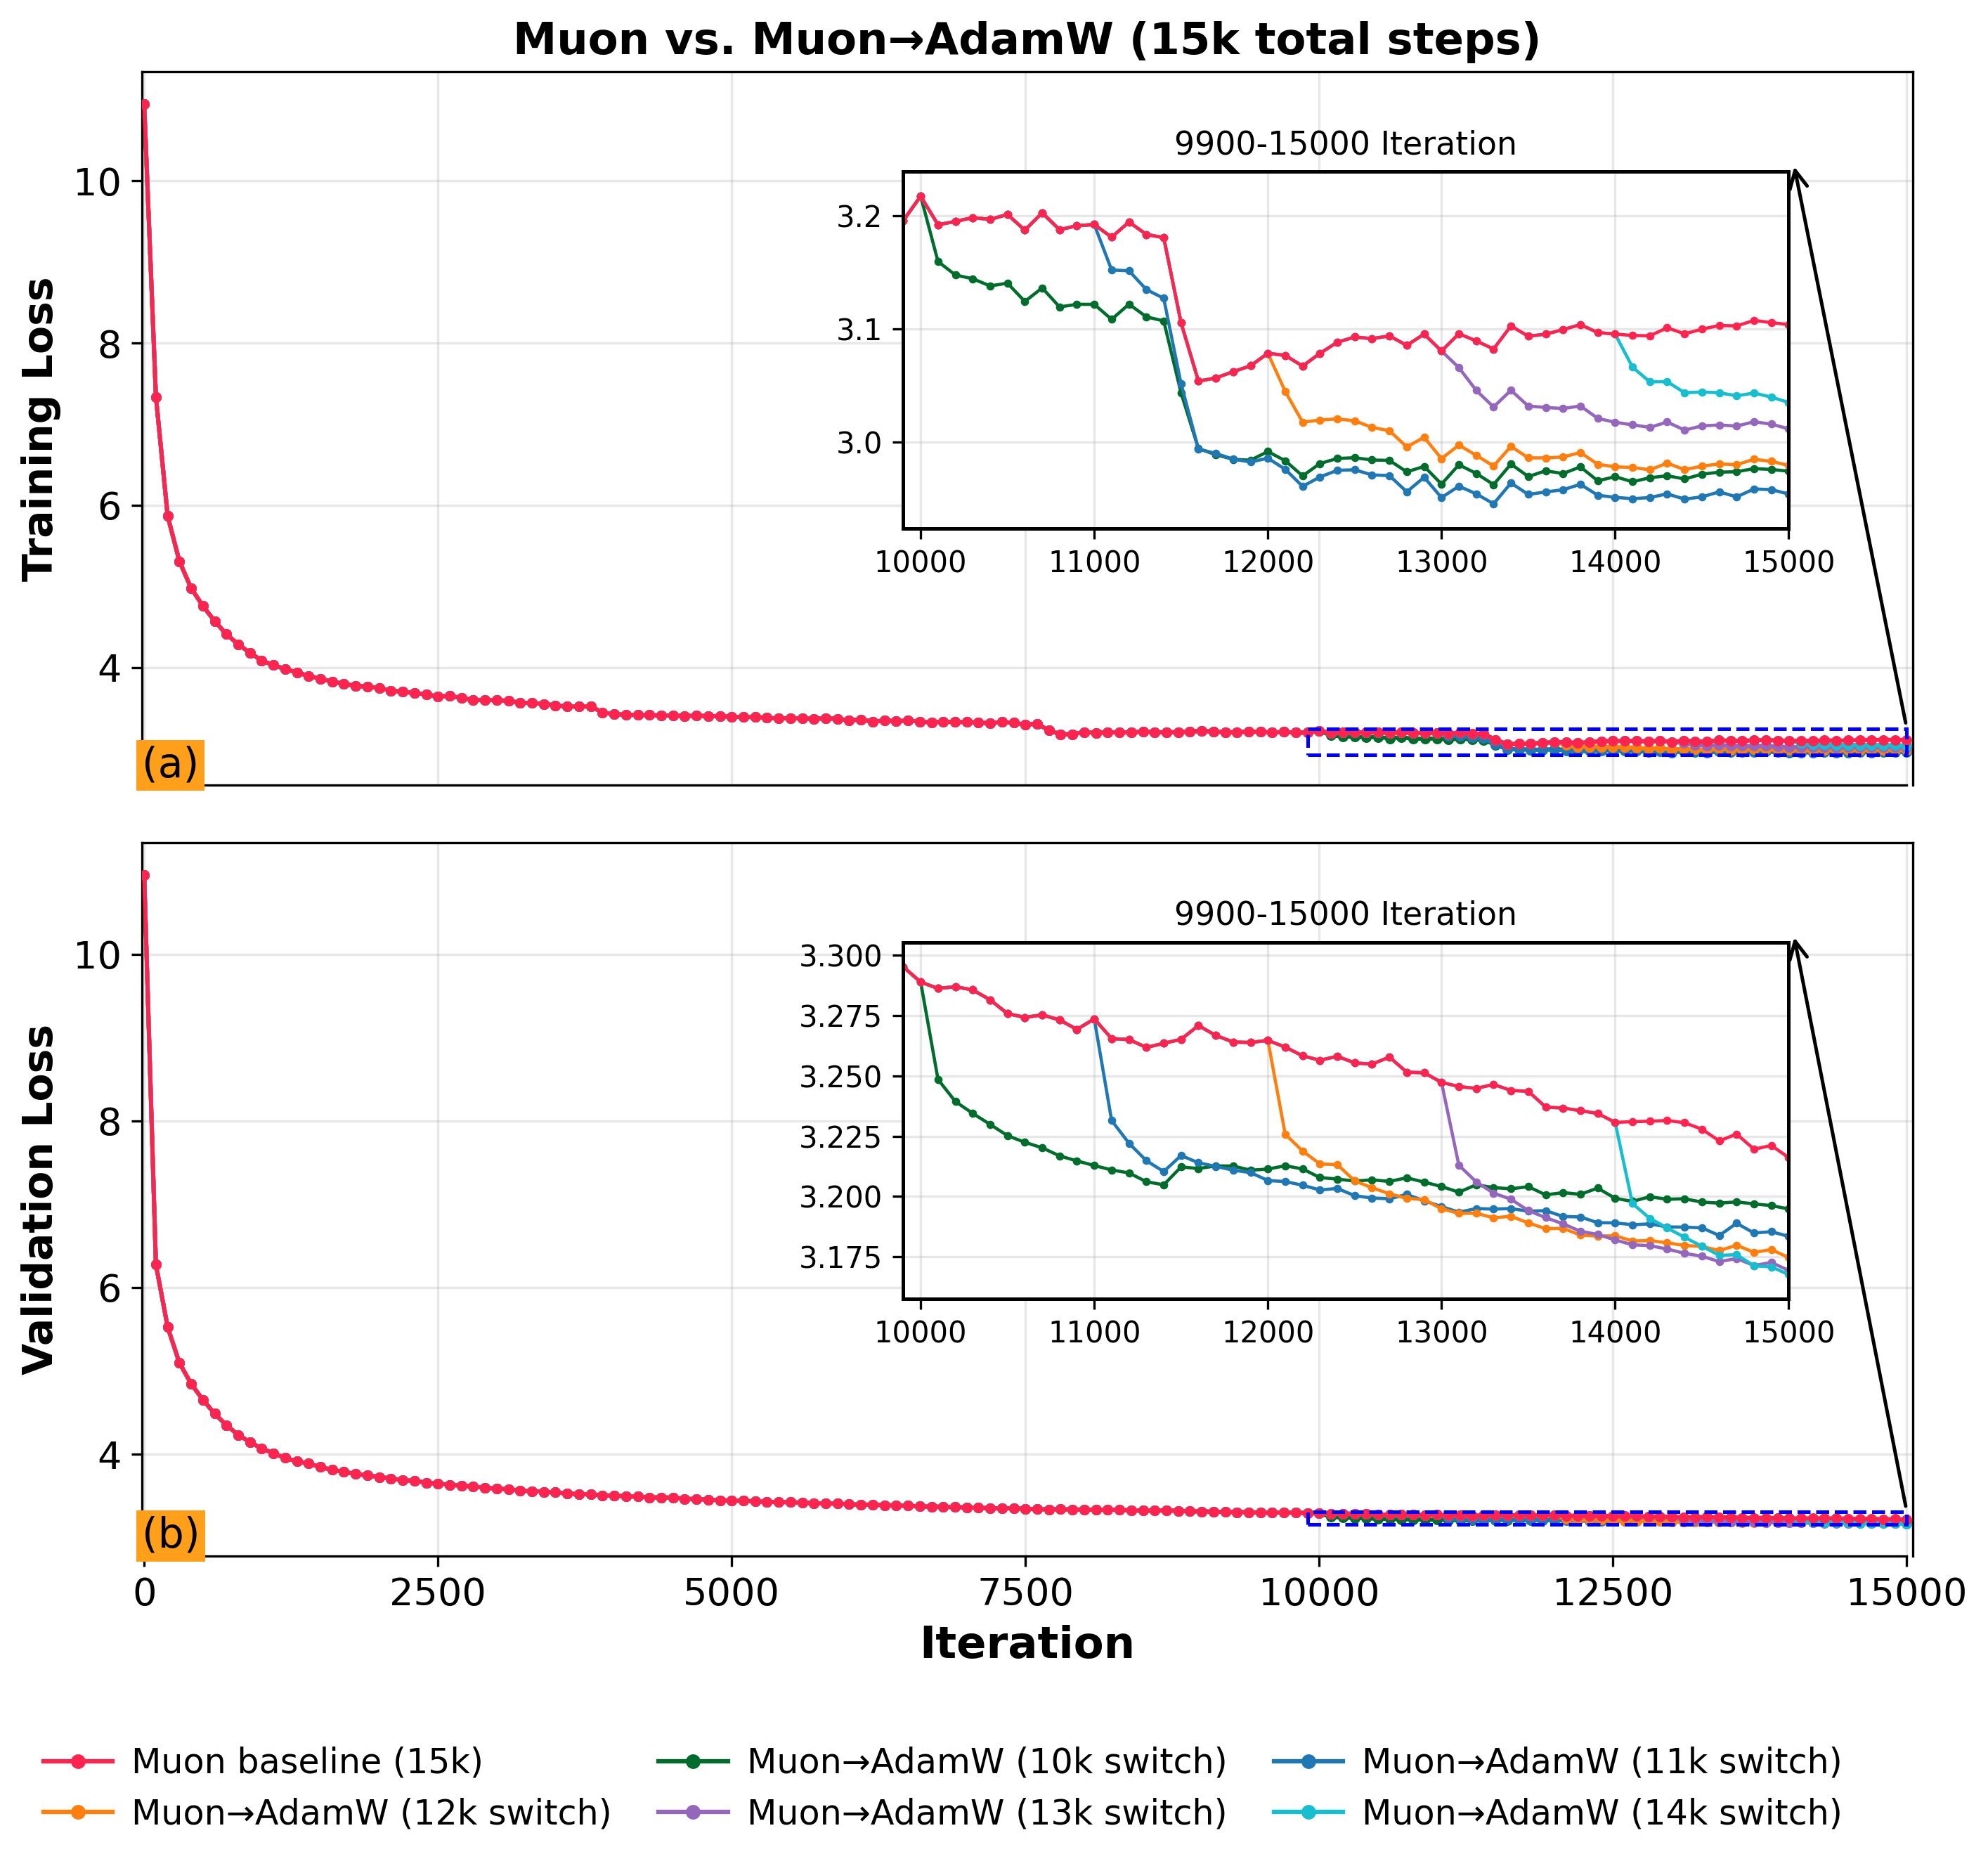

Saved vector PDF to: muon_adamw_15k_train_val_loss_combined.pdf; training is on top, validation is below, with one shared legend.


In [38]:
# Run after the 15k training-loss cell above.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, ConnectionPatch

plt.rcParams["figure.dpi"] = 300
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

train_baseline_spec_15k = {
    "label": baseline_label_15k,
    "x": muon_x_train_15k,
    "y": muon_y_train_15k,
    "color": baseline_color_15k,
}
val_baseline_spec_15k = {
    "label": baseline_label_15k,
    "x": muon_x_15k,
    "y": muon_y_15k,
    "color": baseline_color_15k,
}
train_color_map_15k = {
    spec["label"]: spec["color"]
    for spec in curve_specs_train_15k + [train_baseline_spec_15k]
}
val_color_map_15k = {
    spec["label"]: spec["color"]
    for spec in curve_specs_15k + [val_baseline_spec_15k]
}
if train_color_map_15k != val_color_map_15k:
    raise ValueError("The 15k training and validation curves must share labels and colors.")
if len(train_color_map_15k) != 6:
    raise ValueError(f"Expected six matching 15k algorithms, found {len(train_color_map_15k)}.")

fig, (ax_train, ax_val) = plt.subplots(
    2, 1, figsize=(10, 8.8), sharex=True
)

def draw_loss_panel_15k(ax, hybrid_specs, baseline_spec, ylabel, panel_label,
                        hide_main_xaxis=False):
    all_specs = hybrid_specs + [baseline_spec]
    for spec in hybrid_specs:
        ax.plot(
            spec["x"], spec["y"],
            marker="o", markersize=2.6, linewidth=1.4,
            color=spec["color"], zorder=2,
        )
    ax.plot(
        baseline_spec["x"], baseline_spec["y"],
        marker="o", markersize=2.6, linewidth=1.4,
        color=baseline_spec["color"], zorder=3,
    )

    if ylabel == "Training Loss":
        ax.set_title(
            "Muon vs. Muon→AdamW (15k total steps)",
            fontsize=15, fontweight="bold",
        )
    else:
        ax.set_title("")
    ax.set_ylabel(ylabel, fontsize=14, fontweight="bold")
    ax.tick_params(axis="both", labelsize=13)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-20.0, 15050.0)
    ax.spines["bottom"].set_bounds(0, 15000)
    ax.set_xticks(np.arange(0, 15001, 2500))
    ax.set_yticks([4, 6, 8, 10])
    if hide_main_xaxis:
        ax.set_xlabel("")
        ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    else:
        ax.set_xlabel("Iteration", fontsize=15, fontweight="bold")

    zoom_x0, zoom_x1 = 9900, 15000
    axins = ax.inset_axes([0.43, 0.36, 0.50, 0.50])
    for spec in all_specs:
        x, y = np.asarray(spec["x"]), np.asarray(spec["y"])
        in_zoom = (x >= zoom_x0) & (x <= zoom_x1)
        axins.plot(
            x[in_zoom], y[in_zoom],
            marker="o", markersize=1.8, linewidth=1.1, color=spec["color"],
        )
    axins.set_title(f"{zoom_x0}-{zoom_x1} Iteration", fontsize=11)
    axins.tick_params(axis="both", labelsize=10)
    axins.grid(True, alpha=0.3)
    axins.set_xlim(zoom_x0, zoom_x1)

    zoom_values = []
    for spec in all_specs:
        x, y = np.asarray(spec["x"]), np.asarray(spec["y"])
        in_zoom = (x >= zoom_x0) & (x <= zoom_x1)
        zoom_values.append(y[in_zoom])
    zoom_values = np.concatenate([values for values in zoom_values if values.size > 0])
    zoom_values = zoom_values[np.isfinite(zoom_values)]
    y_min, y_max = zoom_values.min(), zoom_values.max()
    y_margin = (y_max - y_min) * 0.08 if y_max > y_min else 1e-6
    zoom_y0, zoom_y1 = y_min - y_margin, y_max + y_margin
    axins.set_ylim(zoom_y0, zoom_y1)
    for spine in axins.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)

    rect_y0, rect_y1 = zoom_y0 - 0.25 * y_margin, zoom_y1 + 0.25 * y_margin
    ax.add_patch(Rectangle(
        (zoom_x0, rect_y0), zoom_x1 - zoom_x0, rect_y1 - rect_y0,
        fill=False, edgecolor="blue", linewidth=1.2, linestyle="--", zorder=20,
    ))
    fig.add_artist(ConnectionPatch(
        xyA=(zoom_x1, rect_y1), coordsA=ax.transData,
        xyB=(1.005, 1.03), coordsB=axins.transAxes,
        axesA=ax, axesB=axins,
        arrowstyle="->", mutation_scale=15, linewidth=1.2, color="black",
        shrinkA=2, shrinkB=2, clip_on=False,
    ))
    ax.text(
        0.0, 0.0, panel_label, transform=ax.transAxes,
        ha="left", va="bottom", fontsize=14, color="black",
        bbox={"facecolor": "#ff9f1a", "edgecolor": "none", "pad": 1.8},
    )

draw_loss_panel_15k(
    ax_train, curve_specs_train_15k, train_baseline_spec_15k,
    "Training Loss", "(a)", hide_main_xaxis=True,
)
draw_loss_panel_15k(
    ax_val, curve_specs_15k, val_baseline_spec_15k,
    "Validation Loss", "(b)", hide_main_xaxis=False,
)

# Supply legend handles directly from the shared training/validation color map.
legend_rows_15k = [
    [baseline_label_15k, "Muon→AdamW (10k switch)", "Muon→AdamW (11k switch)"],
    ["Muon→AdamW (12k switch)", "Muon→AdamW (13k switch)", "Muon→AdamW (14k switch)"],
]
# Matplotlib fills multi-column legends column-first; order inputs column-first
# so the displayed rows read left-to-right as specified above.
legend_labels_15k = [
    legend_rows_15k[row][column]
    for column in range(3) for row in range(2)
]
legend_handles_15k = [
    Line2D([], [], color=train_color_map_15k[label], marker="o",
           linewidth=1.5, markersize=4)
    for label in legend_labels_15k
]
fig.subplots_adjust(left=0.12, right=0.96, top=0.97, bottom=0.17, hspace=0.08)
fig.legend(
    legend_handles_15k, legend_labels_15k,
    loc="lower center", ncol=3, frameon=False, fontsize=11.8,
    bbox_to_anchor=(0.5, 0.005), columnspacing=1.35, handletextpad=0.55,
)

output_pdf_train_val_15k = "muon_adamw_15k_train_val_loss_combined.pdf"
fig.savefig(
    output_pdf_train_val_15k, dpi=300, format="pdf", bbox_inches="tight",
    metadata={"Title": "15k Training and Validation Loss Curves: Muon vs. Muon→AdamW"},
)
plt.show()
print(
    f"Saved vector PDF to: {output_pdf_train_val_15k}; "
    "training is on top, validation is below, with one shared legend."
)
plt.close(fig)
